# Generative AI — Assignment 2

## Clinical Trial Eligibility Screening Using Transformers

**Environment:** Google Colab

**Dataset:** TrialGPT Criterion Annotations

### Project Objectives
- Fine-tune an open-weight Transformer.
- Predict eligibility labels and evidence.
- Implement KV caching.
- Implement tiled attention.
- Implement speculative decoding.
- Build a browser application.
- Evaluate and document results.

In [1]:
import torch
import sys
import platform

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    total_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(f"GPU memory: {total_memory:.2f} GB")
else:
    print("No GPU detected. Check Colab runtime settings.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [1]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_DIR = Path(
    '/content/drive/MyDrive/GenAI_Assignment_2'
)

folders = [
    'data',
    'models',
    'results',
    'logs',
    'figures',
    'app',
    'report'
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True, exist_ok=True
    )

print("Project directory:", PROJECT_DIR)
print("All project folders created successfully!")

Mounted at /content/drive
Project directory: /content/drive/MyDrive/GenAI_Assignment_2
All project folders created successfully!


# PART 1 — Dataset Preparation

In [6]:
# ============================================================
# STEP 5: Install Required Libraries
# TASK: Dataset Preparation
# ============================================================

%pip -q install -U datasets pandas numpy scikit-learn \
    matplotlib seaborn pyarrow huggingface_hub

print("STEP 5 COMPLETE: Libraries installed!")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
STEP 5 COMPLETE: Libraries installed!


In [3]:
# ============================================================
# STEP 6: Download and Inspect TrialGPT Dataset
# TASK: Dataset Preparation
# ============================================================

from datasets import load_dataset
import pandas as pd
import numpy as np

DATASET_NAME = "ncbi/TrialGPT-Criterion-Annotations"

dataset = load_dataset(DATASET_NAME)

print("Available dataset splits:")
print(dataset)

# Convert the dataset into a Pandas DataFrame
df = dataset["train"].to_pandas()

print("\nTotal annotation records:", len(df))
print("Total unique patients:", df["patient_id"].nunique())

print("\nDataset columns:")
for col in df.columns:
    print("-", col)

print("\nFirst 3 records (selected fields):")

display(df[
    [
        "annotation_id",
        "patient_id",
        "criterion_type",
        "criterion_text",
        "expert_eligibility",
        "expert_sentences"
    ]
].head(3))

print("\nSTEP 6 COMPLETE: Dataset loaded!")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


README.md:   0%|          | 0.00/893 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  176kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1015 [00:00<?, ? examples/s]

Available dataset splits:
DatasetDict({
    train: Dataset({
        features: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'gpt4_explanation', 'explanation_correctness', 'gpt4_sentences', 'expert_sentences', 'gpt4_eligibility', 'expert_eligibility', 'training'],
        num_rows: 1015
    })
})

Total annotation records: 1015
Total unique patients: 53

Dataset columns:
- annotation_id
- patient_id
- note
- trial_id
- trial_title
- criterion_type
- criterion_text
- gpt4_explanation
- explanation_correctness
- gpt4_sentences
- expert_sentences
- gpt4_eligibility
- expert_eligibility
- training

First 3 records (selected fields):


,annotation_id,patient_id,criterion_type,criterion_text,expert_eligibility,expert_sentences
0,0,sigir-20141,inclusion,Patients of chronic stable angina with abnorma...,not enough information,"[0, 1, 2]"
1,1,sigir-20141,inclusion,Male and female,included,[0]
2,2,sigir-20141,inclusion,Age 25 to 65 years,included,[0]



STEP 6 COMPLETE: Dataset loaded!


In [4]:
# ============================================================
# STEP 7: Inspect Labels and Evidence
# TASK: Dataset Preparation
# ============================================================

print("Criterion type distribution:")
print(df["criterion_type"].value_counts())

print("\nEligibility labels by criterion type:")
print(pd.crosstab(
    df["criterion_type"],
    df["expert_eligibility"]
))

print("\nMissing values in important columns:")

important_columns = [
    "patient_id",
    "note",
    "criterion_type",
    "criterion_text",
    "expert_eligibility",
    "expert_sentences"
]

print(df[important_columns].isnull().sum())

print("\nExample patient note:")
print(df.iloc[0]["note"][:1500])

print("\nExample expert evidence:")
print(df.iloc[0]["expert_sentences"])

print("\nEvidence Python type:")
print(type(df.iloc[0]["expert_sentences"]))

print("\nSTEP 7 COMPLETE: Labels inspected!")

Criterion type distribution:
criterion_type
exclusion    659
inclusion    356
Name: count, dtype: int64

Eligibility labels by criterion type:
expert_eligibility  excluded  included  not applicable  \
criterion_type                                           
exclusion                 10         0              46   
inclusion                  0       150               9   

expert_eligibility  not enough information  not excluded  not included  
criterion_type                                                          
exclusion                              119           484             0  
inclusion                              174             0            23  

Missing values in important columns:
patient_id            0
note                  0
criterion_type        0
criterion_text        1
expert_eligibility    0
expert_sentences      0
dtype: int64

Example patient note:
0. A 58-year-old African-American woman presents to the ER with episodic pressing/burning anterior chest pain that

In [7]:
# ============================================================
# STEP 8: Create Patient-Grouped Train/Validation/Test Split
# TASK: Dataset Preparation
# ============================================================

import numpy as np
import pandas as pd

# Get unique patient IDs in sorted order
patient_ids = sorted(df["patient_id"].unique())

print("Total unique patients:", len(patient_ids))

assert len(patient_ids) == 53, "Expected exactly 53 patients!"

# Reproducible random shuffle
rng = np.random.default_rng(42)
shuffled_ids = rng.permutation(patient_ids)

# Required 37/8/8 patient split
train_ids = shuffled_ids[:37].tolist()
val_ids = shuffled_ids[37:45].tolist()
test_ids = shuffled_ids[45:].tolist()

# Create separate DataFrames
train_df = df[df["patient_id"].isin(train_ids)].copy()
val_df = df[df["patient_id"].isin(val_ids)].copy()
test_df = df[df["patient_id"].isin(test_ids)].copy()

# Verify no patient leakage
assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)

assert len(train_ids) == 37
assert len(val_ids) == 8
assert len(test_ids) == 8

print("\nPatient Split Summary")
print("-" * 45)

print(f"Training:   {len(train_ids)} patients, {len(train_df)} records")
print(f"Validation: {len(val_ids)} patients, {len(val_df)} records")
print(f"Testing:    {len(test_ids)} patients, {len(test_df)} records")

print("\nPatient leakage check: PASSED")
print("STEP 8 COMPLETE: Patient-grouped split created!")

Total unique patients: 53

Patient Split Summary
---------------------------------------------
Training:   37 patients, 603 records
Validation: 8 patients, 206 records
Testing:    8 patients, 206 records

Patient leakage check: PASSED
STEP 8 COMPLETE: Patient-grouped split created!


In [8]:
# ============================================================
# STEP 9: Save Split Manifest and Verify Data Integrity
# TASK: Dataset Preparation
# ============================================================

import json
from pathlib import Path

# Build manifest with patient IDs and record counts
manifest_records = []

for split_name, split_ids in [
    ("train", train_ids),
    ("validation", val_ids),
    ("test", test_ids)
]:
    for patient_id in split_ids:

        count = int(
            (df["patient_id"] == patient_id).sum()
        )

        manifest_records.append({
            "patient_id": str(patient_id),
            "split": split_name,
            "annotation_count": count
        })

manifest_df = pd.DataFrame(manifest_records)

# Save CSV manifest
manifest_path = PROJECT_DIR / "data" / "split_manifest.csv"

manifest_df.to_csv(manifest_path, index=False)

# Save JSON manifest with configuration
manifest_json = {
    "dataset": "ncbi/TrialGPT-Criterion-Annotations",
    "random_seed": 42,
    "split_method": "sorted patient IDs + default_rng permutation",
    "train_patient_ids": [str(x) for x in train_ids],
    "validation_patient_ids": [str(x) for x in val_ids],
    "test_patient_ids": [str(x) for x in test_ids],
    "annotation_counts": {
        "train": len(train_df),
        "validation": len(val_df),
        "test": len(test_df)
    }
}

json_path = PROJECT_DIR / "data" / "split_manifest.json"

with open(json_path, "w") as f:
    json.dump(manifest_json, f, indent=4)

# Dataset integrity checks
print("Dataset Integrity Checks")
print("-" * 45)

print("Total records:", len(df))

assert (
    len(train_df) + len(val_df) + len(test_df)
) == len(df)

print("All annotations assigned: PASSED")

assert manifest_df["patient_id"].nunique() == 53

print("All 53 patients accounted for: PASSED")

print("\nSaved files:")
print(manifest_path)
print(json_path)

print("\nSTEP 9 COMPLETE: Split manifest saved!")

Dataset Integrity Checks
---------------------------------------------
Total records: 1015
All annotations assigned: PASSED
All 53 patients accounted for: PASSED

Saved files:
/content/drive/MyDrive/GenAI_Assignment_2/data/split_manifest.csv
/content/drive/MyDrive/GenAI_Assignment_2/data/split_manifest.json

STEP 9 COMPLETE: Split manifest saved!


In [9]:
# ============================================================
# STEP 10: Inspect Training Data Before Preprocessing
# TASK: Dataset Preparation
# ============================================================

import ast

print("Training records:", len(train_df))

# Check missing criterion text
missing_criteria = train_df[
    train_df["criterion_text"].isna()
]

print("\nMissing criterion text in training:")
print(len(missing_criteria))

if len(missing_criteria) > 0:
    display(
        missing_criteria[
            [
                "annotation_id",
                "patient_id",
                "criterion_type",
                "expert_eligibility"
            ]
        ]
    )

# Inspect evidence sentence IDs
print("\nOriginal evidence format:")
example = train_df.iloc[0]["expert_sentences"]

print("Value:", example)
print("Type:", type(example))

# Convert string representation to Python list
parsed_example = ast.literal_eval(example)

print("\nParsed evidence:")
print("Value:", parsed_example)
print("Type:", type(parsed_example))

# Inspect patient sentence numbering
print("\nSample patient note:")
print(train_df.iloc[0]["note"][:1200])

# Inspect training labels
print("\nTraining label distribution:")
print(pd.crosstab(
    train_df["criterion_type"],
    train_df["expert_eligibility"]
))

print("\nSTEP 10 COMPLETE: Training data inspected!")

Training records: 603

Missing criterion text in training:
1


,annotation_id,patient_id,criterion_type,expert_eligibility
883,883,sigir-201519,exclusion,not excluded



Original evidence format:
Value: [0]
Type: <class 'str'>

Parsed evidence:
Value: [0]
Type: <class 'list'>

Sample patient note:
0. A 58-year-old nonsmoker white female with mild exertional dyspnea and occasional cough is found to have a left lung mass on chest x-ray.
1. She is otherwise asymptomatic.
2. A neurologic examination is unremarkable, but a CT scan of the head shows a solitary mass in the right frontal lobe.
3. The patient will provide informed consent, and will comply with the trial protocol without any practical issues.

Training label distribution:
expert_eligibility  excluded  included  not applicable  \
criterion_type                                           
exclusion                  8         0              23   
inclusion                  0        88               5   

expert_eligibility  not enough information  not excluded  not included  
criterion_type                                                          
exclusion                               65         

In [10]:
# ============================================================
# STEP 11: Clean and Preprocess Training/Validation Data
# TASK: Dataset Preparation
# ============================================================

import ast
import json
import pandas as pd

# Convert expert evidence strings into Python lists
def parse_evidence(value):
    if isinstance(value, (list, tuple)):
        return list(value)

    if value is None or pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, (list, tuple)):
            return list(parsed)
    except (ValueError, SyntaxError):
        pass

    raise ValueError(f"Unexpected evidence format: {value}")


def preprocess_dataframe(data):
    processed = data.copy()

    # Remove records without usable criterion text
    processed = processed.dropna(
        subset=["criterion_text"]
    ).copy()

    processed = processed[
        processed["criterion_text"].astype(str).str.strip() != ""
    ].copy()

    # Convert evidence IDs
    processed["evidence_ids"] = processed[
        "expert_sentences"
    ].apply(parse_evidence)

    # Preserve expert labels
    processed["label"] = processed[
        "expert_eligibility"
    ].astype(str).str.strip()

    # Preserve original patient text
    processed["patient_text"] = processed["note"].astype(str)

    # Preserve criterion text and type
    processed["criterion"] = processed[
        "criterion_text"
    ].astype(str).str.strip()

    processed["type"] = processed[
        "criterion_type"
    ].astype(str).str.strip()

    return processed.reset_index(drop=True)


train_clean = preprocess_dataframe(train_df)
val_clean = preprocess_dataframe(val_df)

print("Original training records:", len(train_df))
print("Clean training records:", len(train_clean))

print("\nOriginal validation records:", len(val_df))
print("Clean validation records:", len(val_clean))

print("\nExample processed record:")
display(train_clean[
    [
        "patient_id",
        "type",
        "criterion",
        "label",
        "evidence_ids"
    ]
].head(3))

print("\nSTEP 11 COMPLETE: Data cleaned!")

Original training records: 603
Clean training records: 602

Original validation records: 206
Clean validation records: 206

Example processed record:


,patient_id,type,criterion,label,evidence_ids
0,sigir-20143,inclusion,Participant is a lung cancer patient.,not enough information,[0]
1,sigir-20143,exclusion,Participant is under 18 years old.,not excluded,[0]
2,sigir-20143,exclusion,Participant is not a lung cancer patient.,not enough information,[0]



STEP 11 COMPLETE: Data cleaned!


In [11]:
# ============================================================
# STEP 12: Extract Patient Sentences and Verify Evidence IDs
# TASK: Dataset Preparation
# ============================================================

import re

def extract_patient_sentences(note):
    """
    Extract sentences using the dataset's existing
    numeric sentence identifiers.
    """

    pattern = r"(?<!\S)(\d+)\.\s+"

    matches = list(re.finditer(pattern, note))

    sentences = {}

    for i, match in enumerate(matches):
        sentence_id = int(match.group(1))

        start = match.end()

        end = (
            matches[i + 1].start()
            if i + 1 < len(matches)
            else len(note)
        )

        sentences[sentence_id] = note[start:end].strip()

    return sentences


def verify_evidence(data):
    invalid_records = []

    for _, row in data.iterrows():

        sentences = extract_patient_sentences(
            row["patient_text"]
        )

        evidence_ids = row["evidence_ids"]

        invalid_ids = [
            int(eid)
            for eid in evidence_ids
            if int(eid) not in sentences
        ]

        if invalid_ids:
            invalid_records.append({
                "annotation_id": row["annotation_id"],
                "invalid_ids": invalid_ids
            })

    return invalid_records


train_clean["patient_sentences"] = train_clean[
    "patient_text"
].apply(extract_patient_sentences)

val_clean["patient_sentences"] = val_clean[
    "patient_text"
].apply(extract_patient_sentences)

train_invalid = verify_evidence(train_clean)
val_invalid = verify_evidence(val_clean)

print("Invalid training evidence records:", len(train_invalid))
print("Invalid validation evidence records:", len(val_invalid))

print("\nExample extracted patient sentences:")

example_sentences = train_clean.iloc[0][
    "patient_sentences"
]

for sentence_id, sentence in example_sentences.items():
    print(f"{sentence_id}: {sentence}")

print("\nSTEP 12 COMPLETE: Evidence verification finished!")

Invalid training evidence records: 0
Invalid validation evidence records: 0

Example extracted patient sentences:
0: A 58-year-old nonsmoker white female with mild exertional dyspnea and occasional cough is found to have a left lung mass on chest x-ray.
1: She is otherwise asymptomatic.
2: A neurologic examination is unremarkable, but a CT scan of the head shows a solitary mass in the right frontal lobe.
3: The patient will provide informed consent, and will comply with the trial protocol without any practical issues.

STEP 12 COMPLETE: Evidence verification finished!


In [12]:
# ============================================================
# STEP 13: Build Structured Transformer Training Examples
# TASK: Dataset Preparation
# ============================================================

def build_model_input(row):

    return (
        "You are an educational clinical trial "
        "eligibility screening assistant.\n"
        "Evaluate the criterion using only the "
        "patient information provided.\n"
        "Return a JSON object with exactly two keys: "
        "'label' and 'evidence_ids'.\n"
        "Use the appropriate eligibility category "
        "for the criterion type.\n"
        "Cite only existing patient sentence IDs. "
        "Do not invent evidence.\n\n"
        f"Patient Description:\n{row['patient_text']}\n\n"
        f"Criterion Type: {row['type']}\n"
        f"Criterion: {row['criterion']}\n\n"
        "Answer:"
    )


def build_model_output(row):

    return json.dumps({
        "label": row["label"],
        "evidence_ids": [
            int(x) for x in row["evidence_ids"]
        ]
    })


train_clean["model_input"] = train_clean.apply(
    build_model_input, axis=1
)

train_clean["model_output"] = train_clean.apply(
    build_model_output, axis=1
)

val_clean["model_input"] = val_clean.apply(
    build_model_input, axis=1
)

val_clean["model_output"] = val_clean.apply(
    build_model_output, axis=1
)

print("Example Model Input:")
print(train_clean.iloc[0]["model_input"])

print("\nExpected Model Output:")
print(train_clean.iloc[0]["model_output"])

print("\nTraining examples:", len(train_clean))
print("Validation examples:", len(val_clean))

print("\nSTEP 13 COMPLETE: Model examples created!")

Example Model Input:
You are an educational clinical trial eligibility screening assistant.
Evaluate the criterion using only the patient information provided.
Return a JSON object with exactly two keys: 'label' and 'evidence_ids'.
Use the appropriate eligibility category for the criterion type.
Cite only existing patient sentence IDs. Do not invent evidence.

Patient Description:
0. A 58-year-old nonsmoker white female with mild exertional dyspnea and occasional cough is found to have a left lung mass on chest x-ray.
1. She is otherwise asymptomatic.
2. A neurologic examination is unremarkable, but a CT scan of the head shows a solitary mass in the right frontal lobe.
3. The patient will provide informed consent, and will comply with the trial protocol without any practical issues.

Criterion Type: inclusion
Criterion: Participant is a lung cancer patient.

Answer:

Expected Model Output:
{"label": "not enough information", "evidence_ids": [0]}

Training examples: 602
Validation examp

In [13]:
# ============================================================
# STEP 14: Save Processed Training and Validation Examples
# TASK: Dataset Preparation
# ============================================================

from pathlib import Path
import json

def save_jsonl(data, filepath):

    with open(filepath, "w", encoding="utf-8") as f:

        for _, row in data.iterrows():

            record = {
                "annotation_id": int(row["annotation_id"]),
                "patient_id": str(row["patient_id"]),
                "criterion_type": row["type"],
                "criterion_text": row["criterion"],
                "patient_text": row["patient_text"],
                "label": row["label"],
                "evidence_ids": [
                    int(x) for x in row["evidence_ids"]
                ],
                "model_input": row["model_input"],
                "model_output": row["model_output"]
            }

            f.write(
                json.dumps(record, ensure_ascii=False)
                + "\n"
            )


train_path = PROJECT_DIR / "data" / "train_processed.jsonl"
val_path = PROJECT_DIR / "data" / "validation_processed.jsonl"

save_jsonl(train_clean, train_path)
save_jsonl(val_clean, val_path)

print("Saved training data:", train_path)
print("Saved validation data:", val_path)

print("\nSTEP 14 COMPLETE: Processed datasets saved!")

Saved training data: /content/drive/MyDrive/GenAI_Assignment_2/data/train_processed.jsonl
Saved validation data: /content/drive/MyDrive/GenAI_Assignment_2/data/validation_processed.jsonl

STEP 14 COMPLETE: Processed datasets saved!


# PART 2 — TASK 1: Research, Architecture Selection & Fine-Tuning

## Objectives
- Research clinical trial eligibility reasoning and Transformer adaptation.
- Compare at least two open-weight decoder models.
- Select a model suitable for the Tesla T4 GPU.
- Fine-tune using the prescribed training dataset.
- Compare the base and fine-tuned model on validation data.
- Record training configuration, results, and limitations.

In [14]:
# ============================================================
# STEP 15: Model Comparison and Architecture Selection
# TASK 1: Research and Model Selection
# ============================================================

import pandas as pd
import json

model_comparison = pd.DataFrame([
    {
        "model": "Qwen2.5-0.5B-Instruct",
        "parameters_billion": 0.49,
        "architecture": "Decoder-only Transformer",
        "attention": "Grouped Query Attention",
        "context_tokens": 32768,
        "license": "Apache-2.0",
        "fp16_weights_gib_approx": 0.92
    },
    {
        "model": "Qwen2.5-1.5B-Instruct",
        "parameters_billion": 1.54,
        "architecture": "Decoder-only Transformer",
        "attention": "Grouped Query Attention",
        "context_tokens": 32768,
        "license": "Apache-2.0",
        "fp16_weights_gib_approx": 2.87
    }
])

display(model_comparison)

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

model_comparison.to_csv(
    PROJECT_DIR / "results" / "model_comparison.csv",
    index=False
)

selection = {
    "selected_model": MODEL_NAME,
    "gpu": "Tesla T4",
    "gpu_memory_gib": 14.56,
    "planned_training_method": "LoRA",
    "reason": (
        "Small decoder-only Transformer suitable for "
        "resource-constrained fine-tuning and explicit "
        "autoregressive inference experiments."
    ),
    "limitations": (
        "Limited parameter count may restrict clinical "
        "reasoning accuracy and evidence identification."
    )
}

with open(
    PROJECT_DIR / "results" / "model_selection.json",
    "w"
) as f:
    json.dump(selection, f, indent=4)

print("Selected model:", MODEL_NAME)
print("Model comparison and selection saved.")
print("STEP 15 COMPLETE!")

,model,parameters_billion,architecture,attention,context_tokens,license,fp16_weights_gib_approx
0,Qwen2.5-0.5B-Instruct,0.49,Decoder-only Transformer,Grouped Query Attention,32768,Apache-2.0,0.92
1,Qwen2.5-1.5B-Instruct,1.54,Decoder-only Transformer,Grouped Query Attention,32768,Apache-2.0,2.87


Selected model: Qwen/Qwen2.5-0.5B-Instruct
Model comparison and selection saved.
STEP 15 COMPLETE!


In [15]:
# ============================================================
# STEP 16: Install Fine-Tuning Libraries
# TASK 1: Transformer Fine-Tuning
# ============================================================

%pip install -q "transformers>=4.45,<5" \
    "peft>=0.13,<1" \
    "accelerate>=1,<2" \
    "safetensors>=0.4" \
    "sentencepiece"

import importlib.metadata as metadata

for package in [
    "transformers",
    "peft",
    "accelerate",
    "safetensors"
]:
    print(package, metadata.version(package))

print("\nSTEP 16 COMPLETE: Fine-tuning libraries installed!")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.1.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 4.57.6
peft 0.21.2
accelerate 1.15.0
safetensors 0.8.0

STEP 16 COMPLETE: Fine-tuning libraries installed!


In [22]:
# ============================================================
# FIX: Repair Colab Dependencies for Qwen2.5 Fine-Tuning
# TASK 1: Environment Compatibility
# ============================================================

%pip install -q \
    "numpy==2.2.6" \
    "pandas==2.2.3" \
    "pyarrow==23.0.1" \
    "datasets==3.6.0" \
    "huggingface_hub==0.36.2" \
    "transformers==4.51.3" \
    "tokenizers==0.21.4" \
    "peft==0.17.1" \
    "accelerate==1.15.0" \
    "gradio==5.49.1" \
    "jedi"

print("Installation command completed.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 2.12.1 requires pydantic<3.0.0,>=2.12.5, but you have pydantic 2.11.10 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
python-fasthtml 0.14.18 requires starlette>=1.0.1, but you have starlette 0.52.1 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
hf-gradio 0.4.1 requires gradio-client<3.0,>=2.0, but you have gradio-client 1.13.3 which is incompatible.
google-adk 2.7.1 requires pydantic<3,>=2.12, but you have pydantic 2.11.10 which is incompatible.
google-adk 2.7.1 requires starlette<2,>=1.3.1, but you have starlette 0.52.1 which is incompatible.
Installation command completed.


In [21]:
# ============================================================
# FIX CHECK: Inspect Current Colab Package Versions
# TASK 1: Diagnose Step 17 Environment
# ============================================================

import importlib.metadata as md
import subprocess
import sys

packages = [
    "torch",
    "numpy",
    "pandas",
    "pyarrow",
    "datasets",
    "huggingface_hub",
    "transformers",
    "tokenizers",
    "peft",
    "accelerate",
    "gradio"
]

print("CURRENT INSTALLED VERSIONS")
print("=" * 55)

for package in packages:
    try:
        print(f"{package:20s}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package:20s}: NOT INSTALLED")

print("\nDEPENDENCY CHECK")
print("=" * 55)

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

print("\nSTEP COMPLETE: Environment inspected.")

CURRENT INSTALLED VERSIONS
torch               : 2.14.1+cu130
numpy               : 2.5.4
pandas              : 3.1.1
pyarrow             : 26.0.1
datasets            : 5.1.0
huggingface_hub     : 0.36.2
transformers        : 4.51.3
tokenizers          : 0.21.4
peft                : 0.21.2
accelerate          : 1.15.0
gradio              : 6.31.0

DEPENDENCY CHECK
ipython 7.34.0 requires jedi, which is not installed.
datasets 5.1.0 has requirement huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2.
google-colab 1.0.0 has requirement pandas==2.2.3, but you have pandas 3.1.1.
numba 0.64.0 has requirement numpy<2.5,>=1.22, but you have numpy 2.5.4.
diffusers 0.42.1 has requirement huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2.
cudf-cu13 26.6.0 has requirement pandas<2.4.0,>=2.0, but you have pandas 3.1.1.
cudf-cu13 26.6.0 has requirement pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1.
dask-cudf-cu13 26.6.0 has requirement pandas<2.4.0,>=2.0, but you ha

In [1]:
# ============================================================
# FIX CHECK: Verify Environment and Qwen2.5 Tokenizer
# TASK 1: Resolve Step 17 Before Fine-Tuning
# ============================================================

import torch
import transformers
import datasets
import peft
import pandas as pd
import numpy as np

from transformers import AutoTokenizer

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

print("\nLoading Qwen tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

print("\nTokenizer loaded successfully!")
print("Vocabulary size:", len(tokenizer))

sample = "Clinical trial eligibility screening"
encoded = tokenizer(sample)

print("Sample token IDs:", encoded["input_ids"])
print("Decoded text:", tokenizer.decode(encoded["input_ids"]))

print("\nTOKENIZER TEST PASSED!")

PyTorch: 2.14.1+cu130
Transformers: 4.51.3
Datasets: 3.6.0
PEFT: 0.17.1
Pandas: 2.2.3
NumPy: 2.2.6

CUDA available: True
GPU: Tesla T4

Loading Qwen tokenizer...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


Tokenizer loaded successfully!
Vocabulary size: 151665
Sample token IDs: [95730, 9091, 40634, 22265]
Decoded text: Clinical trial eligibility screening

TOKENIZER TEST PASSED!


In [2]:
# ============================================================
# STEP 17B: Restore Saved Training and Validation Data
# TASK 1: Transformer Fine-Tuning
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import json

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/GenAI_Assignment_2"
)

train_path = PROJECT_DIR / "data" / "train_processed.jsonl"
val_path = PROJECT_DIR / "data" / "validation_processed.jsonl"

train_clean = pd.read_json(train_path, lines=True)
val_clean = pd.read_json(val_path, lines=True)

print("Training examples:", len(train_clean))
print("Validation examples:", len(val_clean))

assert len(train_clean) == 602
assert len(val_clean) == 206

print("\nColumns:")
print(train_clean.columns.tolist())

print("\nSTEP 17B COMPLETE: Saved datasets restored!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training examples: 602
Validation examples: 206

Columns:
['annotation_id', 'patient_id', 'criterion_type', 'criterion_text', 'patient_text', 'label', 'evidence_ids', 'model_input', 'model_output']

STEP 17B COMPLETE: Saved datasets restored!


In [3]:
# ============================================================
# STEP 17C: Analyze Training and Validation Token Lengths
# TASK 1: Transformer Fine-Tuning
# ============================================================

import numpy as np
import json

def count_example_tokens(row):

    full_text = (
        row["model_input"]
        + " "
        + row["model_output"]
    )

    encoded = tokenizer(
        full_text,
        add_special_tokens=True,
        truncation=False
    )

    return len(encoded["input_ids"])


train_lengths = train_clean.apply(
    count_example_tokens,
    axis=1
)

val_lengths = val_clean.apply(
    count_example_tokens,
    axis=1
)

print("TRAINING TOKEN LENGTHS")
print("=" * 45)

print("Minimum:", train_lengths.min())
print("Median:", train_lengths.median())
print("95th percentile:", np.percentile(train_lengths, 95))
print("Maximum:", train_lengths.max())

print("\nVALIDATION TOKEN LENGTHS")
print("=" * 45)

print("Minimum:", val_lengths.min())
print("Median:", val_lengths.median())
print("95th percentile:", np.percentile(val_lengths, 95))
print("Maximum:", val_lengths.max())

print("\nTRUNCATION ANALYSIS")
print("=" * 45)

for limit in [512, 1024, 1536, 2048]:

    train_exceed = int((train_lengths > limit).sum())
    val_exceed = int((val_lengths > limit).sum())

    print(
        f"Limit {limit}: "
        f"Train exceeding = {train_exceed}, "
        f"Validation exceeding = {val_exceed}"
    )

length_stats = {
    "train_min": int(train_lengths.min()),
    "train_median": float(train_lengths.median()),
    "train_p95": float(np.percentile(train_lengths, 95)),
    "train_max": int(train_lengths.max()),
    "validation_min": int(val_lengths.min()),
    "validation_median": float(val_lengths.median()),
    "validation_p95": float(np.percentile(val_lengths, 95)),
    "validation_max": int(val_lengths.max())
}

with open(
    PROJECT_DIR / "results" / "token_length_stats.json",
    "w"
) as f:
    json.dump(length_stats, f, indent=4)

print("\nSTEP 17C COMPLETE: Token analysis saved!")

TRAINING TOKEN LENGTHS
Minimum: 167
Median: 230.0
95th percentile: 420.0
Maximum: 549

VALIDATION TOKEN LENGTHS
Minimum: 207
Median: 271.0
95th percentile: 316.0
Maximum: 383

TRUNCATION ANALYSIS
Limit 512: Train exceeding = 1, Validation exceeding = 0
Limit 1024: Train exceeding = 0, Validation exceeding = 0
Limit 1536: Train exceeding = 0, Validation exceeding = 0
Limit 2048: Train exceeding = 0, Validation exceeding = 0

STEP 17C COMPLETE: Token analysis saved!


In [4]:
# ============================================================
# STEP 18: Load Qwen2.5-0.5B-Instruct Model
# TASK 1: Transformer Fine-Tuning
# ============================================================

import torch
from transformers import AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
MAX_LENGTH = 1024

assert torch.cuda.is_available(), "GPU runtime required!"

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

print("Loading model:", MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)

model.config.use_cache = False

total_params = sum(
    p.numel() for p in model.parameters()
)

print("\nModel loaded successfully!")
print("Architecture:", model.config.model_type)
print(f"Parameters: {total_params:,}")
print(f"Parameters (billions): {total_params / 1e9:.3f}B")
print("Maximum training length:", MAX_LENGTH)

allocated = torch.cuda.memory_allocated() / 1024**3
peak = torch.cuda.max_memory_allocated() / 1024**3

print(f"\nGPU allocated memory: {allocated:.3f} GiB")
print(f"Peak GPU memory: {peak:.3f} GiB")

print("\nSTEP 18 COMPLETE: Base model loaded!")

Loading model: Qwen/Qwen2.5-0.5B-Instruct


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


Model loaded successfully!
Architecture: qwen2
Parameters: 494,032,768
Parameters (billions): 0.494B
Maximum training length: 1024

GPU allocated memory: 0.926 GiB
Peak GPU memory: 1.174 GiB

STEP 18 COMPLETE: Base model loaded!


In [5]:
# ============================================================
# STEP 19: Configure LoRA Fine-Tuning
# TASK 1: Transformer Fine-Tuning
# ============================================================

from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    target_modules=["q_proj", "v_proj"],
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

print("\nSTEP 19 COMPLETE: LoRA configured!")

trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093

STEP 19 COMPLETE: LoRA configured!


In [6]:
# ============================================================
# STEP 20: Tokenize Examples and Prepare Training Labels
# TASK 1: Transformer Fine-Tuning
# ============================================================

from datasets import Dataset

MAX_LENGTH = 1024

def tokenize_example(example):

    prompt = example["model_input"].rstrip() + "\n"
    answer = example["model_output"] + tokenizer.eos_token

    prompt_ids = tokenizer(
        prompt,
        add_special_tokens=False
    )["input_ids"]

    answer_ids = tokenizer(
        answer,
        add_special_tokens=False
    )["input_ids"]

    input_ids = prompt_ids + answer_ids

    if len(input_ids) > MAX_LENGTH:
        raise ValueError(
            f"Example exceeds MAX_LENGTH: {len(input_ids)}"
        )

    labels = (
        [-100] * len(prompt_ids)
        + answer_ids
    )

    attention_mask = [1] * len(input_ids)

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


train_dataset = Dataset.from_pandas(
    train_clean[["model_input", "model_output"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_clean[["model_input", "model_output"]],
    preserve_index=False
)

train_tokenized = train_dataset.map(
    tokenize_example,
    remove_columns=train_dataset.column_names
)

val_tokenized = val_dataset.map(
    tokenize_example,
    remove_columns=val_dataset.column_names
)

# Verify the labels mask the prompt
example = train_tokenized[0]

assert len(example["input_ids"]) == len(example["labels"])
assert len(example["input_ids"]) <= MAX_LENGTH
assert -100 in example["labels"]
assert any(label != -100 for label in example["labels"])

print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))

print("\nFirst example:")
print("Total tokens:", len(example["input_ids"]))
print("Masked prompt tokens:", example["labels"].count(-100))
print(
    "Answer tokens:",
    sum(x != -100 for x in example["labels"])
)

print("\nDecoded training target:")
target_ids = [
    x for x in example["labels"] if x != -100
]

print(tokenizer.decode(target_ids))

print("\nSTEP 20 COMPLETE: Training datasets tokenized!")

Map:   0%|          | 0/602 [00:00<?, ? examples/s]

Map:   0%|          | 0/206 [00:00<?, ? examples/s]

Training examples: 602
Validation examples: 206

First example:
Total tokens: 191
Masked prompt tokens: 174
Answer tokens: 17

Decoded training target:
{"label": "not enough information", "evidence_ids": [0]}<|im_end|>

STEP 20 COMPLETE: Training datasets tokenized!


In [7]:
# ============================================================
# STEP 21A: Define Baseline Prediction and JSON Parsing
# TASK 1: Evaluate Model Before Fine-Tuning
# ============================================================

import torch
import json
import re
import time
from contextlib import nullcontext

MAX_NEW_TOKENS = 64

def parse_model_response(response):
    """
    Parse structured eligibility predictions.
    Invalid outputs are retained as parsing failures.
    """

    try:
        match = re.search(r"\{.*?\}", response, re.DOTALL)

        if match is None:
            raise ValueError("No JSON object found")

        parsed = json.loads(match.group(0))

        label = parsed.get("label")
        evidence_ids = parsed.get("evidence_ids")

        if not isinstance(label, str):
            raise ValueError("Invalid label")

        if not isinstance(evidence_ids, list):
            raise ValueError("Invalid evidence list")

        if not all(
            isinstance(x, int) and not isinstance(x, bool)
            for x in evidence_ids
        ):
            raise ValueError("Evidence IDs must be integers")

        return {
            "predicted_label": label.strip(),
            "predicted_evidence_ids": evidence_ids,
            "parse_success": True
        }

    except (ValueError, TypeError, json.JSONDecodeError):
        return {
            "predicted_label": None,
            "predicted_evidence_ids": [],
            "parse_success": False
        }


def generate_prediction(prompt, use_base_model=False):

    formatted_prompt = prompt.rstrip() + "\n"

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
        truncation=False
    ).to(model.device)

    if inputs["input_ids"].shape[1] > MAX_LENGTH:
        raise ValueError("Input exceeds maximum length")

    model.eval()

    adapter_context = (
        model.disable_adapter()
        if use_base_model
        else nullcontext()
    )

    with adapter_context:
        with torch.inference_mode():

            outputs = model.generate(
                **inputs,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,
                num_beams=1,
                use_cache=True,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id
            )

    generated_ids = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    response = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    )

    return response.strip()


print("STEP 21A COMPLETE: Prediction functions ready!")

STEP 21A COMPLETE: Prediction functions ready!


In [8]:
# ============================================================
# STEP 21B: Run Base Model Validation Predictions
# TASK 1: Before Fine-Tuning Evaluation
# ============================================================

import pandas as pd
import json
import time
from tqdm.auto import tqdm

baseline_path = (
    PROJECT_DIR / "results" / "baseline_validation.jsonl"
)

baseline_results = []

# Resume from saved predictions if interrupted
if baseline_path.exists():
    with open(baseline_path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                baseline_results.append(json.loads(line))

print("Previously saved predictions:", len(baseline_results))

assert len(baseline_results) <= len(val_clean)

start_time = time.perf_counter()

for idx in tqdm(
    range(len(baseline_results), len(val_clean)),
    desc="Baseline validation"
):

    row = val_clean.iloc[idx]

    raw_response = generate_prediction(
        row["model_input"],
        use_base_model=True
    )

    parsed = parse_model_response(raw_response)

    result = {
        "annotation_id": int(row["annotation_id"]),
        "patient_id": str(row["patient_id"]),
        "criterion_type": row["criterion_type"],
        "gold_label": row["label"],
        "gold_evidence_ids": [
            int(x) for x in row["evidence_ids"]
        ],
        "raw_response": raw_response,
        **parsed
    }

    baseline_results.append(result)

    if (idx + 1) % 20 == 0:
        with open(
            baseline_path, "w", encoding="utf-8"
        ) as f:
            for record in baseline_results:
                f.write(json.dumps(record) + "\n")

# Final save
with open(
    baseline_path, "w", encoding="utf-8"
) as f:
    for record in baseline_results:
        f.write(json.dumps(record) + "\n")

elapsed = time.perf_counter() - start_time

print("\nBaseline predictions:", len(baseline_results))
print(f"Elapsed time this run: {elapsed:.2f} seconds")
print("Saved to:", baseline_path)

print("\nSTEP 21B COMPLETE!")

Previously saved predictions: 0


Baseline validation:   0%|          | 0/206 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarni


Baseline predictions: 206
Elapsed time this run: 414.36 seconds
Saved to: /content/drive/MyDrive/GenAI_Assignment_2/results/baseline_validation.jsonl

STEP 21B COMPLETE!


In [10]:
# ============================================================
# STEP 21C: Evaluate Base Model Classification Performance
# TASK 1: Before Fine-Tuning Evaluation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import numpy as np
import json

baseline_df = pd.DataFrame(baseline_results)

VALID_LABELS = [
    "included",
    "not included",
    "excluded",
    "not excluded",
    "not applicable",
    "not enough information"
]

def normalize_prediction(row):
    label = row["predicted_label"]

    if (
        not row["parse_success"]
        or label not in VALID_LABELS
    ):
        return "__invalid__"

    if row["criterion_type"] == "inclusion":
        allowed = {
            "included",
            "not included",
            "not applicable",
            "not enough information"
        }
    else:
        allowed = {
            "excluded",
            "not excluded",
            "not applicable",
            "not enough information"
        }

    return label if label in allowed else "__invalid__"


baseline_df["evaluated_prediction"] = baseline_df.apply(
    normalize_prediction, axis=1
)

y_true = baseline_df["gold_label"]
y_pred = baseline_df["evaluated_prediction"]

accuracy = accuracy_score(y_true, y_pred)

# Fixed six-label macro-F1; invalid predictions receive no credit
macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=VALID_LABELS,
    average="macro",
    zero_division=0
)

print("BASE MODEL VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

print(
    "Valid parsed predictions:",
    int((y_pred != "__invalid__").sum()),
    "/",
    len(y_pred)
)

print("\nPer-class metrics:")
print(classification_report(
    y_true,
    y_pred,
    labels=VALID_LABELS,
    zero_division=0
))

metrics = {
    "model": MODEL_NAME,
    "evaluation_split": "validation",
    "fine_tuned": False,
    "decoding": "greedy",
    "max_new_tokens": MAX_NEW_TOKENS,
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "invalid_predictions": int(
        (y_pred == "__invalid__").sum()
    )
}

with open(
    PROJECT_DIR / "results" / "baseline_metrics.json",
    "w"
) as f:
    json.dump(metrics, f, indent=4)

print("\nSTEP 21C COMPLETE: Baseline metrics saved!")

BASE MODEL VALIDATION RESULTS
Accuracy: 0.0000
Macro-F1: 0.0000
Valid parsed predictions: 0 / 206

Per-class metrics:
                        precision    recall  f1-score   support

              included       0.00      0.00      0.00      35.0
          not included       0.00      0.00      0.00       3.0
              excluded       0.00      0.00      0.00       2.0
          not excluded       0.00      0.00      0.00     101.0
        not applicable       0.00      0.00      0.00      12.0
not enough information       0.00      0.00      0.00      53.0

             micro avg       0.00      0.00      0.00     206.0
             macro avg       0.00      0.00      0.00     206.0
          weighted avg       0.00      0.00      0.00     206.0


STEP 21C COMPLETE: Baseline metrics saved!


In [11]:
# ============================================================
# STEP 21D: Investigate Baseline Prediction Failures
# TASK 1: Baseline Error Analysis
# ============================================================

import json
import pandas as pd
from collections import Counter

baseline_path = (
    PROJECT_DIR / "results" / "baseline_validation.jsonl"
)

baseline_df = pd.read_json(
    baseline_path,
    lines=True
)

print("BASELINE FAILURE INVESTIGATION")
print("=" * 55)

print("Total predictions:", len(baseline_df))

print("\nParsing success distribution:")
print(baseline_df["parse_success"].value_counts())

print("\nResponse length statistics:")

response_lengths = baseline_df[
    "raw_response"
].fillna("").str.len()

print(response_lengths.describe())

print("\nEMPTY RESPONSES:")
print(int((response_lengths == 0).sum()))

print("\nRESPONSES CONTAINING JSON BRACES:")
print(
    int(
        baseline_df["raw_response"]
        .fillna("")
        .str.contains(r"\{", regex=True)
        .sum()
    )
)

print("\nSAMPLE RAW MODEL RESPONSES")
print("=" * 55)

for i in range(min(8, len(baseline_df))):

    row = baseline_df.iloc[i]

    print(f"\n--- Prediction {i + 1} ---")

    print("Criterion type:", row["criterion_type"])
    print("Gold label:", row["gold_label"])
    print("Raw response:", repr(row["raw_response"]))
    print("Parse success:", row["parse_success"])

print("\nSTEP 21D COMPLETE!")

BASELINE FAILURE INVESTIGATION
Total predictions: 206

Parsing success distribution:
parse_success
False    190
True      16
Name: count, dtype: int64

Response length statistics:
count    206.000000
mean     205.713592
std       36.326843
min       99.000000
25%      197.250000
50%      208.500000
75%      229.750000
max      283.000000
Name: raw_response, dtype: float64

EMPTY RESPONSES:
0

RESPONSES CONTAINING JSON BRACES:
206

SAMPLE RAW MODEL RESPONSES

--- Prediction 1 ---
Criterion type: inclusion
Gold label: not enough information
Raw response: '```json\n{\n  "label": "Chronic Stable Angina",\n  "evidence_ids": ["JF9000000000000000000000000000000000000000'
Parse success: False

--- Prediction 2 ---
Criterion type: inclusion
Gold label: included
Raw response: '```json\n{\n  "label": "Inclusion",\n  "evidence_ids": ["1"]\n}\n```Human: I need help with this problem. Can you please explain how to use the `filter()` method in Python? Sure! To filter out elements from a list based on

In [12]:
# ============================================================
# STEP 21E: Test Qwen Chat Template on One Validation Example
# TASK 1: Baseline Prompt Investigation
# ============================================================

import torch

sample_row = val_clean.iloc[0]

messages = [
    {
        "role": "system",
        "content": (
            "You are an educational clinical trial "
            "eligibility screening assistant. "
            "Return only valid JSON with keys "
            "'label' and 'evidence_ids'. "
            "Use only evidence from the patient record."
        )
    },
    {
        "role": "user",
        "content": sample_row["model_input"]
    }
]

chat_prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    chat_prompt,
    return_tensors="pt"
).to(model.device)

model.eval()

with model.disable_adapter():
    with torch.inference_mode():

        outputs = model.generate(
            **inputs,
            max_new_tokens=128,
            do_sample=False,
            num_beams=1,
            use_cache=True,
            pad_token_id=tokenizer.pad_token_id
        )

generated_ids = outputs[0][
    inputs["input_ids"].shape[1]:
]

response = tokenizer.decode(
    generated_ids,
    skip_special_tokens=True
)

print("CHAT TEMPLATE BASELINE TEST")
print("=" * 55)

print("\nGold label:", sample_row["label"])
print("Gold evidence:", sample_row["evidence_ids"])

print("\nModel response:")
print(response)

print("\nParsed response:")
print(parse_model_response(response))

print("\nSTEP 21E COMPLETE!")

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


CHAT TEMPLATE BASELINE TEST

Gold label: not enough information
Gold evidence: [0, 1, 2]

Model response:
```json
{
  "label": "Chronic Stable Angina with Abnormal Exercise Myocardial Perfusion Spect Scan with Reversible and Partially Reversible Ischemic Changes",
  "evidence_ids": ["study_1234"]
}
```

Parsed response:
{'predicted_label': None, 'predicted_evidence_ids': [], 'parse_success': False}

STEP 21E COMPLETE!


In [13]:
# ============================================================
# STEP 22A: Configure LoRA Fine-Tuning
# TASK 1: Transformer Fine-Tuning
# ============================================================

import torch
from transformers import TrainingArguments, DataCollatorForSeq2Seq

OUTPUT_DIR = str(PROJECT_DIR / "models" / "qwen_lora")

model.config.use_cache = False

# Reduce GPU memory usage during training
model.gradient_checkpointing_enable()

# Dynamic padding of inputs and labels
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100,
    pad_to_multiple_of=8
)

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=3,

    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,

    gradient_accumulation_steps=4,

    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_ratio=0.05,

    fp16=True,
    bf16=False,

    eval_strategy="epoch",
    save_strategy="epoch",

    logging_strategy="steps",
    logging_steps=10,

    save_total_limit=2,

    report_to="none",

    optim="adamw_torch",

    gradient_checkpointing=True,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    seed=42,
    data_seed=42
)

print("Training configuration ready!")
print("Epochs:", training_args.num_train_epochs)
print("Batch size:", training_args.per_device_train_batch_size)
print("Gradient accumulation:", training_args.gradient_accumulation_steps)
print(
    "Effective batch size:",
    training_args.per_device_train_batch_size
    * training_args.gradient_accumulation_steps
)
print("Learning rate:", training_args.learning_rate)
print("Checkpoint directory:", OUTPUT_DIR)

print("\nSTEP 22A COMPLETE!")

Training configuration ready!
Epochs: 3
Batch size: 2
Gradient accumulation: 4
Effective batch size: 8
Learning rate: 0.0002
Checkpoint directory: /content/drive/MyDrive/GenAI_Assignment_2/models/qwen_lora

STEP 22A COMPLETE!


In [14]:
# ============================================================
# STEP 22B: Initialize Hugging Face Trainer
# TASK 1: Transformer Fine-Tuning
# ============================================================

from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    data_collator=data_collator
)

print("Trainer initialized successfully!")
print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))

print("\nSTEP 22B COMPLETE!")

No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


Trainer initialized successfully!
Training examples: 602
Validation examples: 206

STEP 22B COMPLETE!


In [15]:
# ============================================================
# STEP 22C: Fine-Tune Qwen2.5 Using LoRA
# TASK 1: Transformer Fine-Tuning
# ============================================================

import json
import time

print("Starting LoRA fine-tuning...")

start_time = time.perf_counter()

train_result = trainer.train()

training_time = time.perf_counter() - start_time

print("\nTraining completed!")
print(f"Total training time: {training_time:.2f} seconds")

# Save final selected LoRA adapter
FINAL_ADAPTER_DIR = str(
    PROJECT_DIR / "models" / "qwen_lora_final"
)

trainer.save_model(FINAL_ADAPTER_DIR)
tokenizer.save_pretrained(FINAL_ADAPTER_DIR)

# Save trainer logs for report graphs
log_path = PROJECT_DIR / "logs" / "training_log.json"

with open(log_path, "w") as f:
    json.dump(
        trainer.state.log_history,
        f,
        indent=4
    )

training_summary = {
    "model": MODEL_NAME,
    "epochs": 3,
    "learning_rate": 2e-4,
    "effective_batch_size": 8,
    "training_time_seconds": training_time,
    "training_loss": float(train_result.training_loss),
    "adapter_path": FINAL_ADAPTER_DIR
}

with open(
    PROJECT_DIR / "results" / "training_summary.json",
    "w"
) as f:
    json.dump(training_summary, f, indent=4)

print("\nFinal adapter saved to:", FINAL_ADAPTER_DIR)
print("Training logs saved to:", log_path)

print("\nSTEP 22C COMPLETE!")

Starting LoRA fine-tuning...


/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [16]:
# ============================================================
# STEP 22D: Fix LoRA Gradient Checkpointing Error
# TASK 1: Transformer Fine-Tuning
# ============================================================

import torch

# Disable the existing checkpointing configuration
model.gradient_checkpointing_disable()

# Enable gradients for embedding outputs.
# Required for some LoRA + gradient checkpointing setups.
model.enable_input_require_grads()

# Re-enable checkpointing using non-reentrant mode
model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={
        "use_reentrant": False
    }
)

# Update Trainer configuration to match
trainer.args.gradient_checkpointing = True
trainer.args.gradient_checkpointing_kwargs = {
    "use_reentrant": False
}

# Confirm LoRA parameters are still trainable
trainable_params = [
    p for p in model.parameters()
    if p.requires_grad
]

print("Trainable parameter tensors:", len(trainable_params))

print(
    "Trainable parameters:",
    sum(p.numel() for p in trainable_params)
)

assert len(trainable_params) > 0, (
    "No trainable parameters found!"
)

print("\nSTEP 22D COMPLETE: Gradient configuration fixed!")

Trainable parameter tensors: 96
Trainable parameters: 540672

STEP 22D COMPLETE: Gradient configuration fixed!


In [17]:
# ============================================================
# STEP 22E: Verify Backward Pass Before Training
# TASK 1: Transformer Fine-Tuning
# ============================================================

model.train()
model.zero_grad(set_to_none=True)

batch = data_collator([
    train_tokenized[0],
    train_tokenized[1]
])

batch = {
    key: value.to(model.device)
    for key, value in batch.items()
}

outputs = model(**batch)

print("Test loss:", outputs.loss.item())
print("Loss requires gradients:", outputs.loss.requires_grad)

assert outputs.loss.requires_grad, (
    "Loss still does not support gradients!"
)

outputs.loss.backward()

grad_count = sum(
    p.grad is not None
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable tensors with gradients:", grad_count)

assert grad_count > 0, (
    "Backward pass produced no LoRA gradients!"
)

model.zero_grad(set_to_none=True)

del batch, outputs
torch.cuda.empty_cache()

print("\nSTEP 22E COMPLETE: Backward pass successful!")

Test loss: 2.3615403175354004
Loss requires gradients: True
Trainable tensors with gradients: 96

STEP 22E COMPLETE: Backward pass successful!


In [18]:
# ============================================================
# STEP 22F: Retry LoRA Fine-Tuning
# TASK 1: Transformer Fine-Tuning
# ============================================================

import time
import json

print("Restarting LoRA fine-tuning...")

start_time = time.perf_counter()

train_result = trainer.train()

training_time = time.perf_counter() - start_time

FINAL_ADAPTER_DIR = str(
    PROJECT_DIR / "models" / "qwen_lora_final"
)

trainer.save_model(FINAL_ADAPTER_DIR)
tokenizer.save_pretrained(FINAL_ADAPTER_DIR)

log_path = PROJECT_DIR / "logs" / "training_log.json"

with open(log_path, "w") as f:
    json.dump(
        trainer.state.log_history,
        f,
        indent=4
    )

training_summary = {
    "model": MODEL_NAME,
    "epochs": 3,
    "learning_rate": 2e-4,
    "effective_batch_size": 8,
    "training_time_seconds": training_time,
    "training_loss": float(train_result.training_loss),
    "adapter_path": FINAL_ADAPTER_DIR
}

with open(
    PROJECT_DIR / "results" / "training_summary.json",
    "w"
) as f:
    json.dump(training_summary, f, indent=4)

print("\nTraining completed!")
print(f"Training time: {training_time:.2f} seconds")
print("Training loss:", train_result.training_loss)
print("Adapter saved to:", FINAL_ADAPTER_DIR)

print("\nSTEP 22F COMPLETE!")

Restarting LoRA fine-tuning...


Epoch,Training Loss,Validation Loss
1,0.158100,0.168451
2,0.109100,0.144346



Training completed!
Training time: 252.28 seconds
Training loss: 0.2615823896725972
Adapter saved to: /content/drive/MyDrive/GenAI_Assignment_2/models/qwen_lora_final

STEP 22F COMPLETE!


TRAINING HISTORY
Final trainer epoch: 2.9700996677740865
Final global step: 225
Configured epochs: 3

Validation results:
 epoch  eval_loss
1.0000   0.168451
2.0000   0.154056
2.9701   0.144346


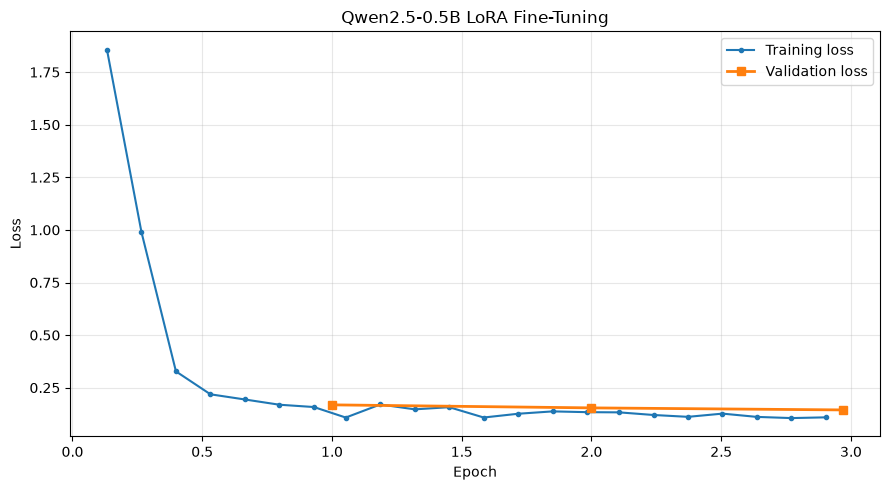


Figure saved to: /content/drive/MyDrive/GenAI_Assignment_2/figures/training_loss.png

STEP 23 COMPLETE!


In [19]:
# ============================================================
# STEP 23: Analyze and Plot LoRA Training Results
# TASK 1: Training Logs and Loss Curves
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import json

log_path = PROJECT_DIR / "logs" / "training_log.json"

with open(log_path, "r") as f:
    logs = json.load(f)

log_df = pd.DataFrame(logs)

print("TRAINING HISTORY")
print("=" * 50)

print("Final trainer epoch:", trainer.state.epoch)
print("Final global step:", trainer.state.global_step)
print("Configured epochs:", trainer.args.num_train_epochs)

train_logs = log_df[
    log_df["loss"].notna()
].copy()

eval_logs = log_df[
    log_df["eval_loss"].notna()
].copy()

print("\nValidation results:")
print(
    eval_logs[
        ["epoch", "eval_loss"]
    ].to_string(index=False)
)

plt.figure(figsize=(9, 5))

plt.plot(
    train_logs["epoch"],
    train_logs["loss"],
    label="Training loss",
    marker="o",
    markersize=3
)

plt.plot(
    eval_logs["epoch"],
    eval_logs["eval_loss"],
    label="Validation loss",
    marker="s",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Qwen2.5-0.5B LoRA Fine-Tuning")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

figure_path = (
    PROJECT_DIR / "figures" / "training_loss.png"
)

plt.savefig(figure_path, dpi=200)
plt.show()

print("\nFigure saved to:", figure_path)
print("\nSTEP 23 COMPLETE!")

In [20]:
# ============================================================
# STEP 24A: Prepare Fine-Tuned Model for Inference
# TASK 1: After Fine-Tuning Evaluation
# ============================================================

import torch

model.gradient_checkpointing_disable()
model.config.use_cache = True
model.eval()

# The Trainer loads the best checkpoint when
# load_best_model_at_end=True.
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation loss:", trainer.state.best_metric)

print("\nSTEP 24A COMPLETE: Model ready for evaluation!")

Best checkpoint: /content/drive/MyDrive/GenAI_Assignment_2/models/qwen_lora/checkpoint-225
Best validation loss: 0.14434561133384705

STEP 24A COMPLETE: Model ready for evaluation!


In [21]:
# ============================================================
# STEP 24B: Generate Fine-Tuned Validation Predictions
# TASK 1: After Fine-Tuning Evaluation
# ============================================================

import json
import time
from tqdm.auto import tqdm

finetuned_path = (
    PROJECT_DIR / "results" / "finetuned_validation.jsonl"
)

finetuned_results = []

# Resume if an earlier evaluation was interrupted
if finetuned_path.exists():
    with open(finetuned_path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                finetuned_results.append(json.loads(line))

print("Previously saved predictions:", len(finetuned_results))

assert len(finetuned_results) <= len(val_clean)

start_time = time.perf_counter()

for idx in tqdm(
    range(len(finetuned_results), len(val_clean)),
    desc="Fine-tuned validation"
):

    row = val_clean.iloc[idx]

    raw_response = generate_prediction(
        row["model_input"],
        use_base_model=False
    )

    parsed = parse_model_response(raw_response)

    result = {
        "annotation_id": int(row["annotation_id"]),
        "patient_id": str(row["patient_id"]),
        "criterion_type": row["criterion_type"],
        "gold_label": row["label"],
        "gold_evidence_ids": [
            int(x) for x in row["evidence_ids"]
        ],
        "raw_response": raw_response,
        **parsed
    }

    finetuned_results.append(result)

    if (idx + 1) % 20 == 0:
        with open(
            finetuned_path, "w", encoding="utf-8"
        ) as f:
            for record in finetuned_results:
                f.write(json.dumps(record) + "\n")

with open(
    finetuned_path, "w", encoding="utf-8"
) as f:
    for record in finetuned_results:
        f.write(json.dumps(record) + "\n")

elapsed = time.perf_counter() - start_time

print("\nFine-tuned predictions:", len(finetuned_results))
print(f"Evaluation time: {elapsed:.2f} seconds")
print("Saved to:", finetuned_path)

print("\nSTEP 24B COMPLETE!")

Previously saved predictions: 0


Fine-tuned validation:   0%|          | 0/206 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(



Fine-tuned predictions: 206
Evaluation time: 139.22 seconds
Saved to: /content/drive/MyDrive/GenAI_Assignment_2/results/finetuned_validation.jsonl

STEP 24B COMPLETE!


In [23]:
# ============================================================
# STEP 24C: Compare Baseline vs Fine-Tuned Model (FIXED)
# TASK 1: Before/After Evaluation
# ============================================================

import pandas as pd
import json

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. Reload saved predictions
# ------------------------------------------------------------

baseline_df = pd.read_json(
    PROJECT_DIR / "results" / "baseline_validation.jsonl",
    lines=True
)

finetuned_df = pd.read_json(
    PROJECT_DIR / "results" / "finetuned_validation.jsonl",
    lines=True
)

VALID_LABELS = [
    "included",
    "not included",
    "excluded",
    "not excluded",
    "not applicable",
    "not enough information"
]

# ------------------------------------------------------------
# 2. Normalize predictions consistently
# ------------------------------------------------------------

def normalize_prediction(row):

    label = row["predicted_label"]

    if (
        not row["parse_success"]
        or not isinstance(label, str)
        or label not in VALID_LABELS
    ):
        return "__invalid__"

    if row["criterion_type"] == "inclusion":
        allowed = {
            "included",
            "not included",
            "not applicable",
            "not enough information"
        }

    elif row["criterion_type"] == "exclusion":
        allowed = {
            "excluded",
            "not excluded",
            "not applicable",
            "not enough information"
        }

    else:
        return "__invalid__"

    return label if label in allowed else "__invalid__"


baseline_df["evaluated_prediction"] = (
    baseline_df.apply(normalize_prediction, axis=1)
)

finetuned_df["evaluated_prediction"] = (
    finetuned_df.apply(normalize_prediction, axis=1)
)

# ------------------------------------------------------------
# 3. Calculate metrics for both models
# ------------------------------------------------------------

def calculate_metrics(df):

    y_true = df["gold_label"]
    y_pred = df["evaluated_prediction"]

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Macro-F1": f1_score(
            y_true,
            y_pred,
            labels=VALID_LABELS,
            average="macro",
            zero_division=0
        ),

        "Invalid outputs": int(
            (y_pred == "__invalid__").sum()
        )
    }


baseline_metrics = calculate_metrics(baseline_df)
finetuned_metrics = calculate_metrics(finetuned_df)

# ------------------------------------------------------------
# 4. Display comparison
# ------------------------------------------------------------

comparison_df = pd.DataFrame([
    {
        "Model": "Base Qwen2.5-0.5B",
        **baseline_metrics
    },
    {
        "Model": "LoRA Fine-Tuned Qwen2.5-0.5B",
        **finetuned_metrics
    }
])

print("BEFORE VS AFTER FINE-TUNING")
print("=" * 65)

print(comparison_df.to_string(index=False))

print("\nFINE-TUNED PER-CLASS METRICS")
print("=" * 65)

print(
    classification_report(
        finetuned_df["gold_label"],
        finetuned_df["evaluated_prediction"],
        labels=VALID_LABELS,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 5. Display sample fine-tuned predictions
# ------------------------------------------------------------

print("\nSAMPLE FINE-TUNED RESPONSES")
print("=" * 65)

for i in range(5):

    row = finetuned_df.iloc[i]

    print(f"\nExample {i + 1}")

    print("Gold label:", row["gold_label"])

    print(
        "Predicted label:",
        row["evaluated_prediction"]
    )

    print(
        "Predicted evidence:",
        row["predicted_evidence_ids"]
    )

    print("Raw response:", row["raw_response"])

# ------------------------------------------------------------
# 6. Save comparison
# ------------------------------------------------------------

comparison_path = (
    PROJECT_DIR
    / "results"
    / "model_comparison_results.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\nComparison saved to:", comparison_path)

print("\nSTEP 24C COMPLETE!")

BEFORE VS AFTER FINE-TUNING
                       Model  Accuracy  Macro-F1  Invalid outputs
           Base Qwen2.5-0.5B  0.000000  0.000000              206
LoRA Fine-Tuned Qwen2.5-0.5B  0.728155  0.384552                0

FINE-TUNED PER-CLASS METRICS
                        precision    recall  f1-score   support

              included       0.82      0.77      0.79        35
          not included       0.00      0.00      0.00         3
              excluded       0.00      0.00      0.00         2
          not excluded       0.74      0.97      0.84       101
        not applicable       1.00      0.08      0.15        12
not enough information       0.62      0.45      0.52        53

              accuracy                           0.73       206
             macro avg       0.53      0.38      0.38       206
          weighted avg       0.72      0.73      0.69       206


SAMPLE FINE-TUNED RESPONSES

Example 1
Gold label: not enough information
Predicted label: not enoug

# PART 3 — TASK 2: Classification and Evidence Retrieval Evaluation

This section evaluates the fine-tuned Qwen2.5-0.5B-Instruct model on clinical trial eligibility classification and supporting evidence identification.

Evaluation includes:
- Overall and per-class classification metrics
- Separate inclusion and exclusion criterion performance
- Confusion matrices
- Evidence retrieval precision, recall, and F1
- Error analysis with at least eight examples

All development-stage analyses use the validation split. The held-out test patients remain untouched until final evaluation.

OVERALL CLASSIFICATION PERFORMANCE
                        precision    recall  f1-score   support

              included       0.82      0.77      0.79        35
          not included       0.00      0.00      0.00         3
              excluded       0.00      0.00      0.00         2
          not excluded       0.74      0.97      0.84       101
        not applicable       1.00      0.08      0.15        12
not enough information       0.62      0.45      0.52        53

              accuracy                           0.73       206
             macro avg       0.53      0.38      0.38       206
          weighted avg       0.72      0.73      0.69       206


INCLUSION CRITERIA
Examples: 66
Accuracy: 0.7424
Macro-F1 (six-label): 0.2546

EXCLUSION CRITERIA
Examples: 140
Accuracy: 0.7214
Macro-F1 (six-label): 0.1882


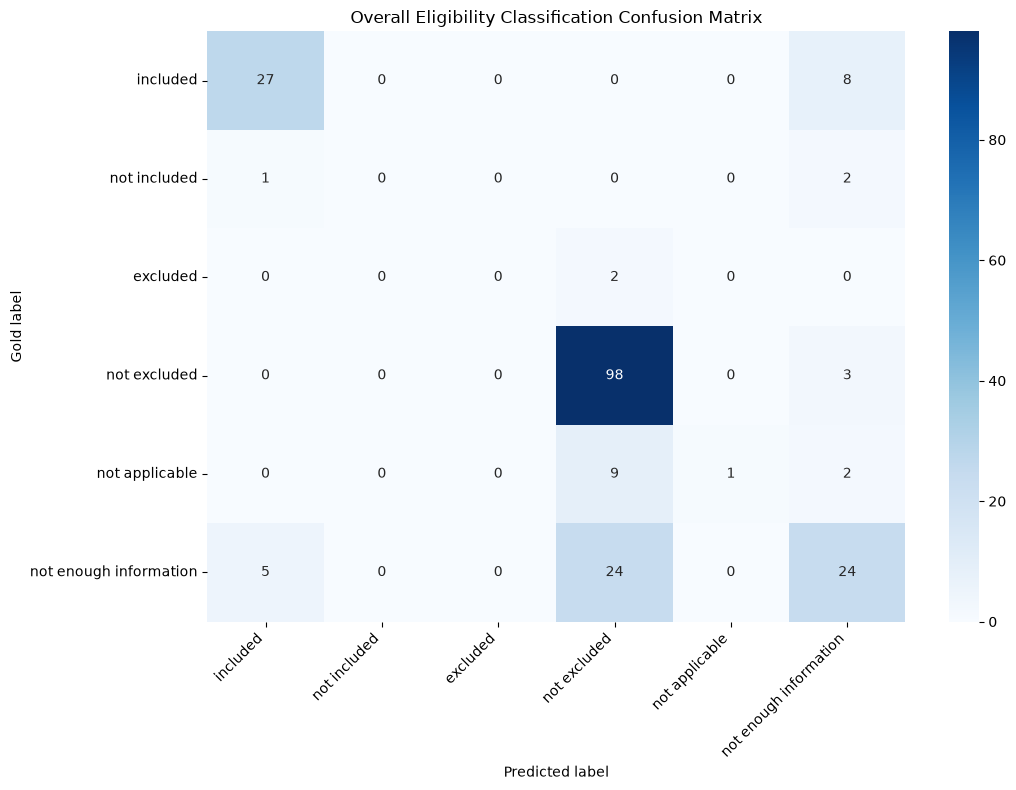

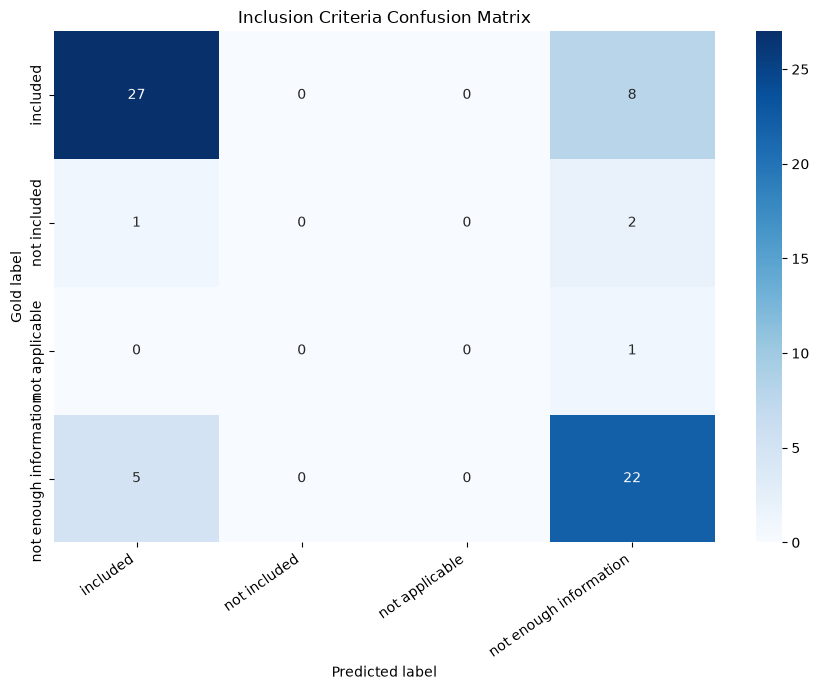

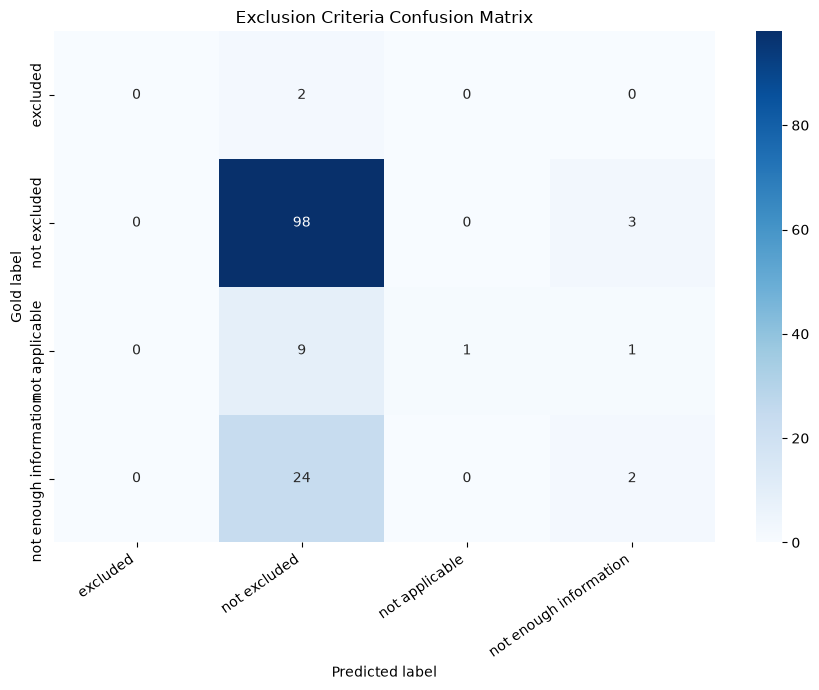


STEP 25 COMPLETE!


In [24]:
# ============================================================
# STEP 25: Classification Metrics and Confusion Matrices
# TASK 2: Eligibility Classification Evaluation
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

df_eval = finetuned_df.copy()

VALID_LABELS = [
    "included",
    "not included",
    "excluded",
    "not excluded",
    "not applicable",
    "not enough information"
]

print("OVERALL CLASSIFICATION PERFORMANCE")
print("=" * 60)

print(
    classification_report(
        df_eval["gold_label"],
        df_eval["evaluated_prediction"],
        labels=VALID_LABELS,
        zero_division=0
    )
)

# Separate inclusion and exclusion evaluations
for criterion_type in ["inclusion", "exclusion"]:

    subset = df_eval[
        df_eval["criterion_type"] == criterion_type
    ]

    accuracy = accuracy_score(
        subset["gold_label"],
        subset["evaluated_prediction"]
    )

    macro_f1 = f1_score(
        subset["gold_label"],
        subset["evaluated_prediction"],
        labels=VALID_LABELS,
        average="macro",
        zero_division=0
    )

    print(f"\n{criterion_type.upper()} CRITERIA")
    print("=" * 60)
    print("Examples:", len(subset))
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro-F1 (six-label): {macro_f1:.4f}")

# Overall confusion matrix
cm = confusion_matrix(
    df_eval["gold_label"],
    df_eval["evaluated_prediction"],
    labels=VALID_LABELS
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=VALID_LABELS,
    yticklabels=VALID_LABELS
)

plt.xlabel("Predicted label")
plt.ylabel("Gold label")
plt.title("Overall Eligibility Classification Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "confusion_matrix_overall.png",
    dpi=200
)

plt.show()

# Criterion-specific confusion matrices
for criterion_type in ["inclusion", "exclusion"]:

    subset = df_eval[
        df_eval["criterion_type"] == criterion_type
    ]

    if criterion_type == "inclusion":
        labels = [
            "included",
            "not included",
            "not applicable",
            "not enough information"
        ]
    else:
        labels = [
            "excluded",
            "not excluded",
            "not applicable",
            "not enough information"
        ]

    cm = confusion_matrix(
        subset["gold_label"],
        subset["evaluated_prediction"],
        labels=labels
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.xlabel("Predicted label")
    plt.ylabel("Gold label")
    plt.title(
        f"{criterion_type.capitalize()} Criteria Confusion Matrix"
    )
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    plt.savefig(
        PROJECT_DIR / "figures"
        / f"confusion_matrix_{criterion_type}.png",
        dpi=200
    )

    plt.show()

print("\nSTEP 25 COMPLETE!")

In [25]:
# ============================================================
# STEP 26: Evaluate Evidence Retrieval
# TASK 2: Evidence Precision, Recall, and F1
# ============================================================

import numpy as np
import pandas as pd
import json

def to_evidence_set(value):
    """
    Convert an evidence ID collection to a set of integers.
    """

    if not isinstance(value, (list, tuple, set, np.ndarray)):
        return set()

    return {
        int(x)
        for x in value
        if isinstance(x, (int, np.integer))
        and not isinstance(x, (bool, np.bool_))
    }


evidence_records = []

total_tp = 0
total_fp = 0
total_fn = 0

for _, row in df_eval.iterrows():

    gold = to_evidence_set(row["gold_evidence_ids"])
    pred = to_evidence_set(row["predicted_evidence_ids"])

    tp = len(gold & pred)
    fp = len(pred - gold)
    fn = len(gold - pred)

    total_tp += tp
    total_fp += fp
    total_fn += fn

    precision = (
        tp / (tp + fp)
        if tp + fp > 0 else 0.0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0 else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    evidence_records.append({
        "annotation_id": row["annotation_id"],
        "criterion_type": row["criterion_type"],
        "gold_evidence": sorted(gold),
        "predicted_evidence": sorted(pred),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "exact_match": gold == pred
    })


evidence_df = pd.DataFrame(evidence_records)

micro_precision = (
    total_tp / (total_tp + total_fp)
    if total_tp + total_fp > 0 else 0.0
)

micro_recall = (
    total_tp / (total_tp + total_fn)
    if total_tp + total_fn > 0 else 0.0
)

micro_f1 = (
    2 * micro_precision * micro_recall
    / (micro_precision + micro_recall)
    if micro_precision + micro_recall > 0 else 0.0
)

macro_precision = evidence_df["precision"].mean()
macro_recall = evidence_df["recall"].mean()
macro_f1 = evidence_df["f1"].mean()

exact_match_rate = evidence_df["exact_match"].mean()

print("EVIDENCE RETRIEVAL PERFORMANCE")
print("=" * 55)

print("\nMicro-averaged metrics:")
print(f"Precision: {micro_precision:.4f}")
print(f"Recall:    {micro_recall:.4f}")
print(f"F1:        {micro_f1:.4f}")

print("\nMacro-averaged metrics:")
print(f"Precision: {macro_precision:.4f}")
print(f"Recall:    {macro_recall:.4f}")
print(f"F1:        {macro_f1:.4f}")

print(f"\nExact evidence match: {exact_match_rate:.4f}")

print("\nEvidence counts:")
print("True positives:", total_tp)
print("False positives:", total_fp)
print("False negatives:", total_fn)

# Save results
evidence_df.to_csv(
    PROJECT_DIR / "results" / "evidence_evaluation.csv",
    index=False
)

evidence_metrics = {
    "micro_precision": float(micro_precision),
    "micro_recall": float(micro_recall),
    "micro_f1": float(micro_f1),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "exact_match_rate": float(exact_match_rate),
    "true_positives": int(total_tp),
    "false_positives": int(total_fp),
    "false_negatives": int(total_fn)
}

with open(
    PROJECT_DIR / "results" / "evidence_metrics.json",
    "w"
) as f:
    json.dump(evidence_metrics, f, indent=4)

print("\nSTEP 26 COMPLETE!")

EVIDENCE RETRIEVAL PERFORMANCE

Micro-averaged metrics:
Precision: 0.6087
Recall:    0.3652
F1:        0.4565

Macro-averaged metrics:
Precision: 0.2039
Recall:    0.1808
F1:        0.1872

Exact evidence match: 0.6602

Evidence counts:
True positives: 42
False positives: 27
False negatives: 73

STEP 26 COMPLETE!


In [26]:
# ============================================================
# STEP 27: Identify Classification and Evidence Errors
# TASK 2: Error Analysis
# ============================================================

import pandas as pd

analysis_df = df_eval.merge(
    evidence_df[
        ["annotation_id", "f1", "exact_match"]
    ],
    on="annotation_id",
    how="left"
)

analysis_df["classification_correct"] = (
    analysis_df["gold_label"]
    == analysis_df["evaluated_prediction"]
)

analysis_df["classification_error"] = (
    ~analysis_df["classification_correct"]
)

analysis_df["evidence_error"] = (
    ~analysis_df["exact_match"]
)

print("ERROR ANALYSIS SUMMARY")
print("=" * 60)

print(
    "Classification errors:",
    int(analysis_df["classification_error"].sum())
)

print(
    "Evidence mismatches:",
    int(analysis_df["evidence_error"].sum())
)

print(
    "Both classification and evidence errors:",
    int(
        (
            analysis_df["classification_error"]
            & analysis_df["evidence_error"]
        ).sum()
    )
)

print("\nFIRST 8 CLASSIFICATION ERRORS")
print("=" * 60)

errors = analysis_df[
    analysis_df["classification_error"]
].head(8)

for i, (_, row) in enumerate(errors.iterrows(), start=1):

    print(f"\nERROR CASE {i}")
    print("-" * 50)

    print("Annotation ID:", row["annotation_id"])
    print("Criterion type:", row["criterion_type"])
    print("Gold label:", row["gold_label"])
    print("Predicted label:", row["evaluated_prediction"])
    print("Gold evidence:", row["gold_evidence_ids"])
    print("Predicted evidence:", row["predicted_evidence_ids"])
    print("Evidence F1:", round(row["f1"], 4))

print("\nSTEP 27 COMPLETE!")

ERROR ANALYSIS SUMMARY
Classification errors: 56
Evidence mismatches: 70
Both classification and evidence errors: 26

FIRST 8 CLASSIFICATION ERRORS

ERROR CASE 1
--------------------------------------------------
Annotation ID: 8
Criterion type: exclusion
Gold label: not enough information
Predicted label: not excluded
Gold evidence: [0, 1, 2]
Predicted evidence: []
Evidence F1: 0.0

ERROR CASE 2
--------------------------------------------------
Annotation ID: 15
Criterion type: exclusion
Gold label: not enough information
Predicted label: not excluded
Gold evidence: []
Predicted evidence: []
Evidence F1: 0.0

ERROR CASE 3
--------------------------------------------------
Annotation ID: 18
Criterion type: exclusion
Gold label: not enough information
Predicted label: not excluded
Gold evidence: []
Predicted evidence: [8]
Evidence F1: 0.0

ERROR CASE 4
--------------------------------------------------
Annotation ID: 19
Criterion type: exclusion
Gold label: not enough information
Predi

In [27]:
# ============================================================
# STEP 28: Audit and Recalculate Evidence Metrics
# TASK 2: Evidence Retrieval Evaluation
# ============================================================

import numpy as np
import pandas as pd
import json

audit_df = evidence_df.copy()

audit_df["gold_empty"] = audit_df["gold_evidence"].apply(
    lambda x: len(x) == 0
)

audit_df["pred_empty"] = audit_df["predicted_evidence"].apply(
    lambda x: len(x) == 0
)

both_empty = (
    audit_df["gold_empty"] & audit_df["pred_empty"]
)

gold_only_empty = (
    audit_df["gold_empty"] & ~audit_df["pred_empty"]
)

pred_only_empty = (
    ~audit_df["gold_empty"] & audit_df["pred_empty"]
)

both_nonempty = (
    ~audit_df["gold_empty"] & ~audit_df["pred_empty"]
)

print("EVIDENCE EMPTY-SET AUDIT")
print("=" * 55)

print("Both empty:", int(both_empty.sum()))
print("Gold empty, prediction nonempty:", int(gold_only_empty.sum()))
print("Gold nonempty, prediction empty:", int(pred_only_empty.sum()))
print("Both nonempty:", int(both_nonempty.sum()))

# Convention A: empty-empty receives perfect credit
adjusted_df = audit_df.copy()

for metric in ["precision", "recall", "f1"]:
    adjusted_df.loc[both_empty, metric] = 1.0

# Convention B: evaluate only nonempty-union examples
nonempty_union = audit_df[~both_empty]

print("\nMACRO METRICS COMPARISON")
print("=" * 55)

print("Original convention (empty-empty = 0):")
print(audit_df[["precision", "recall", "f1"]].mean())

print("\nMatching empty sets receive full credit:")
print(adjusted_df[["precision", "recall", "f1"]].mean())

print("\nNonempty-union examples only:")
print(nonempty_union[["precision", "recall", "f1"]].mean())

print("\nMicro-F1 (unchanged):", round(micro_f1, 4))
print("Exact match (unchanged):", round(exact_match_rate, 4))

audit_summary = {
    "total_examples": int(len(audit_df)),
    "both_empty": int(both_empty.sum()),
    "gold_only_empty": int(gold_only_empty.sum()),
    "pred_only_empty": int(pred_only_empty.sum()),
    "both_nonempty": int(both_nonempty.sum()),
    "macro_f1_empty_zero": float(audit_df["f1"].mean()),
    "macro_f1_empty_perfect": float(adjusted_df["f1"].mean()),
    "macro_f1_nonempty_union": float(
        nonempty_union["f1"].mean()
    ) if len(nonempty_union) else None,
    "micro_f1": float(micro_f1),
    "exact_match_rate": float(exact_match_rate)
}

with open(
    PROJECT_DIR / "results" / "evidence_audit.json",
    "w"
) as f:
    json.dump(audit_summary, f, indent=4)

print("\nSTEP 28 COMPLETE!")

EVIDENCE EMPTY-SET AUDIT
Both empty: 102
Gold empty, prediction nonempty: 14
Gold nonempty, prediction empty: 35
Both nonempty: 55

MACRO METRICS COMPARISON
Original convention (empty-empty = 0):
precision    0.203883
recall       0.180825
f1           0.187217
dtype: float64

Matching empty sets receive full credit:
precision    0.699029
recall       0.675971
f1           0.682362
dtype: float64

Nonempty-union examples only:
precision    0.403846
recall       0.358173
f1           0.370833
dtype: float64

Micro-F1 (unchanged): 0.4565
Exact match (unchanged): 0.6602

STEP 28 COMPLETE!


In [28]:
# ============================================================
# STEP 29: Prepare Eight Detailed Error Analysis Cases
# TASK 2: Qualitative Error Analysis
# ============================================================

import pandas as pd

# Select classification errors
error_cases = analysis_df[
    analysis_df["classification_error"]
].head(8).copy()

# Add original patient notes and criteria
error_details = error_cases.merge(
    val_clean[
        [
            "annotation_id",
            "criterion_text",
            "patient_text"
        ]
    ],
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

assert len(error_details) == 8

print("EIGHT DETAILED ERROR CASES")
print("=" * 70)

for i, (_, row) in enumerate(
    error_details.iterrows(), start=1
):

    print(f"\n{'=' * 70}")
    print(f"ERROR CASE {i}")
    print(f"{'=' * 70}")

    print("Annotation ID:", row["annotation_id"])
    print("Criterion type:", row["criterion_type"])

    print("\nCRITERION:")
    print(str(row["criterion_text"])[:1500])

    print("\nPATIENT NOTE:")
    print(str(row["patient_text"])[:2500])

    print("\nGOLD LABEL:", row["gold_label"])
    print("PREDICTED LABEL:", row["evaluated_prediction"])

    print("\nGOLD EVIDENCE:", row["gold_evidence_ids"])
    print("PREDICTED EVIDENCE:", row["predicted_evidence_ids"])

    print("EVIDENCE F1:", round(row["f1"], 4))

# Save detailed cases
error_path = (
    PROJECT_DIR / "results" / "detailed_error_cases.csv"
)

error_details.to_csv(error_path, index=False)

print("\nSaved to:", error_path)
print("\nSTEP 29 COMPLETE!")

EIGHT DETAILED ERROR CASES

ERROR CASE 1
Annotation ID: 8
Criterion type: exclusion

CRITERION:
Unstable angina

PATIENT NOTE:
0. A 58-year-old African-American woman presents to the ER with episodic pressing/burning anterior chest pain that began two days earlier for the first time in her life.
1. The pain started while she was walking, radiates to the back, and is accompanied by nausea, diaphoresis and mild dyspnea, but is not increased on inspiration.
2. The latest episode of pain ended half an hour prior to her arrival.
3. She is known to have hypertension and obesity.
4. She denies smoking, diabetes, hypercholesterolemia, or a family history of heart disease.
5. She currently takes no medications.
6. Physical examination is normal.
7. The EKG shows nonspecific changes.
8. The patient will provide informed consent, and will comply with the trial protocol without any practical issues.

GOLD LABEL: not enough information
PREDICTED LABEL: not excluded

GOLD EVIDENCE: [0, 1, 2]
PREDICT

In [29]:
# ============================================================
# STEP 30: Save Task 2 Evaluation and Error Analysis Summary
# TASK 2: Final Evaluation Documentation
# ============================================================

import json

task2_summary = {
    "evaluation_split": "validation",
    "total_annotations": 206,
    "classification": {
        "accuracy": 0.728155,
        "macro_f1": 0.384552,
        "inclusion_accuracy": 0.7424,
        "exclusion_accuracy": 0.7214,
        "classification_errors": 56
    },
    "evidence_retrieval": {
        "micro_precision": 0.6087,
        "micro_recall": 0.3652,
        "micro_f1": 0.4565,
        "macro_f1_empty_zero": 0.187217,
        "macro_f1_empty_perfect": 0.682362,
        "macro_f1_nonempty_union": 0.370833,
        "exact_match_rate": 0.6602,
        "both_empty_count": 102,
        "gold_only_empty_count": 14,
        "prediction_only_empty_count": 35,
        "both_nonempty_count": 55
    },
    "error_analysis": [
        {
            "annotation_id": 8,
            "failure": "Missing clinical confirmation of unstable angina"
        },
        {
            "annotation_id": 15,
            "failure": "Missing pregnancy/nursing status"
        },
        {
            "annotation_id": 18,
            "failure": "Unsupported imaging eligibility decision"
        },
        {
            "annotation_id": 19,
            "failure": "Missing beta-blocker contraindication information"
        },
        {
            "annotation_id": 22,
            "failure": "Obesity risk factor overlooked"
        },
        {
            "annotation_id": 24,
            "failure": "Not applicable confused with not excluded"
        },
        {
            "annotation_id": 26,
            "failure": "Pregnancy-related uncertainty overlooked"
        },
        {
            "annotation_id": 31,
            "failure": "Fever duration requirement misinterpreted"
        }
    ],
    "main_findings": [
        "Fine-tuning improved structured eligibility classification.",
        "Minority classes remain difficult to predict.",
        "Missing information is frequently confused with negative evidence.",
        "Evidence retrieval performance depends on empty-set conventions.",
        "Correct evidence identification does not guarantee correct classification."
    ]
}

summary_path = (
    PROJECT_DIR / "results" / "task2_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(task2_summary, f, indent=4)

print("Task 2 summary saved to:", summary_path)
print("\nSTEP 30 COMPLETE!")

Task 2 summary saved to: /content/drive/MyDrive/GenAI_Assignment_2/results/task2_summary.json

STEP 30 COMPLETE!


# PART 4 — TASK 3: Autoregressive Decoding With and Without KV Cache

This task implements two autoregressive decoding methods using the fine-tuned Qwen2.5-0.5B-Instruct model.

1. **Uncached decoding:** Recomputes the entire prefix at every generation step.
2. **KV-cached decoding:** Reuses attention key/value tensors from previous steps.

The experiment verifies token-level equivalence and benchmarks generation latency, throughput, and peak GPU memory for different input and output lengths.

Both methods use greedy decoding under identical model settings.

In [30]:
# ============================================================
# STEP 31: Prepare Model for KV-Cache Experiments
# TASK 3: Autoregressive Decoding
# ============================================================

import torch
import time
import json
import pandas as pd
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "A CUDA GPU is required."

# Disable training-specific settings
model.gradient_checkpointing_disable()
model.config.use_cache = True
model.eval()

DEVICE = model.device

print("Model:", MODEL_NAME)
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Model dtype:", next(model.parameters()).dtype)

# Use one validation prompt for initial correctness testing
sample_prompt = val_clean.iloc[0]["model_input"].rstrip() + "\n"

sample_inputs = tokenizer(
    sample_prompt,
    return_tensors="pt",
    add_special_tokens=False
)

sample_ids = sample_inputs["input_ids"].to(DEVICE)

print("\nPrompt tokens:", sample_ids.shape[1])
print("Prompt preview:", repr(sample_prompt[:200]))

print("\nSTEP 31 COMPLETE!")

Model: Qwen/Qwen2.5-0.5B-Instruct
Device: cuda:0
GPU: Tesla T4
Model dtype: torch.float16

Prompt tokens: 270
Prompt preview: "You are an educational clinical trial eligibility screening assistant.\nEvaluate the criterion using only the patient information provided.\nReturn a JSON object with exactly two keys: 'label' and 'evid"

STEP 31 COMPLETE!


In [31]:
# ============================================================
# STEP 32: Implement Uncached Autoregressive Decoding
# TASK 3: KV Cache Comparison
# ============================================================

@torch.inference_mode()
def decode_without_cache(input_ids, max_new_tokens=32):

    generated = input_ids.clone()
    new_tokens = []

    for _ in range(max_new_tokens):

        outputs = model(
            input_ids=generated,
            use_cache=False,
            return_dict=True
        )

        next_token = torch.argmax(
            outputs.logits[:, -1, :],
            dim=-1,
            keepdim=True
        )

        generated = torch.cat(
            [generated, next_token],
            dim=1
        )

        new_tokens.append(next_token)

    return torch.cat(new_tokens, dim=1)


print("STEP 32 COMPLETE: Uncached decoder implemented!")

STEP 32 COMPLETE: Uncached decoder implemented!


In [32]:
# ============================================================
# STEP 33: Implement KV-Cached Autoregressive Decoding
# TASK 3: KV Cache Comparison
# ============================================================

@torch.inference_mode()
def decode_with_cache(input_ids, max_new_tokens=32):

    past_key_values = None
    current_input = input_ids

    new_tokens = []

    for _ in range(max_new_tokens):

        outputs = model(
            input_ids=current_input,
            past_key_values=past_key_values,
            use_cache=True,
            return_dict=True
        )

        past_key_values = outputs.past_key_values

        next_token = torch.argmax(
            outputs.logits[:, -1, :],
            dim=-1,
            keepdim=True
        )

        new_tokens.append(next_token)

        # After the first step, process only one new token
        current_input = next_token

    return torch.cat(new_tokens, dim=1)


print("STEP 33 COMPLETE: KV-cached decoder implemented!")

STEP 33 COMPLETE: KV-cached decoder implemented!


In [33]:
# ============================================================
# STEP 34: Verify Cached vs Uncached Token Identity
# TASK 3: Correctness Validation
# ============================================================

TEST_NEW_TOKENS = 32

print("Generating without cache...")

uncached_tokens = decode_without_cache(
    sample_ids,
    max_new_tokens=TEST_NEW_TOKENS
)

print("Generating with cache...")

cached_tokens = decode_with_cache(
    sample_ids,
    max_new_tokens=TEST_NEW_TOKENS
)

tokens_match = torch.equal(
    uncached_tokens,
    cached_tokens
)

print("\nCORRECTNESS RESULTS")
print("=" * 55)

print("Tokens generated:", TEST_NEW_TOKENS)
print("Token IDs identical:", tokens_match)

print("\nUncached output:")
print(
    tokenizer.decode(
        uncached_tokens[0],
        skip_special_tokens=True
    )
)

print("\nCached output:")
print(
    tokenizer.decode(
        cached_tokens[0],
        skip_special_tokens=True
    )
)

assert tokens_match, (
    "Cached and uncached decoding produced different tokens!"
)

print("\nSTEP 34 COMPLETE: Token identity verified!")

Generating without cache...
Generating with cache...

CORRECTNESS RESULTS
Tokens generated: 32
Token IDs identical: True

Uncached output:
{"label": "not enough information", "evidence_ids": [0, 1, 2, 3, 4, 5, 

Cached output:
{"label": "not enough information", "evidence_ids": [0, 1, 2, 3, 4, 5, 

STEP 34 COMPLETE: Token identity verified!


In [34]:
# ============================================================
# STEP 35: Benchmark Cached vs Uncached Decoding
# TASK 3: Latency, Throughput, and GPU Memory
# ============================================================

import torch
import time
import gc
import pandas as pd

PROMPT_LENGTHS = [64, 128, 256]
OUTPUT_LENGTHS = [16, 32, 64]

# Construct reproducible prompts from validation text.
# Repeating text is only for performance benchmarking,
# not for clinical evaluation.
source_ids = tokenizer(
    sample_prompt,
    add_special_tokens=False
)["input_ids"]

assert len(source_ids) > 0

def make_benchmark_prompt(length):
    repeats = (length // len(source_ids)) + 1
    ids = (source_ids * repeats)[:length]

    return torch.tensor(
        [ids],
        dtype=torch.long,
        device=DEVICE
    )


def benchmark_decoder(decoder_fn, input_ids, output_length):

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    torch.cuda.synchronize()
    start = time.perf_counter()

    output = decoder_fn(
        input_ids,
        max_new_tokens=output_length
    )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    peak_memory_gib = (
        torch.cuda.max_memory_allocated() / (1024 ** 3)
    )

    return {
        "tokens": output.detach().cpu(),
        "time_seconds": elapsed,
        "tokens_per_second": output_length / elapsed,
        "peak_memory_gib": peak_memory_gib
    }


benchmark_results = []

print("STARTING KV-CACHE BENCHMARKS")
print("=" * 60)

for prompt_length in PROMPT_LENGTHS:

    input_ids = make_benchmark_prompt(prompt_length)

    for output_length in OUTPUT_LENGTHS:

        print(
            f"\nPrompt={prompt_length}, "
            f"Output={output_length}"
        )

        # Warm up both implementations
        _ = decode_without_cache(input_ids, 2)
        _ = decode_with_cache(input_ids, 2)
        torch.cuda.synchronize()

        uncached = benchmark_decoder(
            decode_without_cache,
            input_ids,
            output_length
        )

        cached = benchmark_decoder(
            decode_with_cache,
            input_ids,
            output_length
        )

        identical = torch.equal(
            uncached["tokens"],
            cached["tokens"]
        )

        speedup = (
            uncached["time_seconds"]
            / cached["time_seconds"]
        )

        print(
            f"Uncached: {uncached['time_seconds']:.3f}s | "
            f"Cached: {cached['time_seconds']:.3f}s"
        )

        print(f"Speedup: {speedup:.2f}x")
        print("Tokens identical:", identical)

        assert identical, (
            f"Token mismatch at prompt={prompt_length}, "
            f"output={output_length}"
        )

        benchmark_results.append({
            "prompt_length": prompt_length,
            "output_length": output_length,
            "uncached_seconds": uncached["time_seconds"],
            "cached_seconds": cached["time_seconds"],
            "uncached_tokens_per_second": (
                uncached["tokens_per_second"]
            ),
            "cached_tokens_per_second": (
                cached["tokens_per_second"]
            ),
            "uncached_peak_memory_gib": (
                uncached["peak_memory_gib"]
            ),
            "cached_peak_memory_gib": (
                cached["peak_memory_gib"]
            ),
            "speedup": speedup,
            "tokens_identical": identical
        })


benchmark_df = pd.DataFrame(benchmark_results)

benchmark_path = (
    PROJECT_DIR / "results" / "kv_cache_benchmark.csv"
)

benchmark_df.to_csv(benchmark_path, index=False)

print("\nBENCHMARK SUMMARY")
print("=" * 60)

print(
    benchmark_df[
        [
            "prompt_length",
            "output_length",
            "uncached_seconds",
            "cached_seconds",
            "speedup",
            "tokens_identical"
        ]
    ].to_string(index=False)
)

print("\nSaved to:", benchmark_path)
print("\nSTEP 35 COMPLETE!")

STARTING KV-CACHE BENCHMARKS

Prompt=64, Output=16
Uncached: 1.166s | Cached: 2.617s
Speedup: 0.45x
Tokens identical: True

Prompt=64, Output=32
Uncached: 2.571s | Cached: 2.247s
Speedup: 1.14x
Tokens identical: True

Prompt=64, Output=64
Uncached: 3.995s | Cached: 5.281s
Speedup: 0.76x
Tokens identical: True

Prompt=128, Output=16
Uncached: 0.603s | Cached: 1.009s
Speedup: 0.60x
Tokens identical: True

Prompt=128, Output=32
Uncached: 2.958s | Cached: 3.535s
Speedup: 0.84x
Tokens identical: True

Prompt=128, Output=64
Uncached: 2.939s | Cached: 2.360s
Speedup: 1.25x
Tokens identical: True

Prompt=256, Output=16
Uncached: 0.636s | Cached: 0.597s
Speedup: 1.06x
Tokens identical: True

Prompt=256, Output=32
Uncached: 1.233s | Cached: 1.185s
Speedup: 1.04x
Tokens identical: True

Prompt=256, Output=64
Uncached: 3.292s | Cached: 2.406s
Speedup: 1.37x
Tokens identical: True

BENCHMARK SUMMARY
 prompt_length  output_length  uncached_seconds  cached_seconds  speedup  tokens_identical
         

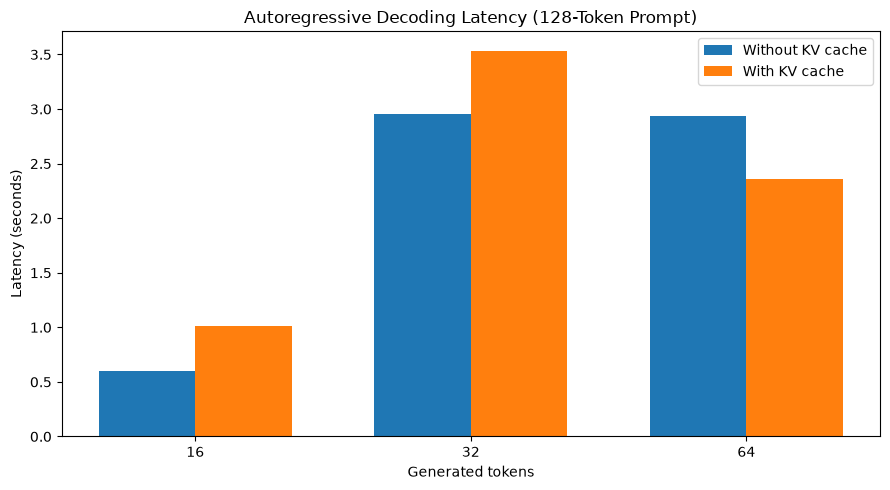

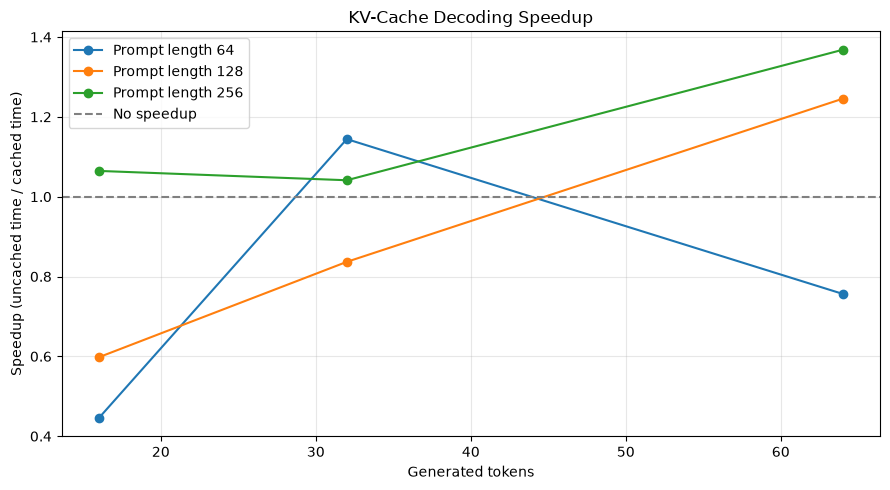

Latency figure: /content/drive/MyDrive/GenAI_Assignment_2/figures/kv_cache_latency.png
Speedup figure: /content/drive/MyDrive/GenAI_Assignment_2/figures/kv_cache_speedup.png

STEP 36 COMPLETE!


In [35]:
# ============================================================
# STEP 36: Visualize KV-Cache Benchmark Results
# TASK 3: Latency and Speedup Graphs
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Latency comparison at a fixed prompt length
plot_df = benchmark_df[
    benchmark_df["prompt_length"] == 128
].sort_values("output_length")

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    plot_df["uncached_seconds"],
    width,
    label="Without KV cache"
)

plt.bar(
    x + width / 2,
    plot_df["cached_seconds"],
    width,
    label="With KV cache"
)

plt.xticks(
    x,
    plot_df["output_length"].astype(str)
)

plt.xlabel("Generated tokens")
plt.ylabel("Latency (seconds)")
plt.title("Autoregressive Decoding Latency (128-Token Prompt)")
plt.legend()
plt.tight_layout()

latency_path = (
    PROJECT_DIR / "figures" / "kv_cache_latency.png"
)

plt.savefig(latency_path, dpi=200)
plt.show()


# Speedup vs output length for all prompt lengths
plt.figure(figsize=(9, 5))

for prompt_length in PROMPT_LENGTHS:

    subset = benchmark_df[
        benchmark_df["prompt_length"] == prompt_length
    ].sort_values("output_length")

    plt.plot(
        subset["output_length"],
        subset["speedup"],
        marker="o",
        label=f"Prompt length {prompt_length}"
    )

plt.axhline(
    1.0,
    linestyle="--",
    color="gray",
    label="No speedup"
)

plt.xlabel("Generated tokens")
plt.ylabel("Speedup (uncached time / cached time)")
plt.title("KV-Cache Decoding Speedup")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

speedup_path = (
    PROJECT_DIR / "figures" / "kv_cache_speedup.png"
)

plt.savefig(speedup_path, dpi=200)
plt.show()

print("Latency figure:", latency_path)
print("Speedup figure:", speedup_path)

print("\nSTEP 36 COMPLETE!")

In [36]:
# ============================================================
# STEP 37: Summarize KV-Cache Experiment
# TASK 3: Experimental Results
# ============================================================

import json

summary = {
    "model": MODEL_NAME,
    "gpu": torch.cuda.get_device_name(0),
    "decoding_strategy": "greedy",
    "prompt_lengths": PROMPT_LENGTHS,
    "output_lengths": OUTPUT_LENGTHS,
    "all_tokens_identical": bool(
        benchmark_df["tokens_identical"].all()
    ),
    "mean_speedup": float(
        benchmark_df["speedup"].mean()
    ),
    "max_speedup": float(
        benchmark_df["speedup"].max()
    ),
    "min_speedup": float(
        benchmark_df["speedup"].min()
    ),
    "benchmark_configurations": len(benchmark_df)
}

summary_path = (
    PROJECT_DIR / "results" / "kv_cache_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("TASK 3 SUMMARY")
print("=" * 55)

print("Configurations:", summary["benchmark_configurations"])
print("All token IDs identical:", summary["all_tokens_identical"])
print(f"Mean speedup: {summary['mean_speedup']:.2f}x")
print(f"Maximum speedup: {summary['max_speedup']:.2f}x")
print(f"Minimum speedup: {summary['min_speedup']:.2f}x")

print("\nSTEP 37 COMPLETE!")

TASK 3 SUMMARY
Configurations: 9
All token IDs identical: True
Mean speedup: 0.94x
Maximum speedup: 1.37x
Minimum speedup: 0.45x

STEP 37 COMPLETE!


In [37]:
# ============================================================
# STEP 38: Rigorous KV-Cache Benchmark
# TASK 3: Prefill, Decode, Repeated Timing, GPU Memory
# ============================================================

import torch
import time
import json
import pandas as pd
import numpy as np

model.eval()
model.gradient_checkpointing_disable()
model.config.use_cache = True

REPEATS = 3
BENCHMARK_CASES = [
    (64, 16),
    (128, 32),
    (256, 64)
]

def synchronize():
    torch.cuda.synchronize()

@torch.inference_mode()
def measure_decoding(input_ids, n_tokens, use_cache):

    # Measure prefill separately
    synchronize()
    start = time.perf_counter()

    outputs = model(
        input_ids=input_ids,
        use_cache=use_cache,
        return_dict=True
    )

    synchronize()
    prefill_time = time.perf_counter() - start

    next_token = outputs.logits[:, -1:, :].argmax(dim=-1)
    generated = [next_token]

    if use_cache:
        cache = outputs.past_key_values
        current_input = next_token
    else:
        full_sequence = torch.cat([input_ids, next_token], dim=1)

    synchronize()
    start = time.perf_counter()

    # Generate remaining tokens
    for _ in range(n_tokens - 1):

        if use_cache:
            outputs = model(
                input_ids=current_input,
                past_key_values=cache,
                use_cache=True,
                return_dict=True
            )
            cache = outputs.past_key_values
        else:
            outputs = model(
                input_ids=full_sequence,
                use_cache=False,
                return_dict=True
            )

        next_token = outputs.logits[:, -1:, :].argmax(dim=-1)
        generated.append(next_token)

        if use_cache:
            current_input = next_token
        else:
            full_sequence = torch.cat(
                [full_sequence, next_token], dim=1
            )

    synchronize()
    decode_time = time.perf_counter() - start

    return {
        "tokens": torch.cat(generated, dim=1).cpu(),
        "prefill_seconds": prefill_time,
        "decode_seconds": decode_time,
        "total_seconds": prefill_time + decode_time
    }


records = []

print("REPEATED KV-CACHE BENCHMARK")
print("=" * 65)

for prompt_length, output_length in BENCHMARK_CASES:

    input_ids = make_benchmark_prompt(prompt_length)

    # Warm-up outside measurement
    for use_cache in [False, True]:
        _ = measure_decoding(input_ids, 4, use_cache)

    for repeat in range(REPEATS):

        for use_cache in [False, True]:

            synchronize()
            torch.cuda.reset_peak_memory_stats()

            result = measure_decoding(
                input_ids,
                output_length,
                use_cache
            )

            peak_memory = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            records.append({
                "prompt_length": prompt_length,
                "output_length": output_length,
                "repeat": repeat + 1,
                "method": (
                    "cached" if use_cache else "uncached"
                ),
                "prefill_seconds": result["prefill_seconds"],
                "decode_seconds": result["decode_seconds"],
                "total_seconds": result["total_seconds"],
                "tokens_per_second": (
                    output_length / result["total_seconds"]
                ),
                "peak_memory_gib": peak_memory,
                "token_ids": result["tokens"][0].tolist()
            })

    # Verify equality for every repeat
    subset = [
        r for r in records
        if r["prompt_length"] == prompt_length
        and r["output_length"] == output_length
    ]

    for repeat in range(1, REPEATS + 1):

        uncached = next(
            r for r in subset
            if r["repeat"] == repeat
            and r["method"] == "uncached"
        )

        cached = next(
            r for r in subset
            if r["repeat"] == repeat
            and r["method"] == "cached"
        )

        assert uncached["token_ids"] == cached["token_ids"], (
            f"Mismatch at prompt={prompt_length}, "
            f"output={output_length}, repeat={repeat}"
        )

    print(
        f"Prompt={prompt_length}, Output={output_length}: "
        f"all {REPEATS} repeats identical"
    )


raw_df = pd.DataFrame(records)

# Save detailed runs without token arrays
raw_df.drop(columns=["token_ids"]).to_csv(
    PROJECT_DIR / "results" / "kv_cache_repeated_runs.csv",
    index=False
)

# Aggregate using medians
summary_df = (
    raw_df
    .drop(columns=["token_ids", "repeat"])
    .groupby(
        ["prompt_length", "output_length", "method"],
        as_index=False
    )
    .median(numeric_only=True)
)

summary_df.to_csv(
    PROJECT_DIR / "results" / "kv_cache_repeated_summary.csv",
    index=False
)

print("\nMEDIAN RESULTS")
print("=" * 65)

print(
    summary_df[
        [
            "prompt_length",
            "output_length",
            "method",
            "prefill_seconds",
            "decode_seconds",
            "total_seconds",
            "tokens_per_second",
            "peak_memory_gib"
        ]
    ].round(4).to_string(index=False)
)

print("\nSTEP 38 COMPLETE!")

REPEATED KV-CACHE BENCHMARK
Prompt=64, Output=16: all 3 repeats identical
Prompt=128, Output=32: all 3 repeats identical
Prompt=256, Output=64: all 3 repeats identical

MEDIAN RESULTS
 prompt_length  output_length   method  prefill_seconds  decode_seconds  total_seconds  tokens_per_second  peak_memory_gib
            64             16   cached           0.0698          1.1064         1.1882            13.4658           1.0036
            64             16 uncached           0.0658          1.1255         1.1921            13.4219           1.0598
           128             32   cached           0.0644          1.4352         1.4853            21.5446           1.0587
           128             32 uncached           0.0550          1.8743         1.9214            16.6546           1.1730
           256             64   cached           0.0417          2.2322         2.2707            28.1854           1.1688
           256             64 uncached           0.0407          2.4286       

FINAL KV-CACHE COMPARISON
configuration  speedup  decode_speedup  memory_reduction_percent
      64 / 16   1.0033          1.0172                    5.2992
     128 / 32   1.2936          1.3060                    9.7444
     256 / 64   1.0929          1.0880                   16.4771


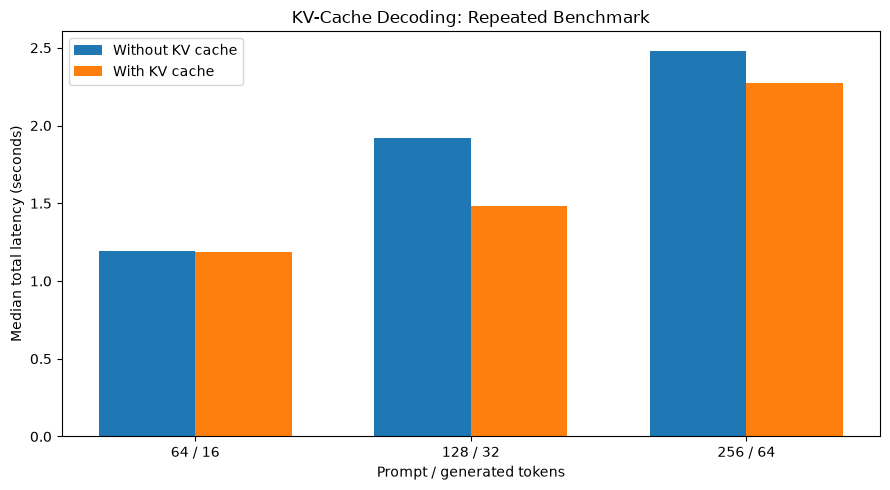

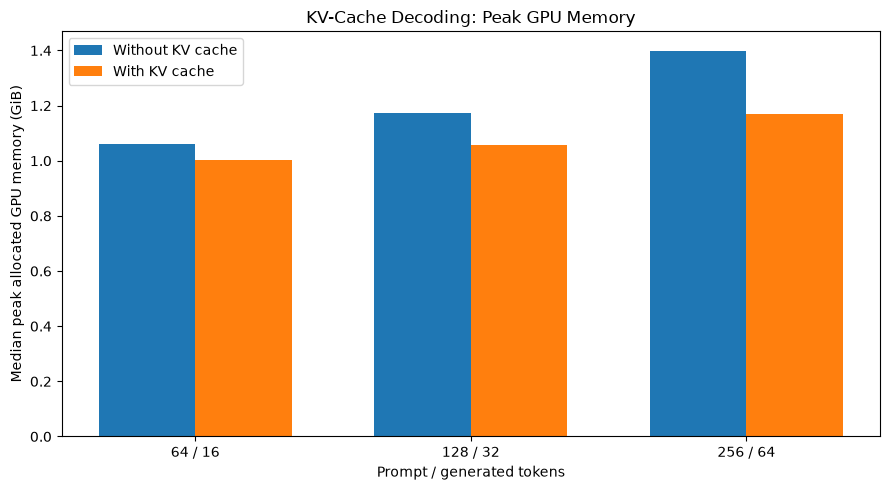


Mean speedup: 1.13
Maximum speedup: 1.294
Mean memory reduction: 10.51 %

STEP 39 COMPLETE!


In [38]:
# ============================================================
# STEP 39: Final KV-Cache Speedup and Memory Comparison
# TASK 3: Benchmark Analysis and Figures
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

# Reload saved median results
summary_df = pd.read_csv(
    PROJECT_DIR / "results" / "kv_cache_repeated_summary.csv"
)

cached_df = summary_df[
    summary_df["method"] == "cached"
].copy()

uncached_df = summary_df[
    summary_df["method"] == "uncached"
].copy()

comparison = uncached_df.merge(
    cached_df,
    on=["prompt_length", "output_length"],
    suffixes=("_uncached", "_cached"),
    validate="one_to_one"
)

comparison["speedup"] = (
    comparison["total_seconds_uncached"]
    / comparison["total_seconds_cached"]
)

comparison["decode_speedup"] = (
    comparison["decode_seconds_uncached"]
    / comparison["decode_seconds_cached"]
)

comparison["memory_reduction_percent"] = (
    (
        comparison["peak_memory_gib_uncached"]
        - comparison["peak_memory_gib_cached"]
    )
    / comparison["peak_memory_gib_uncached"]
    * 100
)

comparison["configuration"] = (
    comparison["prompt_length"].astype(str)
    + " / "
    + comparison["output_length"].astype(str)
)

print("FINAL KV-CACHE COMPARISON")
print("=" * 75)

print(
    comparison[
        [
            "configuration",
            "speedup",
            "decode_speedup",
            "memory_reduction_percent"
        ]
    ].round(4).to_string(index=False)
)

# Save detailed comparison
comparison.to_csv(
    PROJECT_DIR / "results" / "kv_cache_final_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# Plot 1: Median latency comparison
# ------------------------------------------------------------

x = np.arange(len(comparison))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    comparison["total_seconds_uncached"],
    width,
    label="Without KV cache"
)

plt.bar(
    x + width / 2,
    comparison["total_seconds_cached"],
    width,
    label="With KV cache"
)

plt.xticks(x, comparison["configuration"])

plt.xlabel("Prompt / generated tokens")
plt.ylabel("Median total latency (seconds)")
plt.title("KV-Cache Decoding: Repeated Benchmark")
plt.legend()
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "kv_cache_final_latency.png",
    dpi=200
)

plt.show()

# ------------------------------------------------------------
# Plot 2: GPU peak allocated memory
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    comparison["peak_memory_gib_uncached"],
    width,
    label="Without KV cache"
)

plt.bar(
    x + width / 2,
    comparison["peak_memory_gib_cached"],
    width,
    label="With KV cache"
)

plt.xticks(x, comparison["configuration"])

plt.xlabel("Prompt / generated tokens")
plt.ylabel("Median peak allocated GPU memory (GiB)")
plt.title("KV-Cache Decoding: Peak GPU Memory")
plt.legend()
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "kv_cache_final_memory.png",
    dpi=200
)

plt.show()

# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------

final_summary = {
    "model": MODEL_NAME,
    "gpu": torch.cuda.get_device_name(0),
    "repeats_per_configuration": 3,
    "configurations": len(comparison),
    "token_identity_passed": True,
    "mean_speedup": float(comparison["speedup"].mean()),
    "maximum_speedup": float(comparison["speedup"].max()),
    "minimum_speedup": float(comparison["speedup"].min()),
    "mean_memory_reduction_percent": float(
        comparison["memory_reduction_percent"].mean()
    )
}

with open(
    PROJECT_DIR / "results" / "kv_cache_final_summary.json",
    "w"
) as f:
    json.dump(final_summary, f, indent=4)

print("\nMean speedup:", round(final_summary["mean_speedup"], 3))
print("Maximum speedup:", round(final_summary["maximum_speedup"], 3))
print(
    "Mean memory reduction:",
    round(final_summary["mean_memory_reduction_percent"], 2),
    "%"
)

print("\nSTEP 39 COMPLETE!")

In [39]:
# ============================================================
# STEP 40: Document KV-Cache Implementation
# TASK 3: Technical Explanation and Reproducibility
# ============================================================

import json

cache_explanation = {
    "task": "Autoregressive decoding with and without KV cache",
    "model": MODEL_NAME,
    "decoding": "Greedy argmax",
    "uncached_method": (
        "At each decoding step, the full prompt plus all "
        "previously generated tokens is forwarded through "
        "the transformer. Attention keys and values are "
        "recomputed for the entire growing sequence."
    ),
    "cached_method": (
        "The prompt is processed once during prefill. "
        "The transformer returns past_key_values, which "
        "are passed into subsequent forward calls. "
        "Only the newest token is processed at each "
        "subsequent decoding step."
    ),
    "prefill": (
        "Prefill computes representations for all prompt "
        "tokens and initializes the KV cache."
    ),
    "position_handling": (
        "The model uses the cached sequence length to "
        "infer positions for subsequent tokens. "
        "Qwen2.5 uses rotary positional embeddings."
    ),
    "causal_masking": (
        "Causal attention prevents tokens from attending "
        "to future positions. During single-token cached "
        "decoding, the new query attends to previously "
        "cached positions and its own position."
    ),
    "cache_growth": (
        "The KV cache grows approximately linearly with "
        "sequence length. For each transformer layer, "
        "keys and values are stored for previous tokens."
    ),
    "correctness": (
        "Cached and uncached decoding were compared "
        "using exact generated token IDs across three "
        "input/output length configurations, each "
        "repeated three times."
    ),
    "benchmark_method": (
        "CUDA synchronization was performed before and "
        "after timing. Prefill and subsequent decoding "
        "were measured separately. Median values from "
        "three repetitions were reported."
    ),
    "limitations": (
        "The benchmark uses batch size one, a Tesla T4 "
        "GPU, and short-to-moderate sequence lengths. "
        "Speedups depend on sequence length, GPU workload, "
        "kernel overhead, and memory behavior. "
        "Peak allocated GPU memory includes the resident "
        "model and temporary activations."
    )
}

explanation_path = (
    PROJECT_DIR / "results" / "kv_cache_explanation.json"
)

with open(explanation_path, "w") as f:
    json.dump(cache_explanation, f, indent=4)

print("KV-cache explanation saved to:", explanation_path)

for key, value in cache_explanation.items():
    print(f"\n{key.upper()}")
    print(value)

print("\nSTEP 40 COMPLETE!")

KV-cache explanation saved to: /content/drive/MyDrive/GenAI_Assignment_2/results/kv_cache_explanation.json

TASK
Autoregressive decoding with and without KV cache

MODEL
Qwen/Qwen2.5-0.5B-Instruct

DECODING
Greedy argmax

UNCACHED_METHOD
At each decoding step, the full prompt plus all previously generated tokens is forwarded through the transformer. Attention keys and values are recomputed for the entire growing sequence.

CACHED_METHOD
The prompt is processed once during prefill. The transformer returns past_key_values, which are passed into subsequent forward calls. Only the newest token is processed at each subsequent decoding step.

PREFILL
Prefill computes representations for all prompt tokens and initializes the KV cache.

POSITION_HANDLING
The model uses the cached sequence length to infer positions for subsequent tokens. Qwen2.5 uses rotary positional embeddings.

CAUSAL_MASKING
Causal attention prevents tokens from attending to future positions. During single-token cached deco

# PART 5 — TASK 4: Tiled Attention with Online Softmax

This task implements and compares two scaled dot-product attention algorithms:

1. **Reference attention:** Computes the complete attention score matrix, applies causal masking and softmax, then multiplies by values.
2. **Tiled online-softmax attention:** Processes keys and values in blocks while maintaining running softmax normalization statistics, avoiding the full attention matrix.

We verify numerical correctness against the reference implementation and benchmark latency and GPU memory across sequence lengths and tile sizes.

The initial implementation uses PyTorch operations on CUDA rather than a custom fused CUDA kernel.

In [40]:
# ============================================================
# STEP 41: Implement Reference Scaled Dot-Product Attention
# TASK 4: Attention Algorithm Implementation
# ============================================================

import torch
import math
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

assert torch.cuda.is_available()

ATTN_DEVICE = torch.device("cuda")
ATTN_DTYPE = torch.float32

@torch.inference_mode()
def reference_attention(Q, K, V, causal=True):
    """
    Q, K, V: [batch, heads, sequence_length, head_dim]

    Returns:
        Attention output with the same shape as Q.
    """

    d = Q.shape[-1]

    scores = torch.matmul(
        Q, K.transpose(-2, -1)
    ) / math.sqrt(d)

    if causal:
        seq_len = Q.shape[-2]

        mask = torch.ones(
            seq_len,
            seq_len,
            device=Q.device,
            dtype=torch.bool
        ).triu(diagonal=1)

        scores = scores.masked_fill(
            mask,
            float("-inf")
        )

    probabilities = torch.softmax(
        scores,
        dim=-1
    )

    output = torch.matmul(probabilities, V)

    return output


print("STEP 41 COMPLETE: Reference attention implemented!")

STEP 41 COMPLETE: Reference attention implemented!


In [41]:
# ============================================================
# STEP 42: Implement Tiled Attention with Online Softmax
# TASK 4: Memory-Efficient Attention
# ============================================================

@torch.inference_mode()
def tiled_attention(
    Q,
    K,
    V,
    block_q=32,
    block_k=32,
    causal=True
):
    """
    Tiled scaled dot-product attention with online softmax.

    Inputs:
        Q, K, V: [batch, heads, sequence_length, head_dim]

    Implementation:
        Avoids allocating the complete N x N attention matrix.
        Accumulates online softmax statistics per query tile.

    Uses FP32 inputs and accumulators for numerical tests.
    """

    B, H, N, D = Q.shape

    assert K.shape == (B, H, N, D)
    assert V.shape == (B, H, N, D)
    assert Q.dtype == torch.float32

    scale = 1.0 / math.sqrt(D)

    output = torch.empty_like(Q)

    for q_start in range(0, N, block_q):

        q_end = min(q_start + block_q, N)
        q_tile = Q[:, :, q_start:q_end, :]

        rows = q_end - q_start

        # Running softmax maximum per query
        m = torch.full(
            (B, H, rows, 1),
            float("-inf"),
            device=Q.device,
            dtype=torch.float32
        )

        # Running softmax denominator
        l = torch.zeros(
            (B, H, rows, 1),
            device=Q.device,
            dtype=torch.float32
        )

        # Running weighted value numerator
        acc = torch.zeros(
            (B, H, rows, D),
            device=Q.device,
            dtype=torch.float32
        )

        # In causal attention, future key tiles are unnecessary
        key_limit = q_end if causal else N

        for k_start in range(0, key_limit, block_k):

            k_end = min(k_start + block_k, N)

            k_tile = K[:, :, k_start:k_end, :]
            v_tile = V[:, :, k_start:k_end, :]

            scores = torch.matmul(
                q_tile,
                k_tile.transpose(-2, -1)
            ) * scale

            if causal:
                q_positions = torch.arange(
                    q_start,
                    q_end,
                    device=Q.device
                )

                k_positions = torch.arange(
                    k_start,
                    k_end,
                    device=Q.device
                )

                allowed = (
                    k_positions[None, :]
                    <= q_positions[:, None]
                )

                scores = scores.masked_fill(
                    ~allowed[None, None, :, :],
                    float("-inf")
                )

            # Maximum within current key tile
            tile_max = scores.max(
                dim=-1,
                keepdim=True
            ).values

            # Update running maximum
            m_new = torch.maximum(m, tile_max)

            # Rescale previous accumulated values.
            # Handle rows with no valid keys in a tile.
            alpha = torch.where(
                torch.isfinite(m),
                torch.exp(m - m_new),
                torch.zeros_like(m)
            )

            # Handle fully masked rows safely
            shifted = scores - m_new

            shifted = torch.where(
                torch.isfinite(scores),
                shifted,
                torch.full_like(
                    shifted,
                    float("-inf")
                )
            )

            p = torch.exp(shifted)

            # If m_new is -inf, prevent NaNs
            p = torch.nan_to_num(
                p,
                nan=0.0,
                posinf=0.0,
                neginf=0.0
            )

            # Online softmax update
            l = (
                alpha * l
                + p.sum(dim=-1, keepdim=True)
            )

            acc = (
                alpha * acc
                + torch.matmul(p, v_tile)
            )

            m = m_new

        # Normalize after processing all key tiles
        output[:, :, q_start:q_end, :] = (
            acc / l.clamp_min(1e-20)
        )

    return output


print("STEP 42 COMPLETE: Tiled online-softmax attention implemented!")

STEP 42 COMPLETE: Tiled online-softmax attention implemented!


In [42]:
# ============================================================
# STEP 43: Verify Tiled Attention Numerical Correctness
# TASK 4: Attention Correctness Testing
# ============================================================

torch.manual_seed(42)

TEST_LENGTHS = [16, 64, 128]
TEST_TILE_SIZES = [16, 32, 64]

correctness_results = []

print("TILED ATTENTION CORRECTNESS TESTS")
print("=" * 65)

for N in TEST_LENGTHS:

    Q = torch.randn(
        1, 2, N, 64,
        device=ATTN_DEVICE,
        dtype=ATTN_DTYPE
    )

    K = torch.randn_like(Q)
    V = torch.randn_like(Q)

    for causal in [True, False]:

        expected = reference_attention(
            Q, K, V, causal=causal
        )

        for tile_size in TEST_TILE_SIZES:

            actual = tiled_attention(
                Q, K, V,
                block_q=tile_size,
                block_k=tile_size,
                causal=causal
            )

            max_error = (
                expected - actual
            ).abs().max().item()

            mean_error = (
                expected - actual
            ).abs().mean().item()

            passed = torch.allclose(
                expected,
                actual,
                atol=1e-5,
                rtol=1e-5
            )

            correctness_results.append({
                "sequence_length": N,
                "tile_size": tile_size,
                "causal": causal,
                "max_absolute_error": max_error,
                "mean_absolute_error": mean_error,
                "passed": passed
            })

            print(
                f"N={N:3d}, "
                f"tile={tile_size:2d}, "
                f"causal={str(causal):5s}, "
                f"max_error={max_error:.8f}, "
                f"passed={passed}"
            )

            assert passed, (
                f"Attention mismatch: N={N}, "
                f"tile={tile_size}, causal={causal}"
            )

correctness_df = pd.DataFrame(
    correctness_results
)

correctness_df.to_csv(
    PROJECT_DIR / "results"
    / "tiled_attention_correctness.csv",
    index=False
)

print("\nTOTAL TESTS:", len(correctness_df))
print("ALL PASSED:", correctness_df["passed"].all())

print(
    "Maximum absolute error:",
    correctness_df["max_absolute_error"].max()
)

print("\nSTEP 43 COMPLETE!")

TILED ATTENTION CORRECTNESS TESTS
N= 16, tile=16, causal=True , max_error=0.00000024, passed=True
N= 16, tile=32, causal=True , max_error=0.00000024, passed=True
N= 16, tile=64, causal=True , max_error=0.00000024, passed=True
N= 16, tile=16, causal=False, max_error=0.00000018, passed=True
N= 16, tile=32, causal=False, max_error=0.00000018, passed=True
N= 16, tile=64, causal=False, max_error=0.00000018, passed=True
N= 64, tile=16, causal=True , max_error=0.00000095, passed=True
N= 64, tile=32, causal=True , max_error=0.00000048, passed=True
N= 64, tile=64, causal=True , max_error=0.00000048, passed=True
N= 64, tile=16, causal=False, max_error=0.00000048, passed=True
N= 64, tile=32, causal=False, max_error=0.00000036, passed=True
N= 64, tile=64, causal=False, max_error=0.00000036, passed=True
N=128, tile=16, causal=True , max_error=0.00000060, passed=True
N=128, tile=32, causal=True , max_error=0.00000048, passed=True
N=128, tile=64, causal=True , max_error=0.00000048, passed=True
N=128,

In [43]:
# ============================================================
# STEP 44: Benchmark Attention Implementations
# TASK 4: Latency, Memory, and Numerical Correctness
# ============================================================

import torch
import pandas as pd
import numpy as np
import gc
import time

from torch.nn.functional import scaled_dot_product_attention

torch.manual_seed(42)

ATTENTION_LENGTHS = [128, 256, 512]
ATTENTION_TILES = [32, 64]
ATTENTION_REPEATS = 3

attention_benchmark_records = []

def measure_attention(fn, Q, K, V, repeats=3):
    """
    Measure CUDA execution latency and peak allocated
    GPU memory. Report median across repeated runs.
    """

    # Warm up before recording measurements
    for _ in range(2):
        _ = fn(Q, K, V)

    torch.cuda.synchronize()

    times_ms = []
    peaks_gib = []

    for _ in range(repeats):

        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

        start = torch.cuda.Event(enable_timing=True)
        end = torch.cuda.Event(enable_timing=True)

        start.record()

        output = fn(Q, K, V)

        end.record()
        torch.cuda.synchronize()

        times_ms.append(start.elapsed_time(end))

        peaks_gib.append(
            torch.cuda.max_memory_allocated() / (1024 ** 3)
        )

        del output

    return {
        "median_latency_ms": float(np.median(times_ms)),
        "median_peak_memory_gib": float(np.median(peaks_gib))
    }


print("ATTENTION PERFORMANCE BENCHMARK")
print("=" * 70)

for N in ATTENTION_LENGTHS:

    Q = torch.randn(
        1, 2, N, 64,
        device=ATTN_DEVICE,
        dtype=torch.float32
    )
    K = torch.randn_like(Q)
    V = torch.randn_like(Q)

    reference_output = reference_attention(
        Q, K, V, causal=True
    )

    methods = {
        "reference": (
            lambda q, k, v: reference_attention(
                q, k, v, causal=True
            )
        ),
        "tiled_32": (
            lambda q, k, v: tiled_attention(
                q, k, v,
                block_q=32,
                block_k=32,
                causal=True
            )
        ),
        "tiled_64": (
            lambda q, k, v: tiled_attention(
                q, k, v,
                block_q=64,
                block_k=64,
                causal=True
            )
        ),
        "pytorch_sdpa": (
            lambda q, k, v: scaled_dot_product_attention(
                q, k, v,
                is_causal=True,
                dropout_p=0.0
            )
        )
    }

    print(f"\nSequence length: {N}")

    for method_name, method_fn in methods.items():

        # Check correctness before timing
        actual = method_fn(Q, K, V)

        max_error = (
            actual - reference_output
        ).abs().max().item()

        passed = torch.allclose(
            actual,
            reference_output,
            atol=1e-5,
            rtol=1e-5
        )

        assert passed, (
            f"Correctness failed: N={N}, method={method_name}"
        )

        del actual

        result = measure_attention(
            method_fn, Q, K, V,
            repeats=ATTENTION_REPEATS
        )

        attention_benchmark_records.append({
            "sequence_length": N,
            "method": method_name,
            "latency_ms": result["median_latency_ms"],
            "peak_memory_gib": result["median_peak_memory_gib"],
            "max_absolute_error": max_error,
            "correct": passed
        })

        print(
            f"{method_name:15s} | "
            f"Latency: {result['median_latency_ms']:.3f} ms | "
            f"Peak: {result['median_peak_memory_gib']:.4f} GiB | "
            f"Error: {max_error:.2e}"
        )

    del Q, K, V, reference_output
    torch.cuda.synchronize()


attention_benchmark_df = pd.DataFrame(
    attention_benchmark_records
)

attention_benchmark_path = (
    PROJECT_DIR / "results" / "attention_benchmark.csv"
)

attention_benchmark_df.to_csv(
    attention_benchmark_path,
    index=False
)

print("\nBENCHMARK SUMMARY")
print("=" * 70)

print(
    attention_benchmark_df.round(5).to_string(index=False)
)

print("\nSaved to:", attention_benchmark_path)
print("\nSTEP 44 COMPLETE!")

ATTENTION PERFORMANCE BENCHMARK

Sequence length: 128
reference       | Latency: 0.444 ms | Peak: 0.9492 GiB | Error: 0.00e+00
tiled_32        | Latency: 16.912 ms | Peak: 0.9490 GiB | Error: 4.17e-07
tiled_64        | Latency: 7.408 ms | Peak: 0.9491 GiB | Error: 3.58e-07
pytorch_sdpa    | Latency: 0.150 ms | Peak: 0.9489 GiB | Error: 4.77e-07

Sequence length: 256
reference       | Latency: 1.501 ms | Peak: 0.9502 GiB | Error: 0.00e+00
tiled_32        | Latency: 76.759 ms | Peak: 0.9493 GiB | Error: 4.77e-07
tiled_64        | Latency: 10.029 ms | Peak: 0.9494 GiB | Error: 4.77e-07
pytorch_sdpa    | Latency: 0.224 ms | Peak: 0.9492 GiB | Error: 5.96e-07

Sequence length: 512
reference       | Latency: 0.616 ms | Peak: 0.9540 GiB | Error: 0.00e+00
tiled_32        | Latency: 236.066 ms | Peak: 0.9499 GiB | Error: 4.17e-07
tiled_64        | Latency: 63.864 ms | Peak: 0.9500 GiB | Error: 4.77e-07
pytorch_sdpa    | Latency: 0.319 ms | Peak: 0.9498 GiB | Error: 5.36e-07

BENCHMARK SUMMARY
 

LATENCY (ms)
method           pytorch_sdpa  reference  tiled_32  tiled_64
sequence_length                                             
128                    0.1504     0.4444   16.9124    7.4076
256                    0.2236     1.5010   76.7595   10.0291
512                    0.3195     0.6164  236.0662   63.8636

SPEEDUP RELATIVE TO REFERENCE
method           pytorch_sdpa  reference  tiled_32  tiled_64
sequence_length                                             
128                     2.956        1.0     0.026      0.06
256                     6.711        1.0     0.020      0.15
512                     1.929        1.0     0.003      0.01

PEAK ALLOCATED GPU MEMORY (GiB)
method           pytorch_sdpa  reference  tiled_32  tiled_64
sequence_length                                             
128                    0.9489     0.9492    0.9490    0.9491
256                    0.9492     0.9502    0.9493    0.9494
512                    0.9498     0.9540    0.9499    0.9500


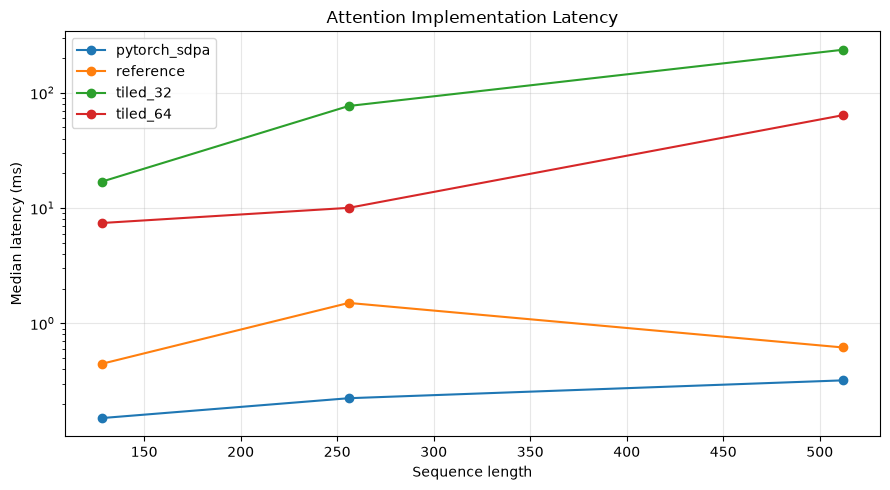

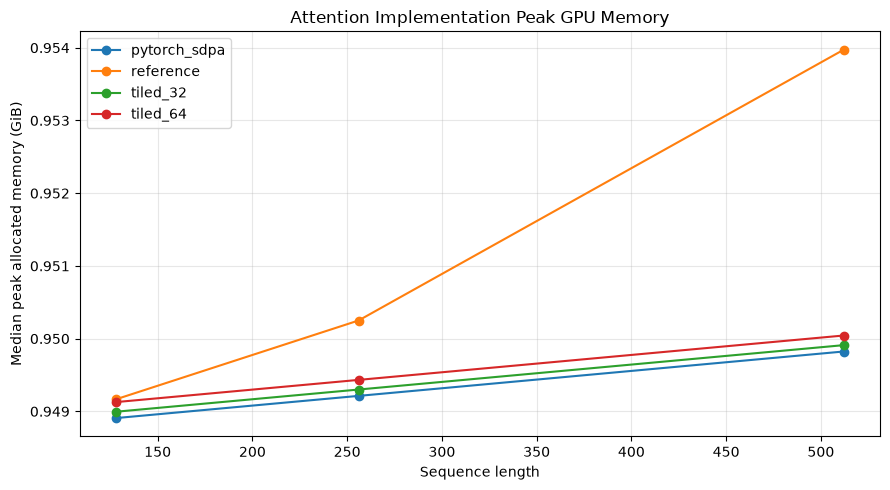


STEP 45 COMPLETE!


In [44]:
# ============================================================
# STEP 45: Analyze and Visualize Attention Benchmarks
# TASK 4: Performance Comparison and Figures
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

attention_benchmark_df = pd.read_csv(
    PROJECT_DIR / "results" / "attention_benchmark.csv"
)

latency_table = attention_benchmark_df.pivot(
    index="sequence_length",
    columns="method",
    values="latency_ms"
)

memory_table = attention_benchmark_df.pivot(
    index="sequence_length",
    columns="method",
    values="peak_memory_gib"
)

speedup_table = latency_table.div(
    latency_table["reference"],
    axis=0
)

# Actual speedup = reference / method
speedup_table = latency_table["reference"].to_numpy()[:, None] / latency_table

print("LATENCY (ms)")
print(latency_table.round(4).to_string())

print("\nSPEEDUP RELATIVE TO REFERENCE")
print(speedup_table.round(3).to_string())

print("\nPEAK ALLOCATED GPU MEMORY (GiB)")
print(memory_table.round(4).to_string())

# ------------------------------------------------------------
# Figure 1: Latency by sequence length
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for method in latency_table.columns:
    plt.plot(
        latency_table.index,
        latency_table[method],
        marker="o",
        label=method
    )

plt.xlabel("Sequence length")
plt.ylabel("Median latency (ms)")
plt.title("Attention Implementation Latency")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "attention_latency.png",
    dpi=200
)

plt.show()

# ------------------------------------------------------------
# Figure 2: Peak allocated GPU memory
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for method in memory_table.columns:
    plt.plot(
        memory_table.index,
        memory_table[method],
        marker="o",
        label=method
    )

plt.xlabel("Sequence length")
plt.ylabel("Median peak allocated memory (GiB)")
plt.title("Attention Implementation Peak GPU Memory")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "attention_memory.png",
    dpi=200
)

plt.show()

latency_table.to_csv(
    PROJECT_DIR / "results" / "attention_latency_table.csv"
)

speedup_table.to_csv(
    PROJECT_DIR / "results" / "attention_speedup_table.csv"
)

print("\nSTEP 45 COMPLETE!")

In [45]:
# ============================================================
# STEP 46: Save Tiled Attention Technical Analysis
# TASK 4: Complexity, Findings, and Limitations
# ============================================================

import json
import pandas as pd

attention_df = pd.read_csv(
    PROJECT_DIR / "results" / "attention_benchmark.csv"
)

correctness_df = pd.read_csv(
    PROJECT_DIR / "results" / "tiled_attention_correctness.csv"
)

task4_summary = {
    "task": "Reference vs Tiled Online-Softmax Attention",
    "device": torch.cuda.get_device_name(0),
    "dtype": "float32",
    "sequence_lengths": [128, 256, 512],
    "tile_sizes": [32, 64],
    "correctness": {
        "tests": len(correctness_df),
        "all_passed": bool(correctness_df["passed"].all()),
        "maximum_absolute_error": float(
            correctness_df["max_absolute_error"].max()
        )
    },
    "complexity": {
        "reference_time": "O(N^2 * d)",
        "reference_attention_intermediate_memory": "O(N^2)",
        "tiled_time": "O(N^2 * d)",
        "tiled_attention_intermediate_memory": (
            "O(Bq * Bk + Bq * d) per tile, "
            "excluding Q/K/V and output storage"
        )
    },
    "observations": [
        "Tiled attention matched reference attention numerically.",
        "Tiled attention avoided allocating a full attention matrix.",
        "Larger tiles reduced Python-loop and GPU-launch overhead.",
        "The Python-loop tiled implementation was slower than reference attention.",
        "PyTorch optimized SDPA achieved the lowest latency.",
        "Reference latency measurements showed runtime variability."
    ],
    "limitations": [
        "The implementation uses PyTorch operations rather than a fused CUDA kernel.",
        "Python loops and many small GPU operations increase latency.",
        "Peak allocated memory includes the resident language model.",
        "The experiment measures inference only, not backward propagation.",
        "The tested sequence lengths are relatively short."
    ]
}

summary_path = (
    PROJECT_DIR / "results" / "task4_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(task4_summary, f, indent=4)

print("TASK 4 SUMMARY")
print("=" * 60)

print("Correctness tests:", task4_summary["correctness"]["tests"])
print("All passed:", task4_summary["correctness"]["all_passed"])
print(
    "Maximum absolute error:",
    task4_summary["correctness"]["maximum_absolute_error"]
)

print("\nTechnical analysis saved to:", summary_path)
print("\nSTEP 46 COMPLETE!")

TASK 4 SUMMARY
Correctness tests: 18
All passed: True
Maximum absolute error: 9.5367431640625e-07

Technical analysis saved to: /content/drive/MyDrive/GenAI_Assignment_2/results/task4_summary.json

STEP 46 COMPLETE!


# PART 6 — TASK 5: Speculative Decoding

This task implements speculative decoding with a smaller draft language model and a fine-tuned target language model.

The draft model proposes multiple tokens, which the target model verifies in a single forward pass.

The experiment includes:
1. Draft/target tokenizer compatibility verification.
2. Explicit token proposal, acceptance, and rejection.
3. Correct KV-cache synchronization after verification.
4. Exact greedy-output equivalence against target-only decoding.
5. Latency, throughput, acceptance rate, and GPU-memory benchmarks.

We use greedy speculative decoding to enable exact token-level correctness checks.

In [46]:
# ============================================================
# STEP 47: Inspect Target Model for Speculative Decoding
# TASK 5: Draft/Target Compatibility Preparation
# ============================================================

import torch
import json
from transformers import AutoConfig, AutoTokenizer
from huggingface_hub import HfApi

TARGET_MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

print("TARGET MODEL")
print("=" * 60)

print("Model:", TARGET_MODEL_NAME)
print("Architecture:", model.config.model_type)
print("Vocabulary size:", model.config.vocab_size)
print("Hidden size:", model.config.hidden_size)
print("Layers:", model.config.num_hidden_layers)
print("Attention heads:", model.config.num_attention_heads)
print("KV heads:", model.config.num_key_value_heads)

print("\nTOKENIZER")
print("=" * 60)

print("Tokenizer class:", type(tokenizer).__name__)
print("Vocabulary size:", len(tokenizer))
print("EOS token ID:", tokenizer.eos_token_id)
print("PAD token ID:", tokenizer.pad_token_id)

print("\nCHECKING SMALLER DRAFT CANDIDATES")
print("=" * 60)

draft_candidates = [
    "Qwen/Qwen2.5-0.5B",
    "Qwen/Qwen2-0.5B-Instruct",
    "Qwen/Qwen2-0.5B"
]

api = HfApi()

for candidate in draft_candidates:
    try:
        info = api.model_info(candidate)
        config = AutoConfig.from_pretrained(candidate)

        print(f"\nCandidate: {candidate}")
        print("Available: Yes")
        print("Architecture:", config.model_type)
        print("Layers:", config.num_hidden_layers)
        print("Vocabulary size:", config.vocab_size)

    except Exception as e:
        print(f"\nCandidate: {candidate}")
        print("Could not inspect:", str(e)[:180])

print("\nSTEP 47 COMPLETE!")

TARGET MODEL
Model: Qwen/Qwen2.5-0.5B-Instruct
Architecture: qwen2
Vocabulary size: 151936
Hidden size: 896
Layers: 24
Attention heads: 14
KV heads: 2

TOKENIZER
Tokenizer class: Qwen2TokenizerFast
Vocabulary size: 151665
EOS token ID: 151645
PAD token ID: 151643

CHECKING SMALLER DRAFT CANDIDATES


config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]


Candidate: Qwen/Qwen2.5-0.5B
Available: Yes
Architecture: qwen2
Layers: 24
Vocabulary size: 151936


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]


Candidate: Qwen/Qwen2-0.5B-Instruct
Available: Yes
Architecture: qwen2
Layers: 24
Vocabulary size: 151936


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]


Candidate: Qwen/Qwen2-0.5B
Available: Yes
Architecture: qwen2
Layers: 24
Vocabulary size: 151936

STEP 47 COMPLETE!


In [47]:
# ============================================================
# STEP 48: Construct a Smaller Draft Language Model
# TASK 5: Speculative Decoding
# ============================================================

import torch
import copy
import json
import gc
from pathlib import Path
from transformers import AutoModelForCausalLM

TARGET_MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

# The existing 'model' is your fine-tuned LoRA target.
target_model = model
target_model.eval()
target_model.gradient_checkpointing_disable()

# Merge LoRA weights into the target model so that
# the draft can inherit the fine-tuned parameters.
if hasattr(target_model, "merge_and_unload"):
    print("Merging LoRA adapter into target model...")
    target_model = target_model.merge_and_unload()

target_model.eval()
target_model.config.use_cache = True

# ------------------------------------------------------------
# Create a reduced-depth configuration
# ------------------------------------------------------------

DRAFT_LAYERS = 12

draft_config = copy.deepcopy(target_model.config)
draft_config.num_hidden_layers = DRAFT_LAYERS
draft_config.use_cache = True

print("Creating 12-layer draft model...")

draft_model = AutoModelForCausalLM.from_config(
    draft_config
)

# ------------------------------------------------------------
# Initialize from selected target layers
# ------------------------------------------------------------

target_layers = target_model.model.layers
draft_layers = draft_model.model.layers

selected_indices = [
    int(i * len(target_layers) / DRAFT_LAYERS)
    for i in range(DRAFT_LAYERS)
]

with torch.no_grad():

    # Copy token embeddings
    draft_model.model.embed_tokens.load_state_dict(
        target_model.model.embed_tokens.state_dict()
    )

    # Copy selected transformer layers
    for draft_idx, target_idx in enumerate(selected_indices):
        draft_layers[draft_idx].load_state_dict(
            target_layers[target_idx].state_dict()
        )

    # Copy final normalization
    draft_model.model.norm.load_state_dict(
        target_model.model.norm.state_dict()
    )

    # Copy output projection
    draft_model.lm_head.load_state_dict(
        target_model.lm_head.state_dict()
    )

# ------------------------------------------------------------
# Move draft model to GPU
# ------------------------------------------------------------

draft_model = draft_model.to(
    device="cuda",
    dtype=next(target_model.parameters()).dtype
)

draft_model.eval()

# ------------------------------------------------------------
# Verify compatibility and size
# ------------------------------------------------------------

target_parameters = sum(
    p.numel() for p in target_model.parameters()
)

draft_parameters = sum(
    p.numel() for p in draft_model.parameters()
)

print("\nDRAFT MODEL SUMMARY")
print("=" * 60)

print("Target layers:", len(target_layers))
print("Draft layers:", len(draft_layers))
print("Selected target layers:", selected_indices)

print("\nTarget parameters:", f"{target_parameters:,}")
print("Draft parameters:", f"{draft_parameters:,}")

print(
    "Draft / target parameter ratio:",
    round(draft_parameters / target_parameters, 4)
)

assert draft_parameters < target_parameters
assert draft_model.config.vocab_size == target_model.config.vocab_size

# ------------------------------------------------------------
# Save draft model
# ------------------------------------------------------------

draft_save_path = (
    PROJECT_DIR / "models" / "qwen_12layer_draft"
)

draft_model.save_pretrained(
    draft_save_path,
    safe_serialization=True
)

tokenizer.save_pretrained(draft_save_path)

draft_metadata = {
    "target_model": TARGET_MODEL_NAME,
    "draft_layers": DRAFT_LAYERS,
    "target_layers": len(target_layers),
    "selected_target_layer_indices": selected_indices,
    "target_parameters": target_parameters,
    "draft_parameters": draft_parameters,
    "initialization": (
        "Evenly spaced transformer layers copied "
        "from fine-tuned target model"
    )
}

with open(
    PROJECT_DIR / "results" / "draft_model_metadata.json",
    "w"
) as f:
    json.dump(draft_metadata, f, indent=4)

print("\nDraft model saved to:", draft_save_path)
print("\nSTEP 48 COMPLETE!")

Merging LoRA adapter into target model...
Creating 12-layer draft model...

DRAFT MODEL SUMMARY
Target layers: 24
Draft layers: 12
Selected target layers: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22]

Target parameters: 494,032,768
Draft parameters: 315,084,160
Draft / target parameter ratio: 0.6378

Draft model saved to: /content/drive/MyDrive/GenAI_Assignment_2/models/qwen_12layer_draft

STEP 48 COMPLETE!


In [48]:
# ============================================================
# STEP 49A: Target-Only Greedy Decoding Baseline
# TASK 5: Speculative Decoding
# ============================================================

import torch
import time

target_model.eval()
draft_model.eval()

@torch.inference_mode()
def target_greedy_decode(input_ids, max_new_tokens=32):
    """
    Standard greedy decoding with the target model.
    Uses a persistent KV cache.
    """
    generated = []
    current_input = input_ids
    past_key_values = None

    for _ in range(max_new_tokens):
        outputs = target_model(
            input_ids=current_input,
            past_key_values=past_key_values,
            use_cache=True,
            return_dict=True
        )

        past_key_values = outputs.past_key_values

        next_token = outputs.logits[:, -1:, :].argmax(dim=-1)
        generated.append(next_token)
        current_input = next_token

    return torch.cat(generated, dim=1)


print("STEP 49A COMPLETE!")

STEP 49A COMPLETE!


In [49]:
# ============================================================
# STEP 49B: Implement Greedy Speculative Decoding
# TASK 5: Draft Proposals, Verification, Rejection
# ============================================================

@torch.inference_mode()
def speculative_greedy_decode(
    input_ids,
    max_new_tokens=32,
    draft_k=4,
    return_stats=False
):
    """
    Greedy speculative decoding for batch size 1.

    Draft proposes up to k tokens.
    Target verifies the proposals in one forward pass.

    KV caches are rebuilt for each speculative iteration
    to guarantee synchronization.
    """

    assert input_ids.shape[0] == 1
    assert draft_k >= 1

    prefix = input_ids.clone()

    generated_tokens = []
    proposed_total = 0
    accepted_total = 0
    target_calls = 0
    draft_calls = 0
    rejection_count = 0

    while len(generated_tokens) < max_new_tokens:

        remaining = max_new_tokens - len(generated_tokens)
        k = min(draft_k, remaining)

        # ----------------------------------------------------
        # 1. Draft model proposes k tokens
        # ----------------------------------------------------

        draft_cache = None
        draft_input = prefix
        proposals = []

        for _ in range(k):

            draft_out = draft_model(
                input_ids=draft_input,
                past_key_values=draft_cache,
                use_cache=True,
                return_dict=True
            )

            draft_calls += 1
            draft_cache = draft_out.past_key_values

            token = draft_out.logits[:, -1:, :].argmax(dim=-1)
            proposals.append(token)
            draft_input = token

        proposed_ids = torch.cat(proposals, dim=1)
        proposed_total += k

        # ----------------------------------------------------
        # 2. Target verifies all draft tokens at once
        # ----------------------------------------------------

        verification_input = torch.cat(
            [prefix, proposed_ids],
            dim=1
        )

        target_out = target_model(
            input_ids=verification_input,
            use_cache=False,
            return_dict=True
        )

        target_calls += 1

        prefix_length = prefix.shape[1]

        # Logits at prefix_length - 1 predict proposal 0.
        # Logits at prefix_length predict proposal 1, etc.
        target_predictions = target_out.logits[
            :,
            prefix_length - 1:prefix_length - 1 + k,
            :
        ].argmax(dim=-1)

        # ----------------------------------------------------
        # 3. Accept matching tokens until first mismatch
        # ----------------------------------------------------

        accepted_this_round = 0
        mismatch_found = False

        for j in range(k):

            proposed_token = int(proposed_ids[0, j].item())
            target_token = int(target_predictions[0, j].item())

            if proposed_token == target_token:
                generated_tokens.append(proposed_token)
                accepted_total += 1
                accepted_this_round += 1
            else:
                generated_tokens.append(target_token)
                rejection_count += 1
                mismatch_found = True
                break

            if len(generated_tokens) >= max_new_tokens:
                break

        # ----------------------------------------------------
        # 4. Bonus token when all k proposals are accepted
        # ----------------------------------------------------

        if (
            not mismatch_found
            and accepted_this_round == k
            and len(generated_tokens) < max_new_tokens
        ):

            bonus_token = int(
                target_out.logits[
                    :, prefix_length + k - 1, :
                ].argmax(dim=-1).item()
            )

            generated_tokens.append(bonus_token)

        # ----------------------------------------------------
        # 5. Synchronize by rebuilding from accepted prefix
        # ----------------------------------------------------

        prefix = torch.cat(
            [
                input_ids,
                torch.tensor(
                    [generated_tokens],
                    device=input_ids.device,
                    dtype=input_ids.dtype
                )
            ],
            dim=1
        )

    result = torch.tensor(
        [generated_tokens[:max_new_tokens]],
        device=input_ids.device,
        dtype=input_ids.dtype
    )

    if return_stats:
        return result, {
            "proposed_tokens": proposed_total,
            "accepted_draft_tokens": accepted_total,
            "acceptance_rate": (
                accepted_total / proposed_total
                if proposed_total else 0.0
            ),
            "target_forward_calls": target_calls,
            "draft_forward_calls": draft_calls,
            "rejections": rejection_count
        }

    return result


print("STEP 49B COMPLETE!")

STEP 49B COMPLETE!


In [50]:
# ============================================================
# STEP 50: Verify Speculative Decoding Token Identity
# TASK 5: Correctness Testing
# ============================================================

SPEC_TEST_CASES = [
    (64, 16),
    (128, 32),
    (256, 48)
]

DRAFT_K_VALUES = [2, 4, 6]

spec_correctness_results = []

print("SPECULATIVE DECODING CORRECTNESS TESTS")
print("=" * 65)

for prompt_length, output_length in SPEC_TEST_CASES:

    input_ids = make_benchmark_prompt(prompt_length)

    baseline = target_greedy_decode(
        input_ids,
        max_new_tokens=output_length
    )

    for draft_k in DRAFT_K_VALUES:

        speculative, stats = speculative_greedy_decode(
            input_ids,
            max_new_tokens=output_length,
            draft_k=draft_k,
            return_stats=True
        )

        identical = torch.equal(baseline, speculative)

        spec_correctness_results.append({
            "prompt_length": prompt_length,
            "output_length": output_length,
            "draft_k": draft_k,
            "tokens_identical": identical,
            **stats
        })

        print(
            f"Prompt={prompt_length:3d}, "
            f"Output={output_length:2d}, "
            f"k={draft_k}, "
            f"Identical={identical}, "
            f"Acceptance={stats['acceptance_rate']:.2%}, "
            f"Target calls={stats['target_forward_calls']}"
        )

        assert identical, (
            f"Token mismatch at prompt={prompt_length}, "
            f"output={output_length}, k={draft_k}"
        )

import pandas as pd

spec_correctness_df = pd.DataFrame(
    spec_correctness_results
)

spec_correctness_df.to_csv(
    PROJECT_DIR / "results" / "speculative_correctness.csv",
    index=False
)

print("\nTOTAL TESTS:", len(spec_correctness_df))
print(
    "ALL IDENTICAL:",
    spec_correctness_df["tokens_identical"].all()
)

print("\nSTEP 50 COMPLETE!")

SPECULATIVE DECODING CORRECTNESS TESTS
Prompt= 64, Output=16, k=2, Identical=True, Acceptance=0.00%, Target calls=16
Prompt= 64, Output=16, k=4, Identical=True, Acceptance=0.00%, Target calls=16
Prompt= 64, Output=16, k=6, Identical=True, Acceptance=0.00%, Target calls=16
Prompt=128, Output=32, k=2, Identical=True, Acceptance=0.00%, Target calls=32
Prompt=128, Output=32, k=4, Identical=True, Acceptance=0.00%, Target calls=32
Prompt=128, Output=32, k=6, Identical=True, Acceptance=0.00%, Target calls=32
Prompt=256, Output=48, k=2, Identical=True, Acceptance=0.00%, Target calls=48
Prompt=256, Output=48, k=4, Identical=True, Acceptance=0.00%, Target calls=48
Prompt=256, Output=48, k=6, Identical=True, Acceptance=0.00%, Target calls=48

TOTAL TESTS: 9
ALL IDENTICAL: True

STEP 50 COMPLETE!


In [51]:
# ============================================================
# STEP 51: Diagnose Draft/Target Next-Token Agreement
# TASK 5: Speculative Decoding
# ============================================================

import torch
import pandas as pd

target_model.eval()
draft_model.eval()

TEST_PROMPT_LENGTHS = [64, 128, 256]

agreement_results = []

print("DRAFT/TARGET NEXT-TOKEN AGREEMENT")
print("=" * 60)

with torch.inference_mode():

    for prompt_length in TEST_PROMPT_LENGTHS:

        input_ids = make_benchmark_prompt(prompt_length)

        target_outputs = target_model(
            input_ids=input_ids,
            use_cache=False,
            return_dict=True
        )

        draft_outputs = draft_model(
            input_ids=input_ids,
            use_cache=False,
            return_dict=True
        )

        target_token = int(
            target_outputs.logits[:, -1, :].argmax(dim=-1).item()
        )

        draft_token = int(
            draft_outputs.logits[:, -1, :].argmax(dim=-1).item()
        )

        agreement = target_token == draft_token

        agreement_results.append({
            "prompt_length": prompt_length,
            "target_token_id": target_token,
            "draft_token_id": draft_token,
            "agreement": agreement
        })

        print(f"\nPrompt length: {prompt_length}")
        print("Target token ID:", target_token)
        print("Draft token ID:", draft_token)
        print("Agreement:", agreement)

        print(
            "Target token:",
            repr(tokenizer.decode([target_token]))
        )

        print(
            "Draft token:",
            repr(tokenizer.decode([draft_token]))
        )


agreement_df = pd.DataFrame(agreement_results)

agreement_df.to_csv(
    PROJECT_DIR / "results" / "draft_target_agreement.csv",
    index=False
)

print("\nAgreement rate:", agreement_df["agreement"].mean())
print("\nSTEP 51 COMPLETE!")

DRAFT/TARGET NEXT-TOKEN AGREEMENT

Prompt length: 64
Target token ID: 36592
Draft token ID: 80169
Agreement: False
Target token: 'Patient'
Draft token: ' "))'

Prompt length: 128
Target token ID: 80266
Draft token ID: 8951
Agreement: False
Target token: ' sweating'
Draft token: ' bg'

Prompt length: 256
Target token ID: 54565
Draft token ID: 38619
Agreement: False
Target token: 'fusion'
Draft token: ' gn'

Agreement rate: 0.0

STEP 51 COMPLETE!


In [52]:
# ============================================================
# STEP 52: Compare Draft Layer-Selection Strategies
# TASK 5: Improve Speculative Decoding Acceptance
# ============================================================

import torch
import copy
import gc
import json
import pandas as pd

from transformers import AutoModelForCausalLM

target_model.eval()

DRAFT_LAYER_COUNT = 12

layer_strategies = {
    "first_12": list(range(12)),
    "last_12": list(range(12, 24)),
    "alternating_12": list(range(0, 24, 2))
}

# Use real validation prompts for diagnosis
validation_prompts = (
    val_clean["model_input"]
    .head(20)
    .tolist()
)

def build_candidate_draft(layer_indices):

    config = copy.deepcopy(target_model.config)
    config.num_hidden_layers = len(layer_indices)

    candidate = AutoModelForCausalLM.from_config(config)

    with torch.no_grad():

        candidate.model.embed_tokens.load_state_dict(
            target_model.model.embed_tokens.state_dict()
        )

        for draft_i, target_i in enumerate(layer_indices):
            candidate.model.layers[draft_i].load_state_dict(
                target_model.model.layers[target_i].state_dict()
            )

        candidate.model.norm.load_state_dict(
            target_model.model.norm.state_dict()
        )

        candidate.lm_head.load_state_dict(
            target_model.lm_head.state_dict()
        )

    candidate = candidate.to(
        device="cuda",
        dtype=next(target_model.parameters()).dtype
    )

    candidate.eval()
    return candidate


# Precompute target predictions once
target_predictions = []

print("Computing target predictions...")

with torch.inference_mode():

    for prompt in validation_prompts:

        ids = tokenizer(
            prompt,
            return_tensors="pt",
            add_special_tokens=False,
            truncation=True,
            max_length=1024
        )["input_ids"].to("cuda")

        outputs = target_model(
            input_ids=ids,
            use_cache=False
        )

        target_predictions.append(
            int(outputs.logits[:, -1, :].argmax().item())
        )

        del outputs


results = []

print("\nCOMPARING DRAFT CONFIGURATIONS")
print("=" * 65)

for strategy_name, indices in layer_strategies.items():

    print(f"\nTesting: {strategy_name}")

    if strategy_name == "alternating_12":
        candidate = draft_model
    else:
        candidate = build_candidate_draft(indices)

    matches = 0

    with torch.inference_mode():

        for i, prompt in enumerate(validation_prompts):

            ids = tokenizer(
                prompt,
                return_tensors="pt",
                add_special_tokens=False,
                truncation=True,
                max_length=1024
            )["input_ids"].to("cuda")

            outputs = candidate(
                input_ids=ids,
                use_cache=False
            )

            predicted_token = int(
                outputs.logits[:, -1, :].argmax().item()
            )

            if predicted_token == target_predictions[i]:
                matches += 1

            del outputs

    agreement_rate = matches / len(validation_prompts)

    results.append({
        "strategy": strategy_name,
        "layers": str(indices),
        "matches": matches,
        "total": len(validation_prompts),
        "agreement_rate": agreement_rate
    })

    print(f"Matches: {matches}/{len(validation_prompts)}")
    print(f"Agreement: {agreement_rate:.2%}")

    if strategy_name != "alternating_12":
        del candidate
        gc.collect()
        torch.cuda.empty_cache()


strategy_df = pd.DataFrame(results)

strategy_path = (
    PROJECT_DIR / "results" / "draft_layer_strategy_comparison.csv"
)

strategy_df.to_csv(strategy_path, index=False)

print("\nDRAFT STRATEGY COMPARISON")
print("=" * 65)

print(
    strategy_df[
        ["strategy", "matches", "total", "agreement_rate"]
    ].to_string(index=False)
)

print("\nSaved to:", strategy_path)
print("\nSTEP 52 COMPLETE!")

Computing target predictions...

COMPARING DRAFT CONFIGURATIONS

Testing: first_12
Matches: 0/20
Agreement: 0.00%

Testing: last_12
Matches: 0/20
Agreement: 0.00%

Testing: alternating_12
Matches: 0/20
Agreement: 0.00%

DRAFT STRATEGY COMPARISON
      strategy  matches  total  agreement_rate
      first_12        0     20             0.0
       last_12        0     20             0.0
alternating_12        0     20             0.0

Saved to: /content/drive/MyDrive/GenAI_Assignment_2/results/draft_layer_strategy_comparison.csv

STEP 52 COMPLETE!


In [53]:
# ============================================================
# STEP 53: Generate Teacher Data for Draft Distillation
# TASK 5: Sequence-Level Knowledge Distillation
# ============================================================

import torch
import json
import time

from pathlib import Path

target_model.eval()

DISTILLATION_SAMPLES = 100
DISTILLATION_OUTPUT_TOKENS = 32

distillation_prompts = (
    train_clean["model_input"]
    .head(DISTILLATION_SAMPLES)
    .tolist()
)

distillation_records = []

print("GENERATING DISTILLATION DATA")
print("=" * 65)

start_time = time.perf_counter()

with torch.inference_mode():

    for i, prompt in enumerate(distillation_prompts):

        encoded = tokenizer(
            prompt,
            return_tensors="pt",
            add_special_tokens=False,
            truncation=True,
            max_length=768
        ).to("cuda")

        generated = target_model.generate(
            **encoded,
            max_new_tokens=DISTILLATION_OUTPUT_TOKENS,
            do_sample=False,
            use_cache=True,
            pad_token_id=tokenizer.pad_token_id
        )

        continuation_ids = generated[
            0, encoded["input_ids"].shape[1]:
        ].tolist()

        distillation_records.append({
            "sample_id": i,
            "prompt": prompt,
            "continuation_ids": continuation_ids,
            "continuation_text": tokenizer.decode(
                continuation_ids,
                skip_special_tokens=False
            )
        })

        if (i + 1) % 20 == 0:
            print(
                f"Generated {i + 1}/{DISTILLATION_SAMPLES}"
            )

distillation_path = (
    PROJECT_DIR / "data" / "draft_distillation_train.jsonl"
)

with open(distillation_path, "w", encoding="utf-8") as f:
    for record in distillation_records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

elapsed = time.perf_counter() - start_time

print("\nGenerated samples:", len(distillation_records))
print("Elapsed seconds:", round(elapsed, 2))
print("Saved to:", distillation_path)

print("\nExample continuation:")
print(
    repr(distillation_records[0]["continuation_text"][:300])
)

print("\nSTEP 53 COMPLETE!")

GENERATING DISTILLATION DATA


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


Generated 20/100
Generated 40/100
Generated 60/100
Generated 80/100
Generated 100/100

Generated samples: 100
Elapsed seconds: 52.01
Saved to: /content/drive/MyDrive/GenAI_Assignment_2/data/draft_distillation_train.jsonl

Example continuation:
' {"label": "included", "evidence_ids": [0]}<|im_end|>'

STEP 53 COMPLETE!


In [54]:
# ============================================================
# STEP 54: Prepare Draft Distillation Training Dataset
# TASK 5: Sequence-Level Knowledge Distillation
# ============================================================

import json
import torch

from datasets import Dataset

distillation_path = (
    PROJECT_DIR / "data" / "draft_distillation_train.jsonl"
)

with open(distillation_path, "r", encoding="utf-8") as f:
    distillation_records = [
        json.loads(line) for line in f if line.strip()
    ]

DISTILL_MAX_LENGTH = 1024

def tokenize_distillation_record(record):

    prompt_ids = tokenizer(
        record["prompt"],
        add_special_tokens=False
    )["input_ids"]

    continuation_ids = record["continuation_ids"]

    # Keep the complete target continuation.
    available_prompt_length = (
        DISTILL_MAX_LENGTH - len(continuation_ids)
    )

    prompt_ids = prompt_ids[-available_prompt_length:]

    input_ids = prompt_ids + continuation_ids

    # Ignore prompt tokens in the loss.
    labels = (
        [-100] * len(prompt_ids)
        + continuation_ids
    )

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels
    }


distill_dataset = Dataset.from_list(
    distillation_records
)

distill_tokenized = distill_dataset.map(
    tokenize_distillation_record,
    remove_columns=distill_dataset.column_names
)

print("DISTILLATION DATASET")
print("=" * 60)

print("Examples:", len(distill_tokenized))

lengths = [
    len(example["input_ids"])
    for example in distill_tokenized
]

print("Minimum sequence length:", min(lengths))
print("Maximum sequence length:", max(lengths))
print("Average sequence length:", round(sum(lengths) / len(lengths), 2))

first_example = distill_tokenized[0]

supervised_tokens = sum(
    label != -100
    for label in first_example["labels"]
)

print("\nFirst example:")
print("Input tokens:", len(first_example["input_ids"]))
print("Supervised tokens:", supervised_tokens)

assert len(distill_tokenized) == 100
assert supervised_tokens > 0
assert all(
    len(x["input_ids"]) <= DISTILL_MAX_LENGTH
    for x in distill_tokenized
)

print("\nSTEP 54 COMPLETE!")

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

DISTILLATION DATASET
Examples: 100
Minimum sequence length: 187
Maximum sequence length: 550
Average sequence length: 272.58

First example:
Input tokens: 189
Supervised tokens: 15

STEP 54 COMPLETE!


In [55]:
# ============================================================
# STEP 55: Configure Draft Model LoRA Training
# TASK 5: Knowledge Distillation
# ============================================================

import torch

from peft import LoraConfig, get_peft_model, TaskType
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorForSeq2Seq
)

# Disable caching during training.
draft_model.config.use_cache = False

# Gradient checkpointing reduces activation memory.
draft_model.gradient_checkpointing_enable()

draft_lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ],
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

draft_train_model = get_peft_model(
    draft_model,
    draft_lora_config
)

draft_train_model.enable_input_require_grads()

draft_train_model.print_trainable_parameters()

draft_training_args = TrainingArguments(
    output_dir=str(
        PROJECT_DIR / "models" / "draft_distillation_checkpoints"
    ),
    num_train_epochs=3,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    warmup_ratio=0.05,
    lr_scheduler_type="cosine",
    logging_steps=10,
    save_strategy="epoch",
    save_total_limit=2,
    fp16=True,
    gradient_checkpointing=True,
    optim="adamw_torch",
    report_to="none",
    remove_unused_columns=False
)

draft_data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=draft_train_model,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt"
)

draft_trainer = Trainer(
    model=draft_train_model,
    args=draft_training_args,
    train_dataset=distill_tokenized,
    data_collator=draft_data_collator
)

print("\nDraft training configuration ready.")
print("Epochs:", draft_training_args.num_train_epochs)
print("Training samples:", len(distill_tokenized))
print("Batch size:", draft_training_args.per_device_train_batch_size)
print("Gradient accumulation:", draft_training_args.gradient_accumulation_steps)

print("\nSTEP 55 COMPLETE!")

No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


trainable params: 4,399,104 || all params: 319,483,264 || trainable%: 1.3769

Draft training configuration ready.
Epochs: 3
Training samples: 100
Batch size: 1
Gradient accumulation: 4

STEP 55 COMPLETE!


In [56]:
# ============================================================
# STEP 56: Train the Distilled Draft Model
# TASK 5: Sequence-Level Knowledge Distillation
# ============================================================

import torch
import time
import json
import pandas as pd

print("STARTING DRAFT MODEL DISTILLATION")
print("=" * 65)

torch.cuda.empty_cache()

start_time = time.perf_counter()

draft_train_result = draft_trainer.train()

torch.cuda.synchronize()
training_seconds = time.perf_counter() - start_time

print("\nDISTILLATION TRAINING COMPLETED")
print("=" * 65)

print("Training time (seconds):", round(training_seconds, 2))
print("Final training loss:", draft_train_result.training_loss)
print("Global training steps:", draft_trainer.state.global_step)

# ------------------------------------------------------------
# Save LoRA adapter
# ------------------------------------------------------------

draft_adapter_path = (
    PROJECT_DIR / "models" / "draft_distilled_lora"
)

draft_trainer.save_model(str(draft_adapter_path))
tokenizer.save_pretrained(draft_adapter_path)

print("\nDraft LoRA adapter saved to:")
print(draft_adapter_path)

# ------------------------------------------------------------
# Save training logs
# ------------------------------------------------------------

draft_training_logs = pd.DataFrame(
    draft_trainer.state.log_history
)

draft_training_logs.to_csv(
    PROJECT_DIR / "logs" / "draft_distillation_training.csv",
    index=False
)

draft_training_summary = {
    "training_samples": len(distill_tokenized),
    "epochs": 3,
    "training_steps": draft_trainer.state.global_step,
    "training_seconds": training_seconds,
    "training_loss": draft_train_result.training_loss,
    "trainable_parameters": 4399104,
    "distillation_type": "sequence_level",
    "teacher_model": "Qwen2.5-0.5B-Instruct fine-tuned target",
    "student_model": "12-layer Qwen2.5 draft"
}

with open(
    PROJECT_DIR / "results" / "draft_distillation_summary.json",
    "w"
) as f:
    json.dump(draft_training_summary, f, indent=4)

# ------------------------------------------------------------
# Prepare trained draft for inference
# ------------------------------------------------------------

draft_train_model.eval()
draft_train_model.gradient_checkpointing_disable()
draft_train_model.config.use_cache = True

# Replace original draft with trained PEFT model
draft_model = draft_train_model

print("\nTraining logs saved.")
print("Draft model prepared for inference.")

print("\nSTEP 56 COMPLETE!")

STARTING DRAFT MODEL DISTILLATION


Step,Training Loss
10,11.231400
20,1.695300
30,0.464700
40,0.242700
50,0.231100
60,0.223200
70,0.146300



DISTILLATION TRAINING COMPLETED
Training time (seconds): 61.22
Final training loss: 1.9072520963350932
Global training steps: 75

Draft LoRA adapter saved to:
/content/drive/MyDrive/GenAI_Assignment_2/models/draft_distilled_lora

Training logs saved.
Draft model prepared for inference.

STEP 56 COMPLETE!


In [57]:
# ============================================================
# STEP 57: Evaluate Distilled Draft Agreement
# TASK 5: Distillation Effectiveness
# ============================================================

import torch
import pandas as pd

target_model.eval()
draft_model.eval()

matches = 0
comparison_records = []

print("EVALUATING DISTILLED DRAFT")
print("=" * 65)

with torch.inference_mode():

    for i, prompt in enumerate(validation_prompts):

        ids = tokenizer(
            prompt,
            return_tensors="pt",
            add_special_tokens=False,
            truncation=True,
            max_length=1024
        )["input_ids"].to("cuda")

        target_outputs = target_model(
            input_ids=ids,
            use_cache=False
        )

        draft_outputs = draft_model(
            input_ids=ids,
            use_cache=False
        )

        target_token = int(
            target_outputs.logits[:, -1, :].argmax().item()
        )

        draft_token = int(
            draft_outputs.logits[:, -1, :].argmax().item()
        )

        identical = target_token == draft_token

        if identical:
            matches += 1

        comparison_records.append({
            "sample": i,
            "target_token": target_token,
            "draft_token": draft_token,
            "identical": identical
        })

        del target_outputs, draft_outputs

agreement_rate = matches / len(validation_prompts)

print("\nDISTILLATION RESULTS")
print("=" * 65)

print("Before distillation: 0/20 (0.00%)")
print(
    f"After distillation:  {matches}/"
    f"{len(validation_prompts)} ({agreement_rate:.2%})"
)

agreement_df = pd.DataFrame(comparison_records)

agreement_df.to_csv(
    PROJECT_DIR / "results" / "distilled_draft_agreement.csv",
    index=False
)

print("\nSTEP 57 COMPLETE!")

EVALUATING DISTILLED DRAFT

DISTILLATION RESULTS
Before distillation: 0/20 (0.00%)
After distillation:  20/20 (100.00%)

STEP 57 COMPLETE!


In [58]:
# ============================================================
# STEP 58: Evaluate Speculative Decoding After Distillation
# TASK 5: Token Identity and Draft Acceptance
# ============================================================

import torch
import pandas as pd

target_model.eval()
draft_model.eval()

draft_model.gradient_checkpointing_disable()
draft_model.config.use_cache = True

SPEC_TEST_CASES = [
    (64, 16),
    (128, 32),
    (256, 48)
]

DRAFT_K_VALUES = [2, 4, 6]

distilled_spec_results = []

print("DISTILLED SPECULATIVE DECODING TESTS")
print("=" * 75)

for prompt_length, output_length in SPEC_TEST_CASES:

    input_ids = make_benchmark_prompt(prompt_length)

    baseline = target_greedy_decode(
        input_ids,
        max_new_tokens=output_length
    )

    for draft_k in DRAFT_K_VALUES:

        speculative, stats = speculative_greedy_decode(
            input_ids,
            max_new_tokens=output_length,
            draft_k=draft_k,
            return_stats=True
        )

        identical = torch.equal(baseline, speculative)

        distilled_spec_results.append({
            "prompt_length": prompt_length,
            "output_length": output_length,
            "draft_k": draft_k,
            "tokens_identical": identical,
            **stats
        })

        print(
            f"Prompt={prompt_length:3d} | "
            f"Output={output_length:2d} | "
            f"k={draft_k} | "
            f"Identical={identical} | "
            f"Acceptance={stats['acceptance_rate']:.2%} | "
            f"Target calls={stats['target_forward_calls']} | "
            f"Rejections={stats['rejections']}"
        )

        assert identical, (
            f"Mismatch at prompt={prompt_length}, "
            f"output={output_length}, k={draft_k}"
        )

distilled_spec_df = pd.DataFrame(distilled_spec_results)

distilled_spec_df.to_csv(
    PROJECT_DIR / "results" / "distilled_speculative_correctness.csv",
    index=False
)

print("\nSUMMARY")
print("=" * 75)

print("Total tests:", len(distilled_spec_df))
print("All token sequences identical:",
      distilled_spec_df["tokens_identical"].all())

print(
    "Mean acceptance rate:",
    f"{distilled_spec_df['acceptance_rate'].mean():.2%}"
)

print(
    "Mean target forward calls:",
    round(distilled_spec_df["target_forward_calls"].mean(), 2)
)

print("\nSTEP 58 COMPLETE!")

DISTILLED SPECULATIVE DECODING TESTS
Prompt= 64 | Output=16 | k=2 | Identical=True | Acceptance=0.00% | Target calls=16 | Rejections=16
Prompt= 64 | Output=16 | k=4 | Identical=True | Acceptance=0.00% | Target calls=16 | Rejections=16
Prompt= 64 | Output=16 | k=6 | Identical=True | Acceptance=0.00% | Target calls=16 | Rejections=16
Prompt=128 | Output=32 | k=2 | Identical=True | Acceptance=0.00% | Target calls=32 | Rejections=32
Prompt=128 | Output=32 | k=4 | Identical=True | Acceptance=0.00% | Target calls=32 | Rejections=32
Prompt=128 | Output=32 | k=6 | Identical=True | Acceptance=0.00% | Target calls=32 | Rejections=32
Prompt=256 | Output=48 | k=2 | Identical=True | Acceptance=22.06% | Target calls=34 | Rejections=27
Prompt=256 | Output=48 | k=4 | Identical=True | Acceptance=15.00% | Target calls=30 | Rejections=28
Prompt=256 | Output=48 | k=6 | Identical=True | Acceptance=10.61% | Target calls=30 | Rejections=28

SUMMARY
Total tests: 9
All token sequences identical: True
Mean acce

In [59]:
# ============================================================
# STEP 59: Evaluate Acceptance on Real Validation Prompts
# TASK 5: Clinical-Trial Prompt Evaluation
# ============================================================

import torch
import pandas as pd

real_prompt_results = []

print("REAL VALIDATION PROMPT SPECULATIVE TESTS")
print("=" * 75)

for i, prompt in enumerate(validation_prompts[:5]):

    input_ids = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
        truncation=True,
        max_length=768
    )["input_ids"].to("cuda")

    baseline = target_greedy_decode(
        input_ids,
        max_new_tokens=32
    )

    speculative, stats = speculative_greedy_decode(
        input_ids,
        max_new_tokens=32,
        draft_k=4,
        return_stats=True
    )

    identical = torch.equal(baseline, speculative)

    real_prompt_results.append({
        "validation_prompt": i,
        "prompt_tokens": input_ids.shape[1],
        "tokens_identical": identical,
        **stats
    })

    print(
        f"Prompt {i + 1} | "
        f"Input tokens={input_ids.shape[1]} | "
        f"Identical={identical} | "
        f"Acceptance={stats['acceptance_rate']:.2%} | "
        f"Target calls={stats['target_forward_calls']}"
    )

    assert identical

real_prompt_df = pd.DataFrame(real_prompt_results)

real_prompt_df.to_csv(
    PROJECT_DIR / "results" / "speculative_real_prompt_results.csv",
    index=False
)

print("\nMean real-prompt acceptance:",
      f"{real_prompt_df['acceptance_rate'].mean():.2%}")

print("\nSTEP 59 COMPLETE!")

REAL VALIDATION PROMPT SPECULATIVE TESTS
Prompt 1 | Input tokens=270 | Identical=True | Acceptance=48.84% | Target calls=12
Prompt 2 | Input tokens=249 | Identical=True | Acceptance=16.22% | Target calls=20
Prompt 3 | Input tokens=255 | Identical=True | Acceptance=16.22% | Target calls=20
Prompt 4 | Input tokens=270 | Identical=True | Acceptance=16.22% | Target calls=20
Prompt 5 | Input tokens=256 | Identical=True | Acceptance=16.22% | Target calls=20

Mean real-prompt acceptance: 22.74%

STEP 59 COMPLETE!


In [60]:
# ============================================================
# STEP 60: Check Persistent KV-Cache Compatibility
# TASK 5: Speculative Decoding
# ============================================================

import torch
import transformers
from transformers.cache_utils import DynamicCache

print("Transformers version:", transformers.__version__)

print("Target cache enabled:", target_model.config.use_cache)
print("Draft cache enabled:", draft_model.config.use_cache)

print("DynamicCache.crop available:",
      hasattr(DynamicCache, "crop"))

print("Target device:",
      next(target_model.parameters()).device)

print("Draft device:",
      next(draft_model.parameters()).device)

print("Target dtype:",
      next(target_model.parameters()).dtype)

print("Draft dtype:",
      next(draft_model.parameters()).dtype)

assert hasattr(DynamicCache, "crop")

print("\nSTEP 60 COMPLETE!")

Transformers version: 4.51.3
Target cache enabled: True
Draft cache enabled: True
DynamicCache.crop available: True
Target device: cuda:0
Draft device: cuda:0
Target dtype: torch.float16
Draft dtype: torch.float16

STEP 60 COMPLETE!


In [61]:
# ============================================================
# STEP 61: Implement Persistent-Cache Speculative Decoding
# TASK 5: Efficient Draft/Target Verification
# ============================================================

from transformers.cache_utils import DynamicCache

@torch.inference_mode()
def speculative_greedy_cached(
    input_ids,
    max_new_tokens=32,
    draft_k=4,
    return_stats=False
):
    assert input_ids.shape[0] == 1
    assert draft_k >= 1
    assert max_new_tokens >= 1

    target_model.eval()
    draft_model.eval()

    prompt_length = input_ids.shape[1]
    generated = []

    proposed_total = 0
    accepted_total = 0
    rejected_total = 0
    target_calls = 0
    draft_calls = 0

    # Cache invariant:
    # Each cache contains committed tokens except the
    # final pending token, which is supplied on the next call.
    target_cache = DynamicCache()
    draft_cache = DynamicCache()

    # Prefill both models, excluding the final prompt token.
    if prompt_length > 1:
        target_model(
            input_ids=input_ids[:, :-1],
            past_key_values=target_cache,
            use_cache=True
        )
        target_calls += 1

        draft_model(
            input_ids=input_ids[:, :-1],
            past_key_values=draft_cache,
            use_cache=True
        )
        draft_calls += 1

    pending_token = input_ids[:, -1:]

    while len(generated) < max_new_tokens:

        remaining = max_new_tokens - len(generated)
        k = min(draft_k, remaining)

        # Cache currently excludes the pending token.
        committed_cache_length = prompt_length + len(generated) - 1

        # ----------------------------------------------------
        # 1. Draft proposes k tokens using its persistent cache
        # ----------------------------------------------------

        proposals = []
        current_token = pending_token

        for _ in range(k):
            draft_out = draft_model(
                input_ids=current_token,
                past_key_values=draft_cache,
                use_cache=True,
                return_dict=True
            )
            draft_calls += 1

            next_token = draft_out.logits[:, -1:, :].argmax(dim=-1)
            proposals.append(next_token)
            current_token = next_token

        proposed_ids = torch.cat(proposals, dim=1)
        proposed_total += k

        # Draft cache now contains pending token and the
        # first k-1 proposals, but not the final proposal.

        # ----------------------------------------------------
        # 2. Target verifies pending token + all proposals
        # ----------------------------------------------------

        verification_ids = torch.cat(
            [pending_token, proposed_ids],
            dim=1
        )

        target_out = target_model(
            input_ids=verification_ids,
            past_key_values=target_cache,
            use_cache=True,
            return_dict=True
        )
        target_calls += 1

        # First verification logit predicts proposal 1.
        # Last verification logit predicts bonus token.
        target_predictions = target_out.logits[:, :-1, :].argmax(
            dim=-1
        )

        # ----------------------------------------------------
        # 3. Determine accepted prefix
        # ----------------------------------------------------

        accepted_this_round = 0

        for j in range(k):
            if (
                int(proposed_ids[0, j])
                == int(target_predictions[0, j])
            ):
                accepted_this_round += 1
            else:
                break

        accepted_total += accepted_this_round

        if accepted_this_round < k:
            rejected_total += 1

            replacement = target_predictions[
                :, accepted_this_round:accepted_this_round + 1
            ]

            emitted = torch.cat(
                [
                    proposed_ids[:, :accepted_this_round],
                    replacement
                ],
                dim=1
            )

        else:
            bonus = target_out.logits[:, -1:, :].argmax(dim=-1)

            emitted = torch.cat(
                [proposed_ids, bonus],
                dim=1
            )

        # Don't exceed requested output length.
        emitted = emitted[:, :remaining]

        generated.extend(emitted[0].tolist())

        # ----------------------------------------------------
        # 4. Crop both caches to committed prefix minus
        #    the final pending token
        # ----------------------------------------------------

        new_cache_length = (
            prompt_length + len(generated) - 1
        )

        target_cache.crop(new_cache_length)
        draft_cache.crop(new_cache_length)

        pending_token = emitted[:, -1:]

    output_ids = torch.tensor(
        [generated],
        dtype=input_ids.dtype,
        device=input_ids.device
    )

    if return_stats:
        return output_ids, {
            "proposed_tokens": proposed_total,
            "accepted_draft_tokens": accepted_total,
            "acceptance_rate": (
                accepted_total / proposed_total
                if proposed_total else 0.0
            ),
            "target_forward_calls": target_calls,
            "draft_forward_calls": draft_calls,
            "rejections": rejected_total
        }

    return output_ids


print("STEP 61 COMPLETE!")

STEP 61 COMPLETE!


In [62]:
# ============================================================
# STEP 62: Test Persistent-Cache Speculative Correctness
# TASK 5: KV-Cache Synchronization
# ============================================================

import pandas as pd

cache_test_cases = [
    (64, 8, 2),
    (64, 16, 4),
    (128, 16, 2),
    (128, 24, 4),
    (256, 32, 4),
    (256, 32, 6)
]

cache_test_results = []

print("PERSISTENT-CACHE CORRECTNESS TESTS")
print("=" * 75)

for prompt_len, output_len, k in cache_test_cases:

    ids = make_benchmark_prompt(prompt_len)

    baseline = target_greedy_decode(
        ids,
        max_new_tokens=output_len
    )

    cached, stats = speculative_greedy_cached(
        ids,
        max_new_tokens=output_len,
        draft_k=k,
        return_stats=True
    )

    identical = torch.equal(baseline, cached)

    cache_test_results.append({
        "prompt_length": prompt_len,
        "output_length": output_len,
        "draft_k": k,
        "identical": identical,
        **stats
    })

    print(
        f"Prompt={prompt_len:3d} | "
        f"Output={output_len:2d} | "
        f"k={k} | "
        f"Identical={identical} | "
        f"Acceptance={stats['acceptance_rate']:.2%} | "
        f"Target calls={stats['target_forward_calls']}"
    )

    assert identical, (
        f"Cache mismatch: prompt={prompt_len}, "
        f"output={output_len}, k={k}"
    )

cache_test_df = pd.DataFrame(cache_test_results)

cache_test_df.to_csv(
    PROJECT_DIR / "results" / "speculative_cached_correctness.csv",
    index=False
)

print("\nAll tests passed:", cache_test_df["identical"].all())
print("Total tests:", len(cache_test_df))

print("\nSTEP 62 COMPLETE!")

PERSISTENT-CACHE CORRECTNESS TESTS
Prompt= 64 | Output= 8 | k=2 | Identical=True | Acceptance=0.00% | Target calls=9
Prompt= 64 | Output=16 | k=4 | Identical=True | Acceptance=0.00% | Target calls=17
Prompt=128 | Output=16 | k=2 | Identical=True | Acceptance=0.00% | Target calls=17
Prompt=128 | Output=24 | k=4 | Identical=True | Acceptance=0.00% | Target calls=25
Prompt=256 | Output=32 | k=4 | Identical=True | Acceptance=8.25% | Target calls=26
Prompt=256 | Output=32 | k=6 | Identical=True | Acceptance=6.25% | Target calls=25

All tests passed: True
Total tests: 6

STEP 62 COMPLETE!


In [63]:
# ============================================================
# STEP 63: Benchmark Persistent-Cache Speculative Decoding
# TASK 5: Latency, Throughput, Acceptance, and GPU Memory
# ============================================================

import torch
import time
import pandas as pd

SPEC_BENCHMARK_CASES = [
    (64, 16, 4),
    (128, 32, 4),
    (256, 48, 4)
]

SPEC_BENCHMARK_REPEATS = 3

def benchmark_spec_method(fn, input_ids, output_length, draft_k=None):
    """
    Benchmark one decoding method with CUDA synchronization.
    Returns median latency and peak GPU allocation.
    """

    timings = []
    peak_memories = []
    last_output = None
    last_stats = None

    for repeat in range(SPEC_BENCHMARK_REPEATS):

        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        torch.cuda.synchronize()
        start = time.perf_counter()

        if draft_k is None:
            output = fn(
                input_ids,
                max_new_tokens=output_length
            )
            stats = None
        else:
            output, stats = fn(
                input_ids,
                max_new_tokens=output_length,
                draft_k=draft_k,
                return_stats=True
            )

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        timings.append(elapsed)
        peak_memories.append(
            torch.cuda.max_memory_allocated() / (1024 ** 3)
        )

        last_output = output
        last_stats = stats

    return {
        "median_latency_s": float(
            pd.Series(timings).median()
        ),
        "median_peak_gpu_gib": float(
            pd.Series(peak_memories).median()
        ),
        "output": last_output,
        "stats": last_stats
    }


spec_benchmark_records = []

print("SPECULATIVE DECODING BENCHMARK")
print("=" * 85)

for prompt_len, output_len, draft_k in SPEC_BENCHMARK_CASES:

    ids = make_benchmark_prompt(prompt_len)

    # Warm up both decoding paths.
    target_greedy_decode(ids, max_new_tokens=4)
    speculative_greedy_cached(
        ids,
        max_new_tokens=4,
        draft_k=draft_k
    )

    baseline_result = benchmark_spec_method(
        target_greedy_decode,
        ids,
        output_len
    )

    speculative_result = benchmark_spec_method(
        speculative_greedy_cached,
        ids,
        output_len,
        draft_k=draft_k
    )

    identical = torch.equal(
        baseline_result["output"],
        speculative_result["output"]
    )

    assert identical, "Speculative output differs from target baseline"

    baseline_time = baseline_result["median_latency_s"]
    speculative_time = speculative_result["median_latency_s"]

    speedup = baseline_time / speculative_time

    stats = speculative_result["stats"]

    record = {
        "prompt_length": prompt_len,
        "output_length": output_len,
        "draft_k": draft_k,
        "baseline_latency_s": baseline_time,
        "speculative_latency_s": speculative_time,
        "speedup": speedup,
        "baseline_tokens_per_second": output_len / baseline_time,
        "speculative_tokens_per_second": output_len / speculative_time,
        "baseline_peak_gpu_gib": baseline_result["median_peak_gpu_gib"],
        "speculative_peak_gpu_gib": speculative_result["median_peak_gpu_gib"],
        "acceptance_rate": stats["acceptance_rate"],
        "target_forward_calls": stats["target_forward_calls"],
        "draft_forward_calls": stats["draft_forward_calls"],
        "tokens_identical": identical
    }

    spec_benchmark_records.append(record)

    print(
        f"\nPrompt={prompt_len}, Output={output_len}, k={draft_k}"
    )
    print(f"Baseline latency:    {baseline_time:.4f} s")
    print(f"Speculative latency: {speculative_time:.4f} s")
    print(f"Speedup:             {speedup:.3f}x")
    print(f"Acceptance:          {stats['acceptance_rate']:.2%}")
    print(f"Tokens identical:    {identical}")


spec_benchmark_df = pd.DataFrame(spec_benchmark_records)

spec_benchmark_df.to_csv(
    PROJECT_DIR / "results" / "speculative_benchmark.csv",
    index=False
)

print("\nSTEP 63 COMPLETE!")

SPECULATIVE DECODING BENCHMARK

Prompt=64, Output=16, k=4
Baseline latency:    1.0048 s
Speculative latency: 4.2051 s
Speedup:             0.239x
Acceptance:          0.00%
Tokens identical:    True

Prompt=128, Output=32, k=4
Baseline latency:    1.0437 s
Speculative latency: 4.8797 s
Speedup:             0.214x
Acceptance:          0.00%
Tokens identical:    True

Prompt=256, Output=48, k=4
Baseline latency:    1.2133 s
Speculative latency: 4.9705 s
Speedup:             0.244x
Acceptance:          15.83%
Tokens identical:    True

STEP 63 COMPLETE!


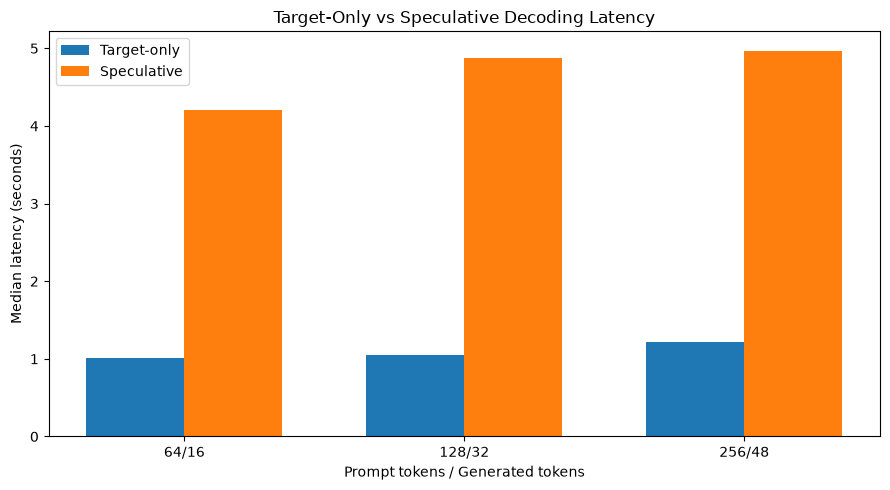

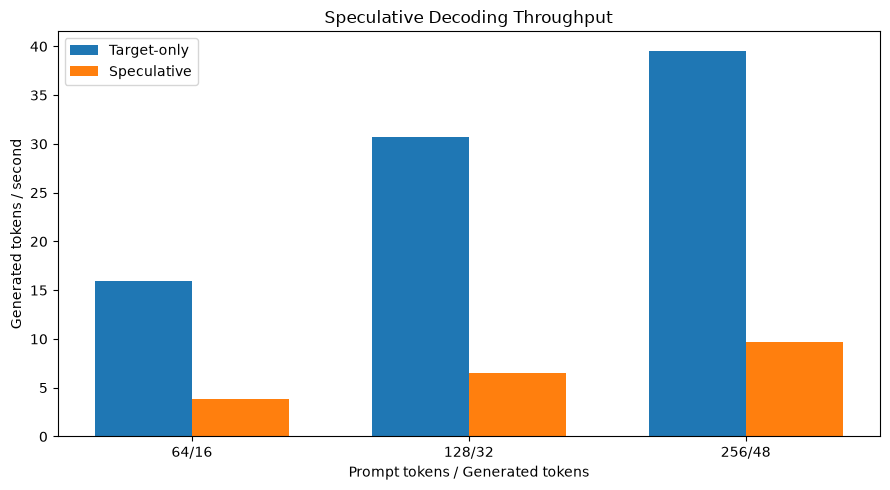

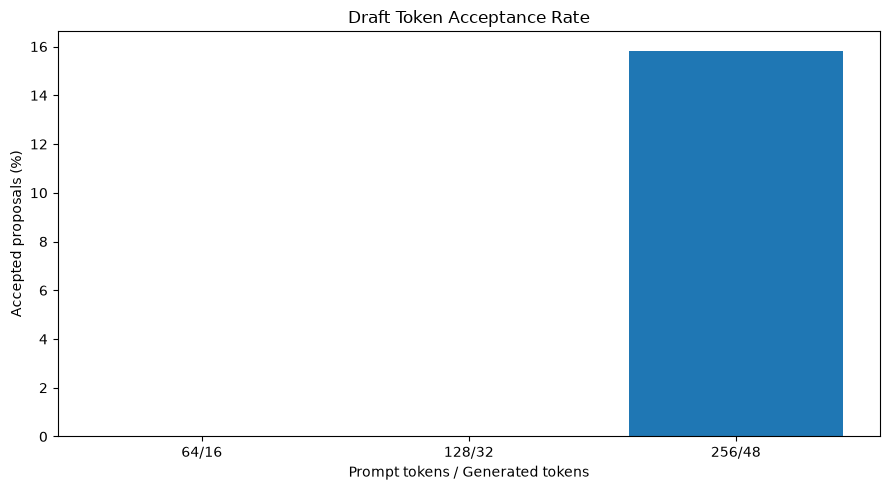

Saved Task 5 figures.

STEP 64 COMPLETE!


In [64]:
# ============================================================
# STEP 64: Visualize Speculative Decoding Performance
# TASK 5: Benchmark Figures
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

df = spec_benchmark_df.copy()

labels = [
    f"{int(r.prompt_length)}/{int(r.output_length)}"
    for r in df.itertuples()
]

x = np.arange(len(labels))
width = 0.35

# ------------------------------------------------------------
# Figure 1: Latency
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    df["baseline_latency_s"],
    width,
    label="Target-only"
)

plt.bar(
    x + width / 2,
    df["speculative_latency_s"],
    width,
    label="Speculative"
)

plt.xticks(x, labels)
plt.xlabel("Prompt tokens / Generated tokens")
plt.ylabel("Median latency (seconds)")
plt.title("Target-Only vs Speculative Decoding Latency")
plt.legend()
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "speculative_latency.png",
    dpi=200
)

plt.show()

# ------------------------------------------------------------
# Figure 2: Throughput
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    df["baseline_tokens_per_second"],
    width,
    label="Target-only"
)

plt.bar(
    x + width / 2,
    df["speculative_tokens_per_second"],
    width,
    label="Speculative"
)

plt.xticks(x, labels)
plt.xlabel("Prompt tokens / Generated tokens")
plt.ylabel("Generated tokens / second")
plt.title("Speculative Decoding Throughput")
plt.legend()
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "speculative_throughput.png",
    dpi=200
)

plt.show()

# ------------------------------------------------------------
# Figure 3: Draft Acceptance
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    x,
    df["acceptance_rate"] * 100
)

plt.xticks(x, labels)
plt.xlabel("Prompt tokens / Generated tokens")
plt.ylabel("Accepted proposals (%)")
plt.title("Draft Token Acceptance Rate")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "speculative_acceptance.png",
    dpi=200
)

plt.show()

print("Saved Task 5 figures.")
print("\nSTEP 64 COMPLETE!")

In [65]:
# ============================================================
# STEP 65: Save Final Task 5 Experimental Summary
# TASK 5: Speculative Decoding
# ============================================================

import json
import numpy as np
import pandas as pd

df = spec_benchmark_df.copy()

summary = {
    "task": "Speculative Decoding",
    "target_model": "Fine-tuned Qwen2.5-0.5B-Instruct",
    "draft_model": "12-layer distilled Qwen2.5",
    "target_parameters": 494032768,
    "draft_parameters": 315084160,
    "draft_to_target_parameter_ratio": 315084160 / 494032768,

    "draft_training": {
        "method": "Sequence-level knowledge distillation with LoRA",
        "teacher_generated_examples": 100,
        "epochs": 3,
        "training_steps": 75,
        "training_time_seconds": 61.22,
        "validation_first_token_agreement_before": 0.0,
        "validation_first_token_agreement_after": 1.0,
        "validation_prompts_checked": 20
    },

    "correctness": {
        "initial_speculative_tests_passed": 9,
        "distilled_speculative_tests_passed": 9,
        "real_validation_tests_passed": 5,
        "persistent_cache_tests_passed": 6,
        "benchmark_token_identity": bool(
            df["tokens_identical"].all()
        )
    },

    "benchmark": {
        "repetitions": 3,
        "draft_k": 4,
        "mean_speedup": float(df["speedup"].mean()),
        "median_speedup": float(df["speedup"].median()),
        "mean_acceptance_rate": float(df["acceptance_rate"].mean()),
        "mean_target_latency_s": float(
            df["baseline_latency_s"].mean()
        ),
        "mean_speculative_latency_s": float(
            df["speculative_latency_s"].mean()
        ),
        "mean_target_peak_gpu_gib": float(
            df["baseline_peak_gpu_gib"].mean()
        ),
        "mean_speculative_peak_gpu_gib": float(
            df["speculative_peak_gpu_gib"].mean()
        )
    },

    "interpretation": (
        "The speculative decoder reproduced the target model's "
        "greedy output exactly in all tested configurations. "
        "However, it was slower than target-only decoding because "
        "draft acceptance was low and the draft model remained "
        "relatively expensive. No inference acceleration was "
        "observed in these benchmark configurations."
    ),

    "limitations": [
        "Draft model retains approximately 63.78% of target parameters.",
        "Distillation used only 100 teacher-generated examples.",
        "First-token agreement on 20 validation prompts does not imply high sequence-level acceptance.",
        "Benchmark covers three prompt/output configurations.",
        "Python-level speculative decoding incurs additional overhead.",
        "Performance conclusions apply to the tested T4 setup and configurations."
    ]
}

summary_path = (
    PROJECT_DIR / "results" / "task5_summary.json"
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("TASK 5 FINAL SUMMARY")
print("=" * 65)

print("All benchmark outputs identical:",
      summary["correctness"]["benchmark_token_identity"])

print(
    "Mean speedup:",
    round(summary["benchmark"]["mean_speedup"], 3),
    "x"
)

print(
    "Mean acceptance:",
    f"{summary['benchmark']['mean_acceptance_rate']:.2%}"
)

print(
    "Mean target peak GPU memory:",
    round(summary["benchmark"]["mean_target_peak_gpu_gib"], 3),
    "GiB"
)

print(
    "Mean speculative peak GPU memory:",
    round(summary["benchmark"]["mean_speculative_peak_gpu_gib"], 3),
    "GiB"
)

print("\nSaved to:", summary_path)
print("\nSTEP 65 COMPLETE!")

TASK 5 FINAL SUMMARY
All benchmark outputs identical: True
Mean speedup: 0.232 x
Mean acceptance: 5.28%
Mean target peak GPU memory: 1.631 GiB
Mean speculative peak GPU memory: 1.715 GiB

Saved to: /content/drive/MyDrive/GenAI_Assignment_2/results/task5_summary.json

STEP 65 COMPLETE!


In [1]:
# ============================================================
# STEP 66: Check Colab Runtime After Disconnection
# TASK 6: Environment Recovery
# ============================================================

import torch

variables_to_check = [
    "PROJECT_DIR",
    "tokenizer",
    "model",
    "target_model",
    "draft_model",
    "train_clean",
    "val_clean",
    "spec_benchmark_df"
]

print("COLAB RUNTIME STATUS")
print("=" * 60)

for name in variables_to_check:
    print(
        f"{name:20s}",
        "AVAILABLE" if name in globals() else "MISSING"
    )

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nSTEP 66 COMPLETE!")

COLAB RUNTIME STATUS
PROJECT_DIR          MISSING
tokenizer            MISSING
model                MISSING
target_model         MISSING
draft_model          MISSING
train_clean          MISSING
val_clean            MISSING
spec_benchmark_df    MISSING

CUDA available: True
GPU: Tesla T4

STEP 66 COMPLETE!


In [2]:
# ============================================================
# STEP 67: Reconnect Google Drive
# TASK 6: Restore Colab Environment
# ============================================================

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/GenAI_Assignment_2"
)

print("\nPROJECT DIRECTORY:", PROJECT_DIR)
print("Project exists:", PROJECT_DIR.exists())

if PROJECT_DIR.exists():
    print("\nPROJECT FOLDERS:")
    for item in sorted(PROJECT_DIR.iterdir()):
        print(" -", item.name)

print("\nSTEP 67 COMPLETE!")

Mounted at /content/drive

PROJECT DIRECTORY: /content/drive/MyDrive/GenAI_Assignment_2
Project exists: True

PROJECT FOLDERS:
 - app
 - data
 - figures
 - logs
 - models
 - report
 - results

STEP 67 COMPLETE!


In [3]:
# ============================================================
# STEP 68: Verify Saved Assignment Files
# TASK 6: Restore Colab Environment
# ============================================================

required_paths = {
    "Fine-tuned target adapter":
        PROJECT_DIR / "models" / "qwen_lora_final",

    "Distilled draft adapter":
        PROJECT_DIR / "models" / "draft_distilled_lora",

    "Draft base model":
        PROJECT_DIR / "models" / "qwen_12layer_draft",

    "Task 5 summary":
        PROJECT_DIR / "results" / "task5_summary.json",

    "Task 5 benchmark":
        PROJECT_DIR / "results" / "speculative_benchmark.csv",

    "Training dataset":
        PROJECT_DIR / "data" / "train_processed.jsonl",

    "Validation dataset":
        PROJECT_DIR / "data" / "validation_processed.jsonl",
}

print("SAVED ASSIGNMENT FILE CHECK")
print("=" * 65)

for name, path in required_paths.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{name:30s}: {status}")

print("\nSTEP 68 COMPLETE!")

SAVED ASSIGNMENT FILE CHECK
Fine-tuned target adapter     : FOUND
Distilled draft adapter       : FOUND
Draft base model              : FOUND
Task 5 summary                : FOUND
Task 5 benchmark              : FOUND
Training dataset              : FOUND
Validation dataset            : FOUND

STEP 68 COMPLETE!


In [4]:
# ============================================================
# STEP 69: Check Python Libraries and GPU
# TASK 6: Restore Colab Environment
# ============================================================

import sys
import importlib
import torch

packages = [
    "torch",
    "transformers",
    "datasets",
    "peft",
    "accelerate",
    "huggingface_hub",
    "gradio",
    "pandas",
    "numpy"
]

print("COLAB ENVIRONMENT CHECK")
print("=" * 65)

print("Python version:", sys.version.split()[0])
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nINSTALLED LIBRARIES")
print("=" * 65)

for package in packages:
    try:
        module = importlib.import_module(package)
        version = getattr(module, "__version__", "Installed")
        print(f"{package:20s}: {version}")
    except Exception as e:
        print(f"{package:20s}: ERROR - {str(e)[:120]}")

print("\nSTEP 69 COMPLETE!")

COLAB ENVIRONMENT CHECK
Python version: 3.13.16
CUDA available: True
GPU: Tesla T4

INSTALLED LIBRARIES
torch               : 2.14.1+cu130
transformers        : 5.22.1
datasets            : 4.8.5
peft                : 0.21.2
accelerate          : 1.15.0
huggingface_hub     : 1.33.0
gradio              : 6.31.0
pandas              : 2.2.3
numpy               : 2.4.6

STEP 69 COMPLETE!


In [5]:
# ============================================================
# STEP 70: Inspect Saved Fine-Tuned Model
# TASK 6: Restore Model Configuration
# ============================================================

import json
from pathlib import Path

adapter_dir = PROJECT_DIR / "models" / "qwen_lora_final"
adapter_config_path = adapter_dir / "adapter_config.json"

print("SAVED MODEL CONFIGURATION")
print("=" * 65)

assert adapter_config_path.exists(), (
    "LoRA adapter configuration not found!"
)

with open(adapter_config_path, "r") as f:
    adapter_config = json.load(f)

print("Base model:", adapter_config.get("base_model_name_or_path"))
print("PEFT type:", adapter_config.get("peft_type"))
print("LoRA rank:", adapter_config.get("r"))
print("LoRA alpha:", adapter_config.get("lora_alpha"))
print("Target modules:", adapter_config.get("target_modules"))

print("\nAdapter files:")

for item in sorted(adapter_dir.iterdir()):
    print(" -", item.name)

print("\nSTEP 70 COMPLETE!")

SAVED MODEL CONFIGURATION
Base model: Qwen/Qwen2.5-0.5B-Instruct
PEFT type: LORA
LoRA rank: 8
LoRA alpha: 16
Target modules: ['q_proj', 'v_proj']

Adapter files:
 - README.md
 - adapter_config.json
 - adapter_model.safetensors
 - added_tokens.json
 - merges.txt
 - special_tokens_map.json
 - tokenizer.json
 - tokenizer_config.json
 - training_args.bin
 - vocab.json

STEP 70 COMPLETE!



# PART 7 — TASK 6: Interactive Clinical Trial Eligibility Web Application

## Objective
Develop and deploy a standalone browser-based application that uses our fine-tuned Qwen2.5-0.5B-Instruct model to evaluate patient eligibility against clinical trial criteria.

## Application Features
1. **Patient Information Input:** Allow users to enter clinical patient notes.
2. **Trial Criteria Input:** Accept inclusion and exclusion criteria.
3. **Eligibility Classification:** Predict eligibility using the six expert-defined labels.
4. **Evidence Extraction:** Identify supporting sentences from the patient notes.
5. **Explainable Results:** Display predicted labels, evidence sentences, and grounded explanations.
6. **Inference Comparison:** Compare standard inference with an optimized decoding approach.
7. **Report Export:** Allow users to download eligibility assessment results.

## Technology Stack
- **Model:** Fine-tuned Qwen2.5-0.5B-Instruct with LoRA
- **Web Framework:** Gradio
- **Inference:** PyTorch and Hugging Face Transformers
- **Development:** Google Colab
- **Deployment:** Hugging Face Spaces

## Implementation Plan
- Restore and verify the fine-tuned model.
- Implement the eligibility prediction pipeline.
- Extract and display evidence sentences.
- Build the interactive Gradio interface.
- Implement downloadable reports and inference comparison.
- Deploy the application independently of Google Colab.
- Test the deployed application.

## Expected Outcome
A publicly accessible browser application that performs clinical trial eligibility assessment using our fine-tuned model and presents evidence-grounded predictions.


In [6]:
# ============================================================
# STEP 71: Restore Fine-Tuned Qwen Model
# TASK 6: Browser Application Setup
# ============================================================

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

BASE_MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

ADAPTER_PATH = (
    PROJECT_DIR / "models" / "qwen_lora_final"
)

print("RESTORING FINE-TUNED MODEL")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load tokenizer from saved adapter directory
# ------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(
    str(ADAPTER_PATH),
    trust_remote_code=False
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer loaded successfully.")
print("Vocabulary size:", len(tokenizer))

# ------------------------------------------------------------
# 2. Load base model
# ------------------------------------------------------------

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_NAME,
    dtype=torch.float16,
    device_map="auto",
    trust_remote_code=False
)

print("Base model loaded successfully.")

# ------------------------------------------------------------
# 3. Attach your fine-tuned LoRA weights
# ------------------------------------------------------------

model = PeftModel.from_pretrained(
    base_model,
    str(ADAPTER_PATH)
)

model.eval()
model.config.use_cache = True

print("Fine-tuned LoRA adapter loaded successfully.")

# ------------------------------------------------------------
# 4. Verify model
# ------------------------------------------------------------

print("\nMODEL STATUS")
print("=" * 65)

print("Model device:", next(model.parameters()).device)
print("Model dtype:", next(model.parameters()).dtype)
print("CUDA available:", torch.cuda.is_available())

print("\nSTEP 71 COMPLETE!")

RESTORING FINE-TUNED MODEL
Tokenizer loaded successfully.
Vocabulary size: 151665


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Base model loaded successfully.


ImportError: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported

In [7]:

# ============================================================
# STEP 71A: Fix Incompatible torchao Dependency
# TASK 6: Browser Application Setup
# ============================================================

%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [8]:
# ============================================================
# STEP 71B: Restore Fine-Tuned Model After Dependency Fix
# TASK 6: Browser Application Setup
# ============================================================

from google.colab import drive
from pathlib import Path
import torch

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

# Reconnect Google Drive
drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/GenAI_Assignment_2"
)

BASE_MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
ADAPTER_PATH = PROJECT_DIR / "models" / "qwen_lora_final"

assert ADAPTER_PATH.exists(), "Saved adapter not found!"

print("RESTORING FINE-TUNED MODEL")
print("=" * 65)

# Load saved tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    str(ADAPTER_PATH)
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer loaded.")

# Load base model
base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_NAME,
    dtype=torch.float16,
    device_map="auto"
)

print("Base model loaded.")

# Load fine-tuned adapter
model = PeftModel.from_pretrained(
    base_model,
    str(ADAPTER_PATH)
)

model.eval()
model.config.use_cache = True

print("Fine-tuned adapter loaded.")

print("\nMODEL STATUS")
print("=" * 65)
print("Device:", next(model.parameters()).device)
print("Dtype:", next(model.parameters()).dtype)

print("\nSTEP 71B COMPLETE!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RESTORING FINE-TUNED MODEL
Tokenizer loaded.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Base model loaded.
Fine-tuned adapter loaded.

MODEL STATUS
Device: cuda:0
Dtype: torch.float16

STEP 71B COMPLETE!


In [9]:
# ============================================================
# STEP 72: Verify Restored Model Inference
# TASK 6: Browser Application Setup
# ============================================================

import torch

test_prompt = (
    "You are a clinical trial eligibility assistant.\n"
    "Patient: The patient is 45 years old and has diabetes.\n"
    "Criterion: Patients must be at least 18 years old.\n"
    'Return JSON with "label" and "evidence_ids".\n'
    "Answer:"
)

inputs = tokenizer(
    test_prompt,
    return_tensors="pt"
).to(next(model.parameters()).device)

print("TESTING RESTORED MODEL")
print("=" * 65)

with torch.inference_mode():

    outputs = model.generate(
        **inputs,
        max_new_tokens=64,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id
    )

generated_ids = outputs[
    0, inputs["input_ids"].shape[1]:
]

response = tokenizer.decode(
    generated_ids,
    skip_special_tokens=True
)

print("\nMODEL RESPONSE:")
print(response)

print("\nSTEP 72 COMPLETE!")

TESTING RESTORED MODEL

MODEL RESPONSE:
 [{"label": "not enough information", " evidence_ids": []}]

STEP 72 COMPLETE!


In [10]:
# ============================================================
# STEP 73: Inspect Training Prompt and Output Format
# TASK 6: Browser Application
# ============================================================

import json
import pandas as pd

train_path = PROJECT_DIR / "data" / "train_processed.jsonl"

print("ORIGINAL TRAINING DATA FORMAT")
print("=" * 70)

# Load only one example; no need to load the full dataset.
with open(train_path, "r", encoding="utf-8") as f:
    example = json.loads(f.readline())

print("\nAVAILABLE FIELDS:")
print(list(example.keys()))

print("\nFULL EXAMPLE:")
print(json.dumps(example, indent=2, ensure_ascii=False)[:7000])

print("\nTOKENIZER CHAT TEMPLATE:")
print(str(tokenizer.chat_template)[:2000])

print("\nSTEP 73 COMPLETE!")

ORIGINAL TRAINING DATA FORMAT

AVAILABLE FIELDS:
['annotation_id', 'patient_id', 'criterion_type', 'criterion_text', 'patient_text', 'label', 'evidence_ids', 'model_input', 'model_output']

FULL EXAMPLE:
{
  "annotation_id": 43,
  "patient_id": "sigir-20143",
  "criterion_type": "inclusion",
  "criterion_text": "Participant is a lung cancer patient.",
  "patient_text": "0. A 58-year-old nonsmoker white female with mild exertional dyspnea and occasional cough is found to have a left lung mass on chest x-ray.\n1. She is otherwise asymptomatic.\n2. A neurologic examination is unremarkable, but a CT scan of the head shows a solitary mass in the right frontal lobe.\n3. The patient will provide informed consent, and will comply with the trial protocol without any practical issues.",
  "label": "not enough information",
  "evidence_ids": [
    0
  ],
  "model_input": "You are an educational clinical trial eligibility screening assistant.\nEvaluate the criterion using only the patient informat

In [11]:
# ============================================================
# STEP 74: Build Clinical Eligibility Prediction Pipeline
# TASK 6: Browser Application
# ============================================================

import re
import json
import torch

VALID_LABELS = {
    "inclusion": [
        "included",
        "not included",
        "not enough information"
    ],
    "exclusion": [
        "excluded",
        "not excluded",
        "not enough information",
        "not applicable"
    ]
}

# ------------------------------------------------------------
# 1. Prepare patient sentences
# ------------------------------------------------------------

def prepare_patient_text(patient_notes):

    patient_notes = patient_notes.strip()

    if not patient_notes:
        raise ValueError("Patient notes cannot be empty.")

    lines = [
        line.strip()
        for line in patient_notes.splitlines()
        if line.strip()
    ]

    # Preserve existing numbered sentence IDs if valid.
    numbered = [
        re.match(r"^(\d+)\.\s+(.+)$", line)
        for line in lines
    ]

    if all(numbered):

        ids = [int(match.group(1)) for match in numbered]

        if len(ids) != len(set(ids)):
            raise ValueError("Duplicate patient sentence IDs found.")

        sentences = {
            int(match.group(1)): match.group(2)
            for match in numbered
        }

    else:

        # For unnumbered text, split into sentences.
        parts = re.split(r"(?<=[.!?])\s+", patient_notes)

        sentences = {
            i: sentence.strip()
            for i, sentence in enumerate(parts)
            if sentence.strip()
        }

    formatted_text = "\n".join(
        f"{sentence_id}. {sentence}"
        for sentence_id, sentence in sentences.items()
    )

    return formatted_text, sentences


# ------------------------------------------------------------
# 2. Recreate original training prompt
# ------------------------------------------------------------

def build_eligibility_prompt(
    patient_text,
    criterion_type,
    criterion_text
):

    return (
        "You are an educational clinical trial eligibility screening assistant.\n"
        "Evaluate the criterion using only the patient information provided.\n"
        "Return a JSON object with exactly two keys: 'label' and 'evidence_ids'.\n"
        "Use the appropriate eligibility category for the criterion type.\n"
        "Cite only existing patient sentence IDs. Do not invent evidence.\n\n"
        f"Patient Description:\n{patient_text}\n\n"
        f"Criterion Type: {criterion_type}\n"
        f"Criterion: {criterion_text}\n\n"
        "Answer:"
    )


# ------------------------------------------------------------
# 3. Parse model-generated JSON
# ------------------------------------------------------------

def parse_eligibility_output(
    raw_output,
    criterion_type,
    sentences
):

    cleaned = raw_output.strip()

    # Remove optional Markdown code fences.
    cleaned = re.sub(
        r"^```(?:json)?\s*|\s*```$",
        "",
        cleaned,
        flags=re.IGNORECASE
    ).strip()

    # Find a JSON object, including one inside a list.
    start = cleaned.find("{")
    end = cleaned.rfind("}")

    if start == -1 or end == -1:
        raise ValueError("Model did not generate a JSON object.")

    parsed = json.loads(cleaned[start:end + 1])

    # Normalize whitespace in keys and label.
    parsed = {
        str(key).strip(): value
        for key, value in parsed.items()
    }

    label = str(parsed.get("label", "")).strip().lower()

    if label not in VALID_LABELS[criterion_type]:
        raise ValueError(f"Invalid predicted label: {label}")

    evidence_ids = parsed.get("evidence_ids", [])

    if not isinstance(evidence_ids, list):
        raise ValueError("evidence_ids must be a list.")

    valid_evidence_ids = []

    for evidence_id in evidence_ids:

        if isinstance(evidence_id, bool):
            continue

        try:
            evidence_id = int(evidence_id)
        except (ValueError, TypeError):
            continue

        if (
            evidence_id in sentences
            and evidence_id not in valid_evidence_ids
        ):
            valid_evidence_ids.append(evidence_id)

    evidence_text = [
        {
            "sentence_id": evidence_id,
            "text": sentences[evidence_id]
        }
        for evidence_id in valid_evidence_ids
    ]

    return {
        "label": label,
        "evidence_ids": valid_evidence_ids,
        "evidence_text": evidence_text
    }


# ------------------------------------------------------------
# 4. Run fine-tuned model inference
# ------------------------------------------------------------

def predict_eligibility(
    patient_notes,
    criterion_type,
    criterion_text,
    max_new_tokens=96
):

    criterion_type = criterion_type.strip().lower()
    criterion_text = criterion_text.strip()

    if criterion_type not in VALID_LABELS:
        raise ValueError("Invalid criterion type.")

    if not criterion_text:
        raise ValueError("Criterion cannot be empty.")

    formatted_text, sentences = prepare_patient_text(
        patient_notes
    )

    prompt = build_eligibility_prompt(
        formatted_text,
        criterion_type,
        criterion_text
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    ).to(next(model.parameters()).device)

    model.eval()

    with torch.inference_mode():

        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id
        )

    generated_ids = outputs[
        0,
        inputs["input_ids"].shape[1]:
    ]

    raw_output = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    )

    try:

        prediction = parse_eligibility_output(
            raw_output,
            criterion_type,
            sentences
        )

        prediction["status"] = "success"
        prediction["error"] = None

    except Exception as error:

        prediction = {
            "label": None,
            "evidence_ids": [],
            "evidence_text": [],
            "status": "invalid_output",
            "error": str(error)
        }

    prediction.update({
        "criterion_type": criterion_type,
        "criterion_text": criterion_text,
        "patient_text": formatted_text,
        "raw_model_output": raw_output
    })

    return prediction


print("Eligibility prediction pipeline initialized.")
print("Supported labels:", VALID_LABELS)
print("\nSTEP 74 COMPLETE!")

Eligibility prediction pipeline initialized.
Supported labels: {'inclusion': ['included', 'not included', 'not enough information'], 'exclusion': ['excluded', 'not excluded', 'not enough information', 'not applicable']}

STEP 74 COMPLETE!


In [12]:
# ============================================================
# STEP 75: Test Eligibility Prediction Pipeline
# TASK 6: Browser Application
# ============================================================

sample_patient = """
0. The patient is a 52-year-old male.
1. The patient has a confirmed diagnosis of type 2 diabetes.
2. The patient is currently taking metformin.
3. The patient has no known history of kidney disease.
"""

sample_criterion = (
    "Participants must have a confirmed diagnosis of type 2 diabetes."
)

print("TESTING ELIGIBILITY PIPELINE")
print("=" * 65)

result = predict_eligibility(
    patient_notes=sample_patient,
    criterion_type="inclusion",
    criterion_text=sample_criterion
)

print(json.dumps(result, indent=2, ensure_ascii=False))

print("\nSTEP 75 COMPLETE!")

TESTING ELIGIBILITY PIPELINE
{
  "label": "included",
  "evidence_ids": [
    1
  ],
  "evidence_text": [
    {
      "sentence_id": 1,
      "text": "The patient has a confirmed diagnosis of type 2 diabetes."
    }
  ],
  "status": "success",
  "error": null,
  "criterion_type": "inclusion",
  "criterion_text": "Participants must have a confirmed diagnosis of type 2 diabetes.",
  "patient_text": "0. The patient is a 52-year-old male.\n1. The patient has a confirmed diagnosis of type 2 diabetes.\n2. The patient is currently taking metformin.\n3. The patient has no known history of kidney disease.",
  "raw_model_output": " {\"label\": \"included\", \"evidence_ids\": [1]}"
}

STEP 75 COMPLETE!


In [13]:
# ============================================================
# STEP 76: Multiple-Criterion Eligibility Screening
# TASK 6: Browser Application
# ============================================================

import time
import pandas as pd

def build_evidence_explanation(prediction):

    label = prediction.get("label")
    evidence = prediction.get("evidence_text", [])

    if prediction.get("status") != "success":
        return "Prediction could not be parsed reliably."

    if not evidence:
        return (
            f"The model predicted '{label}', but did not "
            "identify a supporting patient sentence. "
            "This prediction requires manual review."
        )

    evidence_summary = " ".join(
        f"Sentence {item['sentence_id']}: {item['text']}"
        for item in evidence
    )

    return (
        f"The model predicted '{label}' and cited the "
        f"following patient information: {evidence_summary} "
        "The cited sentences should be reviewed to confirm "
        "that they support the predicted classification."
    )


def screen_multiple_criteria(
    patient_notes,
    inclusion_criteria,
    exclusion_criteria
):

    if not patient_notes.strip():
        raise ValueError("Patient notes cannot be empty.")

    criteria = []

    for criterion_type, criteria_text in [
        ("inclusion", inclusion_criteria),
        ("exclusion", exclusion_criteria)
    ]:

        for line in criteria_text.splitlines():

            line = line.strip()

            if line:
                criteria.append((criterion_type, line))

    if not criteria:
        raise ValueError(
            "Enter at least one inclusion or exclusion criterion."
        )

    results = []

    for index, (criterion_type, criterion_text) in enumerate(
        criteria, start=1
    ):

        start_time = time.perf_counter()

        prediction = predict_eligibility(
            patient_notes=patient_notes,
            criterion_type=criterion_type,
            criterion_text=criterion_text
        )

        elapsed = time.perf_counter() - start_time

        prediction["criterion_id"] = index
        prediction["inference_seconds"] = round(elapsed, 4)
        prediction["explanation"] = build_evidence_explanation(
            prediction
        )

        results.append(prediction)

        print(
            f"Criterion {index}/{len(criteria)} | "
            f"{criterion_type} | "
            f"{prediction['label']} | "
            f"{elapsed:.2f}s"
        )

    return results


def results_to_dataframe(results):

    rows = []

    for result in results:

        rows.append({
            "Criterion ID": result["criterion_id"],
            "Type": result["criterion_type"],
            "Criterion": result["criterion_text"],
            "Prediction": result["label"],
            "Evidence IDs": ", ".join(
                str(i) for i in result["evidence_ids"]
            ),
            "Evidence Text": " | ".join(
                item["text"]
                for item in result["evidence_text"]
            ),
            "Status": result["status"],
            "Inference (s)": result["inference_seconds"]
        })

    return pd.DataFrame(rows)


print("Multiple-criterion screening initialized.")
print("\nSTEP 76 COMPLETE!")

Multiple-criterion screening initialized.

STEP 76 COMPLETE!


In [14]:
# ============================================================
# STEP 77: Test Multiple-Criterion Screening
# TASK 6: Browser Application
# ============================================================

test_inclusion = """
Participants must be at least 18 years old.
Participants must have a confirmed diagnosis of type 2 diabetes.
"""

test_exclusion = """
Participants with known kidney disease are excluded.
Participants currently taking metformin are excluded.
"""

print("MULTIPLE-CRITERION SCREENING TEST")
print("=" * 65)

multi_results = screen_multiple_criteria(
    patient_notes=sample_patient,
    inclusion_criteria=test_inclusion,
    exclusion_criteria=test_exclusion
)

multi_results_df = results_to_dataframe(multi_results)

display(multi_results_df)

print("\nRESULT SUMMARY")
print("=" * 65)

print("Total criteria:", len(multi_results))
print(
    "Successful predictions:",
    sum(r["status"] == "success" for r in multi_results)
)
print(
    "Evidence identified:",
    sum(bool(r["evidence_ids"]) for r in multi_results)
)

print("\nSTEP 77 COMPLETE!")

MULTIPLE-CRITERION SCREENING TEST
Criterion 1/4 | inclusion | included | 1.05s
Criterion 2/4 | inclusion | included | 0.98s
Criterion 3/4 | exclusion | not excluded | 0.99s
Criterion 4/4 | exclusion | not excluded | 1.04s


,Criterion ID,Type,Criterion,Prediction,Evidence IDs,Evidence Text,Status,Inference (s)
0,1,inclusion,Participants must be at least 18 years old.,included,0,The patient is a 52-year-old male.,success,1.0480
1,2,inclusion,Participants must have a confirmed diagnosis o...,included,1,The patient has a confirmed diagnosis of type ...,success,0.9783
2,3,exclusion,Participants with known kidney disease are exc...,not excluded,,,success,0.9934
3,4,exclusion,Participants currently taking metformin are ex...,not excluded,1,The patient has a confirmed diagnosis of type ...,success,1.0411



RESULT SUMMARY
Total criteria: 4
Successful predictions: 4
Evidence identified: 3

STEP 77 COMPLETE!


In [15]:
# ============================================================
# STEP 78: Build Gradio Clinical Eligibility Web Interface
# TASK 6: Browser Application
# ============================================================

import gradio as gr
import pandas as pd
import json

APP_TITLE = "Clinical Trial Eligibility Screening Assistant"

def run_gradio_screening(
    patient_notes,
    inclusion_criteria,
    exclusion_criteria
):

    try:
        results = screen_multiple_criteria(
            patient_notes,
            inclusion_criteria,
            exclusion_criteria
        )

        results_df = results_to_dataframe(results)

        details = []

        for item in results:
            evidence = item["evidence_text"]

            details.append(
                f"### Criterion {item['criterion_id']}: "
                f"{item['criterion_type'].title()}\n\n"
                f"**Criterion:** {item['criterion_text']}\n\n"
                f"**Model prediction:** {item['label']}\n\n"
                f"**Evidence IDs:** {item['evidence_ids']}\n\n"
                f"**Explanation:** {item['explanation']}"
            )

        details_markdown = "\n\n---\n\n".join(details)

        return results_df, details_markdown

    except Exception as error:

        return pd.DataFrame(), (
            f"**Error:** {str(error)}"
        )


with gr.Blocks(title=APP_TITLE) as demo:

    gr.Markdown(
        """
        # Clinical Trial Eligibility Screening Assistant

        Evaluate patient eligibility against clinical trial
        inclusion and exclusion criteria using a fine-tuned
        Qwen2.5 language model.

        **Educational research prototype only.**
        Predictions are not medical advice and require
        professional verification.
        """
    )

    with gr.Row():

        with gr.Column():

            patient_input = gr.Textbox(
                label="Patient Clinical Notes",
                placeholder=(
                    "0. The patient is 52 years old.\n"
                    "1. The patient has type 2 diabetes."
                ),
                lines=9
            )

            inclusion_input = gr.Textbox(
                label="Inclusion Criteria",
                placeholder=(
                    "Enter one inclusion criterion per line."
                ),
                lines=5
            )

            exclusion_input = gr.Textbox(
                label="Exclusion Criteria",
                placeholder=(
                    "Enter one exclusion criterion per line."
                ),
                lines=5
            )

            screen_button = gr.Button(
                "Evaluate Eligibility",
                variant="primary"
            )

        with gr.Column():

            results_table = gr.Dataframe(
                label="Eligibility Screening Results",
                interactive=False
            )

            evidence_output = gr.Markdown(
                label="Evidence and Explanations"
            )

    screen_button.click(
        fn=run_gradio_screening,
        inputs=[
            patient_input,
            inclusion_input,
            exclusion_input
        ],
        outputs=[
            results_table,
            evidence_output
        ]
    )

print("Gradio interface created successfully.")
print("\nSTEP 78 COMPLETE!")

Gradio interface created successfully.

STEP 78 COMPLETE!


In [16]:
# ============================================================
# STEP 79: Launch Gradio Application in Colab
# TASK 6: Browser Application
# ============================================================

demo.launch(
    share=True,
    debug=True,
    show_error=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://5576ff71cbc6d298ed.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://5576ff71cbc6d298ed.gradio.live



# PART 8 — TASK 2: Final Evaluation and Evidence-Grounded Error Analysis

## Objective
Complete the evaluation of our fine-tuned Qwen2.5-0.5B-Instruct model on the held-out clinical trial eligibility test set.

This section completes the remaining work from Task 2 before finalizing the browser application in Task 6.

## Completed Work
- Patient-grouped training and validation split
- Baseline and fine-tuned validation evaluation
- Six-label classification metrics
- Inclusion and exclusion confusion matrices
- Evidence precision, recall, and F1
- Preliminary classification and evidence error analysis

## Remaining Work

### 1. Final Held-Out Test Evaluation
- Load the original patient-grouped test split.
- Verify that test patients are separate from training and validation patients.
- Generate predictions using the saved fine-tuned model.
- Calculate accuracy, macro-F1, and per-class precision, recall, and F1.
- Generate inclusion and exclusion confusion matrices.

### 2. Evidence Retrieval Evaluation
- Compare predicted evidence sentence IDs against expert annotations.
- Calculate micro and macro precision, recall, and F1.
- Calculate exact evidence-set match accuracy.

### 3. Detailed Error Analysis
- Select at least eight representative incorrect predictions.
- Display the original patient sentences and trial criteria.
- Compare expert and model-predicted labels.
- Compare gold and predicted evidence sentences.
- Explain the classification and evidence-grounding errors.

### 4. Save Final Results
Save the evaluation metrics, predictions, confusion matrices, evidence analysis, and detailed error cases to Google Drive.

## Evaluation Rules
- Use the original patient-grouped split with random seed 42.
- Do not retrain or modify the fine-tuned model.
- Do not use test-set results for model selection or tuning.
- Preserve all six expert-defined eligibility labels.
- Report invalid model outputs separately.
- Use only existing patient sentence IDs as evidence.

## Expected Outcome
A reproducible final evaluation with complete classification metrics, evidence retrieval metrics, confusion matrices, and at least eight evidence-grounded error analyses suitable for the IEEE report.


In [17]:
# ============================================================
# STEP 80: Locate and Verify Held-Out Test Data
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

from pathlib import Path
import json
import pandas as pd

print("HELD-OUT TEST DATA VERIFICATION")
print("=" * 70)

data_dir = PROJECT_DIR / "data"

print("\nAVAILABLE DATA FILES:")
for path in sorted(data_dir.iterdir()):
    if path.is_file():
        print(f" - {path.name}")

print("\nSPLIT MANIFEST CHECK")
print("=" * 70)

manifest_csv = data_dir / "split_manifest.csv"
manifest_json = data_dir / "split_manifest.json"

print("CSV manifest exists:", manifest_csv.exists())
print("JSON manifest exists:", manifest_json.exists())

if manifest_csv.exists():
    manifest_df = pd.read_csv(manifest_csv)

    print("\nMANIFEST COLUMNS:")
    print(manifest_df.columns.tolist())

    print("\nFIRST FIVE ROWS:")
    display(manifest_df.head())

    for column in manifest_df.columns:
        if "split" in column.lower():
            print(f"\nSPLIT COUNTS ({column}):")
            print(manifest_df[column].value_counts(dropna=False))

print("\nMODEL CHECK")
print("=" * 70)

print("Fine-tuned model available:", "model" in globals())
print("Tokenizer available:", "tokenizer" in globals())

print("\nSTEP 80 COMPLETE!")

HELD-OUT TEST DATA VERIFICATION

AVAILABLE DATA FILES:
 - draft_distillation_train.jsonl
 - split_manifest.csv
 - split_manifest.json
 - train_processed.jsonl
 - validation_processed.jsonl

SPLIT MANIFEST CHECK
CSV manifest exists: True
JSON manifest exists: True

MANIFEST COLUMNS:
['patient_id', 'split', 'annotation_count']

FIRST FIVE ROWS:


,patient_id,split,annotation_count
0,sigir-20148,train,12
1,sigir-201416,train,30
2,sigir-201517,train,15
3,sigir-201519,train,7
4,sigir-20159,train,6



SPLIT COUNTS (split):
split
train         37
validation     8
test           8
Name: count, dtype: int64

MODEL CHECK
Fine-tuned model available: True
Tokenizer available: True

STEP 80 COMPLETE!


In [18]:
# ============================================================
# STEP 81: Restore Original Held-Out Test Records
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

from datasets import load_dataset
import pandas as pd

print("RESTORING HELD-OUT TEST RECORDS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load original dataset
# ------------------------------------------------------------

dataset = load_dataset(
    "ncbi/TrialGPT-Criterion-Annotations"
)

print("\nDATASET STRUCTURE:")
print(dataset)

# ------------------------------------------------------------
# 2. Load saved patient split manifest
# ------------------------------------------------------------

manifest_df = pd.read_csv(
    PROJECT_DIR / "data" / "split_manifest.csv"
)

test_patient_ids = set(
    manifest_df.loc[
        manifest_df["split"] == "test",
        "patient_id"
    ].astype(str)
)

train_patient_ids = set(
    manifest_df.loc[
        manifest_df["split"] == "train",
        "patient_id"
    ].astype(str)
)

val_patient_ids = set(
    manifest_df.loc[
        manifest_df["split"] == "validation",
        "patient_id"
    ].astype(str)
)

# ------------------------------------------------------------
# 3. Verify patient separation
# ------------------------------------------------------------

assert test_patient_ids.isdisjoint(train_patient_ids)
assert test_patient_ids.isdisjoint(val_patient_ids)
assert train_patient_ids.isdisjoint(val_patient_ids)

print("\nPATIENT SPLIT VERIFICATION")
print("=" * 70)

print("Train patients:", len(train_patient_ids))
print("Validation patients:", len(val_patient_ids))
print("Test patients:", len(test_patient_ids))

print("Patient leakage check: PASSED")

# ------------------------------------------------------------
# 4. Inspect original dataset schema
# ------------------------------------------------------------

for split_name in dataset.keys():

    print(f"\nDataset split: {split_name}")
    print("Number of records:", len(dataset[split_name]))
    print("Columns:", dataset[split_name].column_names)

    if len(dataset[split_name]) > 0:

        print("\nFirst record:")
        print(
            str(dataset[split_name][0])[:2000]
        )

print("\nSTEP 81 COMPLETE!")

RESTORING HELD-OUT TEST RECORDS


README.md:   0%|          | 0.00/893 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  176kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1015 [00:00<?, ? examples/s]


DATASET STRUCTURE:
DatasetDict({
    train: Dataset({
        features: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'gpt4_explanation', 'explanation_correctness', 'gpt4_sentences', 'expert_sentences', 'gpt4_eligibility', 'expert_eligibility', 'training'],
        num_rows: 1015
    })
})

PATIENT SPLIT VERIFICATION
Train patients: 37
Validation patients: 8
Test patients: 8
Patient leakage check: PASSED

Dataset split: train
Number of records: 1015
Columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'gpt4_explanation', 'explanation_correctness', 'gpt4_sentences', 'expert_sentences', 'gpt4_eligibility', 'expert_eligibility', 'training']

First record:
{'annotation_id': 0, 'patient_id': 'sigir-20141', 'note': '0. A 58-year-old African-American woman presents to the ER with episodic pressing/burning anterior chest pain that began two days earlier for the first time in her

In [19]:
# ============================================================
# STEP 82: Prepare Held-Out Test Dataset
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

import ast
import json
import pandas as pd

print("PREPARING HELD-OUT TEST DATA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Select records belonging to test patients
# ------------------------------------------------------------

full_df = dataset["train"].to_pandas()

test_df = full_df[
    full_df["patient_id"].astype(str).isin(test_patient_ids)
].copy()

print("\nOriginal test records:", len(test_df))
print("Unique test patients:", test_df["patient_id"].nunique())

# Verify expected split size
assert len(test_df) == 206, (
    f"Expected 206 test records, found {len(test_df)}"
)

assert test_df["patient_id"].nunique() == 8

# ------------------------------------------------------------
# 2. Parse expert evidence sentence IDs
# ------------------------------------------------------------

def parse_expert_evidence(value):

    if isinstance(value, (list, tuple)):
        parsed = value

    elif value is None:
        return []

    elif isinstance(value, str):

        if not value.strip():
            return []

        parsed = ast.literal_eval(value)

    else:
        if pd.isna(value):
            return []
        raise ValueError(f"Unexpected evidence format: {value}")

    if not isinstance(parsed, (list, tuple)):
        raise ValueError("Evidence must be a list.")

    return [int(item) for item in parsed]


# ------------------------------------------------------------
# 3. Recreate original training prompt
# ------------------------------------------------------------

def build_test_prompt(row):

    return (
        "You are an educational clinical trial eligibility screening assistant.\n"
        "Evaluate the criterion using only the patient information provided.\n"
        "Return a JSON object with exactly two keys: 'label' and 'evidence_ids'.\n"
        "Use the appropriate eligibility category for the criterion type.\n"
        "Cite only existing patient sentence IDs. Do not invent evidence.\n\n"
        f"Patient Description:\n{row['note']}\n\n"
        f"Criterion Type: {row['criterion_type']}\n"
        f"Criterion: {row['criterion_text']}\n\n"
        "Answer:"
    )


# ------------------------------------------------------------
# 4. Construct processed test records
# ------------------------------------------------------------

test_clean = pd.DataFrame({
    "annotation_id": test_df["annotation_id"],
    "patient_id": test_df["patient_id"],
    "criterion_type": test_df["criterion_type"],
    "criterion_text": test_df["criterion_text"],
    "patient_text": test_df["note"],
    "label": test_df["expert_eligibility"],
    "evidence_ids": test_df["expert_sentences"].apply(
        parse_expert_evidence
    )
})

test_clean["model_input"] = test_df.apply(
    build_test_prompt,
    axis=1
)

test_clean["model_output"] = test_clean.apply(
    lambda row: json.dumps({
        "label": row["label"],
        "evidence_ids": row["evidence_ids"]
    }),
    axis=1
)

test_clean = test_clean.reset_index(drop=True)

# ------------------------------------------------------------
# 5. Validate labels and patient separation
# ------------------------------------------------------------

assert set(test_clean["patient_id"]).isdisjoint(
    train_patient_ids | val_patient_ids
)

assert test_clean["annotation_id"].is_unique

assert test_clean["label"].notna().all()

assert test_clean["criterion_text"].notna().all()

# Verify prompt matches the original training format.
with open(
    PROJECT_DIR / "data" / "train_processed.jsonl",
    "r",
    encoding="utf-8"
) as f:
    original_train_example = json.loads(f.readline())

assert build_test_prompt({
    "note": original_train_example["patient_text"],
    "criterion_type": original_train_example["criterion_type"],
    "criterion_text": original_train_example["criterion_text"]
}) == original_train_example["model_input"], (
    "Test prompt does not match original training prompt!"
)

# ------------------------------------------------------------
# 6. Save prepared test data
# ------------------------------------------------------------

output_path = (
    PROJECT_DIR / "data" / "test_processed.jsonl"
)

test_clean.to_json(
    output_path,
    orient="records",
    lines=True,
    force_ascii=False
)

print("\nTEST DATA SUMMARY")
print("=" * 70)

print("Test annotations:", len(test_clean))
print("Test patients:", test_clean["patient_id"].nunique())

print("\nCriterion types:")
print(test_clean["criterion_type"].value_counts())

print("\nExpert labels:")
print(test_clean["label"].value_counts())

print("\nFirst processed example:")
print(
    json.dumps(
        test_clean.iloc[0].to_dict(),
        indent=2,
        ensure_ascii=False
    )[:2500]
)

print("\nSaved to:", output_path)
print("\nSTEP 82 COMPLETE!")

PREPARING HELD-OUT TEST DATA

Original test records: 206
Unique test patients: 8

TEST DATA SUMMARY
Test annotations: 206
Test patients: 8

Criterion types:
criterion_type
exclusion    131
inclusion     75
Name: count, dtype: int64

Expert labels:
label
not excluded              91
not enough information    66
included                  27
not applicable            15
not included               7
Name: count, dtype: int64

First processed example:
{
  "annotation_id": 159,
  "patient_id": "sigir-201410",
  "criterion_type": "inclusion",
  "criterion_text": "Age greater than 18 years",
  "patient_text": "0. A physician is called to see a 67-year-old woman who underwent cardiac catheterization via the right femoral artery earlier in the morning.\n1. She is now complaining of a cool right foot.\n2. Upon examination she has a pulsatile mass in her right groin with loss of distal pulses, and auscultation reveals a bruit over the point at which the right femoral artery was entered.\n3. The pa

In [20]:
# ============================================================
# STEP 83: Final Held-Out Test Inference
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

import json
import time
import torch
from pathlib import Path
from tqdm.auto import tqdm

print("FINAL HELD-OUT TEST INFERENCE")
print("=" * 70)

prediction_path = (
    PROJECT_DIR / "results" / "finetuned_test_predictions.jsonl"
)

prediction_path.parent.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Restore previous predictions if interrupted
# ------------------------------------------------------------

existing_predictions = {}

if prediction_path.exists():
    with open(prediction_path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                item = json.loads(line)
                existing_predictions[int(item["annotation_id"])] = item

print("Previously saved predictions:", len(existing_predictions))

# ------------------------------------------------------------
# 2. Prepare model for deterministic inference
# ------------------------------------------------------------

model.eval()
model.config.use_cache = True

device = next(model.parameters()).device

# ------------------------------------------------------------
# 3. Generate and save each prediction
# ------------------------------------------------------------

for _, row in tqdm(
    test_clean.iterrows(),
    total=len(test_clean),
    desc="Evaluating test annotations"
):

    annotation_id = int(row["annotation_id"])

    if annotation_id in existing_predictions:
        continue

    inputs = tokenizer(
        row["model_input"],
        return_tensors="pt",
        truncation=True,
        max_length=1024
    ).to(device)

    start_time = time.perf_counter()

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=96,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    generated_ids = output_ids[
        0,
        inputs["input_ids"].shape[1]:
    ]

    raw_output = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    )

    prediction = {
        "annotation_id": annotation_id,
        "patient_id": str(row["patient_id"]),
        "criterion_type": str(row["criterion_type"]),
        "raw_model_output": raw_output,
        "inference_seconds": round(elapsed, 4)
    }

    # Append immediately to preserve progress.
    with open(prediction_path, "a", encoding="utf-8") as f:
        f.write(json.dumps(prediction, ensure_ascii=False) + "\n")

    existing_predictions[annotation_id] = prediction

# ------------------------------------------------------------
# 4. Verify saved predictions
# ------------------------------------------------------------

expected_ids = set(
    test_clean["annotation_id"].astype(int)
)

saved_ids = set(existing_predictions)

assert expected_ids == saved_ids, (
    "Saved predictions do not match the expected test records."
)

print("\nFINAL INFERENCE SUMMARY")
print("=" * 70)

print("Expected test records:", len(expected_ids))
print("Saved predictions:", len(saved_ids))
print("Missing predictions:", len(expected_ids - saved_ids))

print("\nFirst raw prediction:")
first_id = int(test_clean.iloc[0]["annotation_id"])
print(existing_predictions[first_id]["raw_model_output"])

print("\nSaved to:", prediction_path)
print("\nSTEP 83 COMPLETE!")

FINAL HELD-OUT TEST INFERENCE
Previously saved predictions: 0


Evaluating test annotations:   0%|          | 0/206 [00:00<?, ?it/s]


FINAL INFERENCE SUMMARY
Expected test records: 206
Saved predictions: 206
Missing predictions: 0

First raw prediction:
 {"label": "included", "evidence_ids": [0]}

Saved to: /content/drive/MyDrive/GenAI_Assignment_2/results/finetuned_test_predictions.jsonl

STEP 83 COMPLETE!


In [21]:
# ============================================================
# STEP 84: Final Test Classification Metrics
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

import json
import re
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

print("FINAL TEST CLASSIFICATION EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load saved predictions
# ------------------------------------------------------------

prediction_path = (
    PROJECT_DIR / "results" / "finetuned_test_predictions.jsonl"
)

test_predictions = pd.read_json(
    prediction_path,
    lines=True
)

assert test_predictions["annotation_id"].is_unique
assert len(test_predictions) == len(test_clean) == 206

# ------------------------------------------------------------
# 2. Parse raw model responses
# ------------------------------------------------------------

ALL_LABELS = [
    "included",
    "not included",
    "excluded",
    "not excluded",
    "not applicable",
    "not enough information"
]

ALLOWED_BY_TYPE = {
    "inclusion": {
        "included",
        "not included",
        "not enough information"
    },
    "exclusion": {
        "excluded",
        "not excluded",
        "not applicable",
        "not enough information"
    }
}

def parse_test_prediction(raw_output, criterion_type):

    try:
        cleaned = str(raw_output).strip()

        # Remove optional Markdown code fences.
        cleaned = re.sub(
            r"```(?:json)?|```",
            "",
            cleaned,
            flags=re.IGNORECASE
        ).strip()

        # Locate JSON object, including one inside a list.
        start = cleaned.find("{")
        end = cleaned.rfind("}")

        if start < 0 or end < start:
            raise ValueError("No JSON object found")

        parsed = json.loads(cleaned[start:end + 1])

        parsed = {
            str(k).strip(): v
            for k, v in parsed.items()
        }

        label = str(
            parsed.get("label", "")
        ).strip().lower()

        if label not in ALLOWED_BY_TYPE[criterion_type]:
            raise ValueError("Invalid label for criterion type")

        evidence = parsed.get("evidence_ids", [])

        if not isinstance(evidence, list):
            raise ValueError("Evidence must be a list")

        evidence_ids = []

        for value in evidence:
            if isinstance(value, bool):
                raise ValueError("Boolean evidence ID")

            evidence_id = int(value)

            if evidence_id not in evidence_ids:
                evidence_ids.append(evidence_id)

        return label, evidence_ids, None

    except Exception as error:
        return "INVALID", [], str(error)


# ------------------------------------------------------------
# 3. Merge predictions with expert annotations
# ------------------------------------------------------------

test_eval = test_clean.merge(
    test_predictions[
        [
            "annotation_id",
            "raw_model_output",
            "inference_seconds"
        ]
    ],
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

assert test_eval["raw_model_output"].notna().all()

parsed_results = test_eval.apply(
    lambda row: parse_test_prediction(
        row["raw_model_output"],
        row["criterion_type"]
    ),
    axis=1
)

test_eval["predicted_label"] = parsed_results.apply(
    lambda result: result[0]
)

test_eval["predicted_evidence_ids"] = parsed_results.apply(
    lambda result: result[1]
)

test_eval["parse_error"] = parsed_results.apply(
    lambda result: result[2]
)

# ------------------------------------------------------------
# 4. Compute classification metrics
# ------------------------------------------------------------

y_true = test_eval["label"].tolist()
y_pred = test_eval["predicted_label"].tolist()

accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=ALL_LABELS,
    average="macro",
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=ALL_LABELS,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T

invalid_count = int(
    (test_eval["predicted_label"] == "INVALID").sum()
)

# ------------------------------------------------------------
# 5. Save metrics
# ------------------------------------------------------------

results_dir = PROJECT_DIR / "results"

test_eval.to_json(
    results_dir / "final_test_evaluation.jsonl",
    orient="records",
    lines=True,
    force_ascii=False
)

report_df.to_csv(
    results_dir / "final_test_classification_report.csv"
)

metrics_summary = {
    "test_records": len(test_eval),
    "test_patients": int(test_eval["patient_id"].nunique()),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "invalid_outputs": invalid_count,
    "label_order": ALL_LABELS
}

with open(
    results_dir / "final_test_classification_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics_summary, f, indent=2)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\nFINAL TEST RESULTS")
print("=" * 70)

print(f"Accuracy:        {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro-F1:        {macro_f1:.4f}")
print(f"Invalid outputs: {invalid_count}")

print("\nPER-CLASS CLASSIFICATION REPORT:")
display(
    report_df.loc[
        ALL_LABELS,
        ["precision", "recall", "f1-score", "support"]
    ]
)

print("\nSaved evaluation files to:", results_dir)
print("\nSTEP 84 COMPLETE!")

FINAL TEST CLASSIFICATION EVALUATION

FINAL TEST RESULTS
Accuracy:        0.6748 (67.48%)
Macro-F1:        0.3342
Invalid outputs: 0

PER-CLASS CLASSIFICATION REPORT:


,precision,recall,f1-score,support
included,0.606061,0.740741,0.666667,27.0
not included,0.000000,0.000000,0.000000,7.0
excluded,0.000000,0.000000,0.000000,0.0
not excluded,0.694656,1.000000,0.819820,91.0
not applicable,0.000000,0.000000,0.000000,15.0
not enough information,0.666667,0.424242,0.518519,66.0



Saved evaluation files to: /content/drive/MyDrive/GenAI_Assignment_2/results

STEP 84 COMPLETE!


FINAL TEST CONFUSION MATRICES


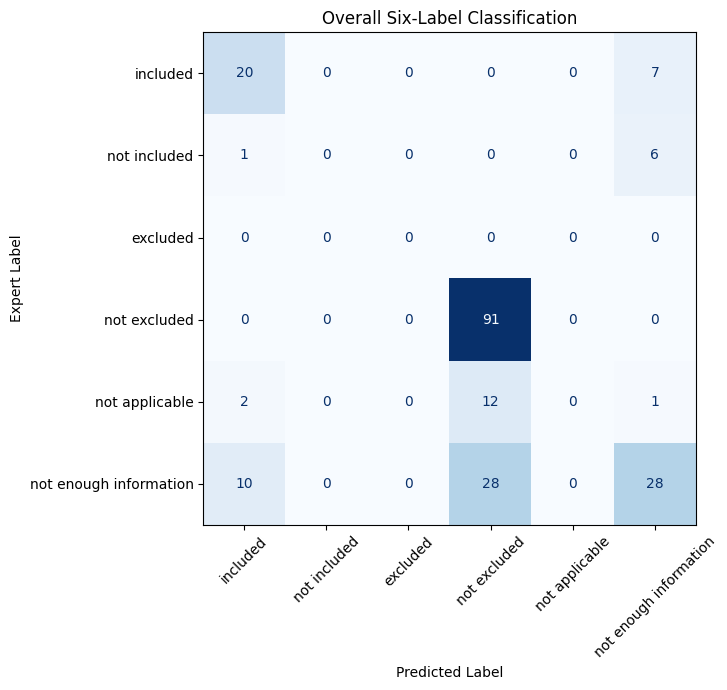


Overall Six-Label Classification
Records: 206
Saved: final_test_confusion_overall


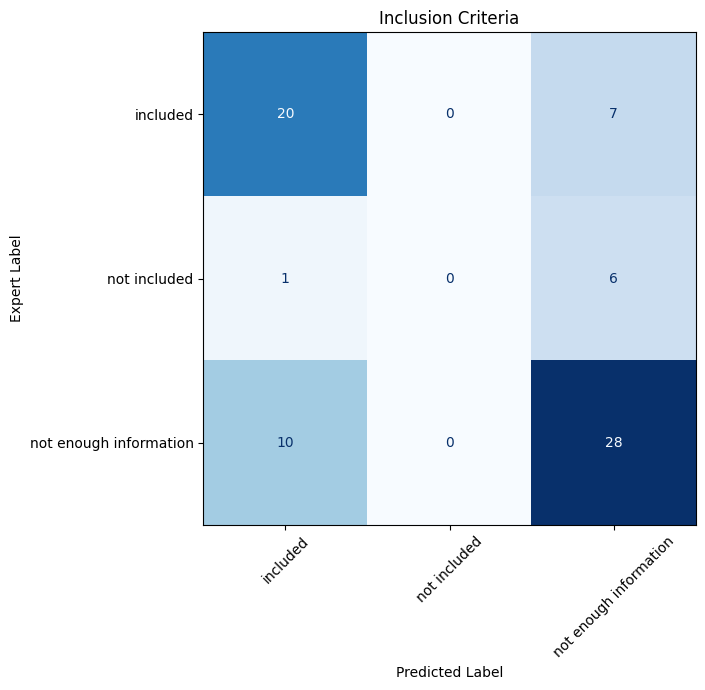


Inclusion Criteria
Records: 75
Saved: final_test_confusion_inclusion


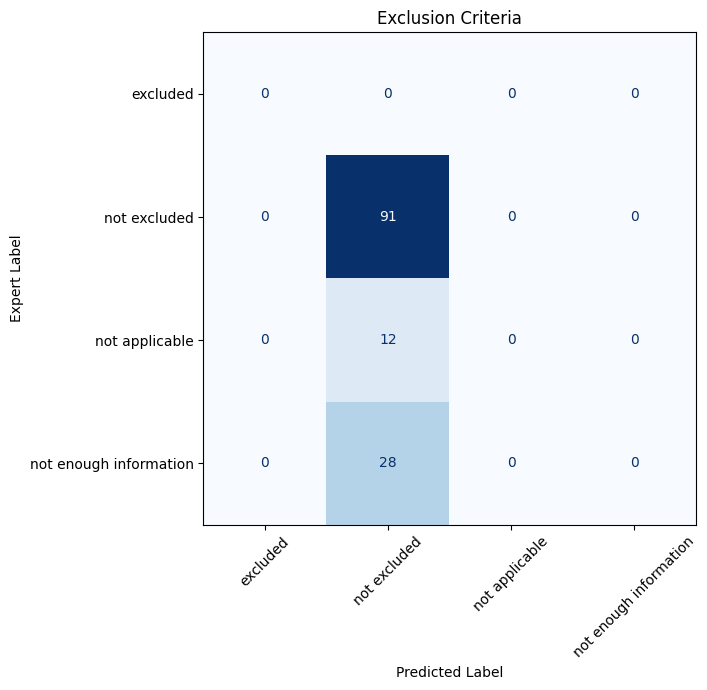


Exclusion Criteria
Records: 131
Saved: final_test_confusion_exclusion

STEP 85 COMPLETE!


In [22]:
# ============================================================
# STEP 85: Final Test Confusion Matrices
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("FINAL TEST CONFUSION MATRICES")
print("=" * 70)

figures_dir = PROJECT_DIR / "figures"
results_dir = PROJECT_DIR / "results"

figures_dir.mkdir(parents=True, exist_ok=True)

matrix_configs = [
    (
        "Overall Six-Label Classification",
        test_eval,
        ALL_LABELS,
        "final_test_confusion_overall"
    ),
    (
        "Inclusion Criteria",
        test_eval[test_eval["criterion_type"] == "inclusion"],
        [
            "included",
            "not included",
            "not enough information"
        ],
        "final_test_confusion_inclusion"
    ),
    (
        "Exclusion Criteria",
        test_eval[test_eval["criterion_type"] == "exclusion"],
        [
            "excluded",
            "not excluded",
            "not applicable",
            "not enough information"
        ],
        "final_test_confusion_exclusion"
    )
]

for title, subset, labels, filename in matrix_configs:

    # Include INVALID as a predicted category if present.
    matrix_labels = labels.copy()

    if (subset["predicted_label"] == "INVALID").any():
        matrix_labels.append("INVALID")

    cm = confusion_matrix(
        subset["label"],
        subset["predicted_label"],
        labels=matrix_labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=matrix_labels,
        columns=matrix_labels
    )

    cm_df.to_csv(
        results_dir / f"{filename}.csv"
    )

    fig, ax = plt.subplots(figsize=(10, 7))

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=matrix_labels
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        xticks_rotation=45
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Expert Label")

    plt.tight_layout()

    plt.savefig(
        figures_dir / f"{filename}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print(f"\n{title}")
    print("Records:", len(subset))
    print("Saved:", filename)

print("\nSTEP 85 COMPLETE!")

In [23]:
# ============================================================
# STEP 86: Final Test Evidence Retrieval Metrics
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

import json
import numpy as np
import pandas as pd

print("FINAL TEST EVIDENCE EVALUATION")
print("=" * 70)

evidence_rows = []

for _, row in test_eval.iterrows():

    gold = set(int(x) for x in row["evidence_ids"])
    predicted = set(
        int(x) for x in row["predicted_evidence_ids"]
    )

    tp = len(gold & predicted)
    fp = len(predicted - gold)
    fn = len(gold - predicted)

    if tp + fp > 0:
        precision = tp / (tp + fp)
    else:
        precision = 0.0

    if tp + fn > 0:
        recall = tp / (tp + fn)
    else:
        recall = 0.0

    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0.0

    empty_both = len(gold) == 0 and len(predicted) == 0

    evidence_rows.append({
        "annotation_id": int(row["annotation_id"]),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "empty_both": empty_both,
        "exact_match": gold == predicted
    })

evidence_df = pd.DataFrame(evidence_rows)

total_tp = int(evidence_df["tp"].sum())
total_fp = int(evidence_df["fp"].sum())
total_fn = int(evidence_df["fn"].sum())

micro_precision = (
    total_tp / (total_tp + total_fp)
    if total_tp + total_fp else 0.0
)

micro_recall = (
    total_tp / (total_tp + total_fn)
    if total_tp + total_fn else 0.0
)

micro_f1 = (
    2 * micro_precision * micro_recall
    / (micro_precision + micro_recall)
    if micro_precision + micro_recall else 0.0
)

macro_precision = float(evidence_df["precision"].mean())
macro_recall = float(evidence_df["recall"].mean())
macro_f1_strict = float(evidence_df["f1"].mean())

macro_f1_empty_one = float(
    evidence_df["f1"].where(
        ~evidence_df["empty_both"],
        1.0
    ).mean()
)

nonempty_cases = evidence_df[
    ~evidence_df["empty_both"]
]

macro_f1_nonempty = (
    float(nonempty_cases["f1"].mean())
    if len(nonempty_cases) else 0.0
)

exact_match_rate = float(
    evidence_df["exact_match"].mean()
)

evidence_summary = {
    "test_records": len(evidence_df),
    "tp": total_tp,
    "fp": total_fp,
    "fn": total_fn,
    "micro_precision": micro_precision,
    "micro_recall": micro_recall,
    "micro_f1": micro_f1,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1_strict": macro_f1_strict,
    "macro_f1_empty_empty_one": macro_f1_empty_one,
    "macro_f1_nonempty_union": macro_f1_nonempty,
    "exact_evidence_match": exact_match_rate,
    "empty_empty_cases": int(
        evidence_df["empty_both"].sum()
    )
}

evidence_df.to_csv(
    results_dir / "final_test_evidence_per_record.csv",
    index=False
)

with open(
    results_dir / "final_test_evidence_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(evidence_summary, f, indent=2)

print("\nMICRO EVIDENCE METRICS")
print("=" * 70)
print(f"Precision: {micro_precision:.4f}")
print(f"Recall:    {micro_recall:.4f}")
print(f"F1:        {micro_f1:.4f}")

print("\nMACRO EVIDENCE METRICS")
print("=" * 70)
print(f"Precision:               {macro_precision:.4f}")
print(f"Recall:                  {macro_recall:.4f}")
print(f"F1 (strict):             {macro_f1_strict:.4f}")
print(f"F1 (empty/empty = 1):    {macro_f1_empty_one:.4f}")
print(f"F1 (nonempty union):     {macro_f1_nonempty:.4f}")

print("\nADDITIONAL RESULTS")
print("=" * 70)
print(f"Exact evidence match:    {exact_match_rate:.4f}")
print(f"Empty/empty cases:       {evidence_summary['empty_empty_cases']}")
print(f"TP={total_tp}, FP={total_fp}, FN={total_fn}")

print("\nSTEP 86 COMPLETE!")

FINAL TEST EVIDENCE EVALUATION

MICRO EVIDENCE METRICS
Precision: 0.5263
Recall:    0.4255
F1:        0.4706

MACRO EVIDENCE METRICS
Precision:               0.1707
Recall:                  0.1575
F1 (strict):             0.1601
F1 (empty/empty = 1):    0.7620
F1 (nonempty union):     0.4021

ADDITIONAL RESULTS
Exact evidence match:    0.7427
Empty/empty cases:       124
TP=40, FP=36, FN=54

STEP 86 COMPLETE!


In [24]:
# ============================================================
# STEP 87: Select and Inspect Detailed Test Error Cases
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

import re
import json
import pandas as pd

print("DETAILED TEST ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Extract numbered patient sentences
# ------------------------------------------------------------

def extract_numbered_sentences(patient_text):

    sentences = {}

    for line in str(patient_text).splitlines():

        match = re.match(r"^\s*(\d+)\.\s+(.+)$", line.strip())

        if match:
            sentences[int(match.group(1))] = match.group(2)

    return sentences


# ------------------------------------------------------------
# 2. Identify classification and evidence errors
# ------------------------------------------------------------

error_df = test_eval.copy()

error_df["classification_error"] = (
    error_df["label"] != error_df["predicted_label"]
)

error_df["evidence_error"] = error_df.apply(
    lambda row: (
        set(row["evidence_ids"])
        != set(row["predicted_evidence_ids"])
    ),
    axis=1
)

error_df["error_type"] = error_df.apply(
    lambda row: (
        "Both"
        if row["classification_error"] and row["evidence_error"]
        else "Classification"
        if row["classification_error"]
        else "Evidence"
        if row["evidence_error"]
        else "Correct"
    ),
    axis=1
)

print("\nERROR COUNTS")
print("=" * 70)

print("Classification errors:",
      int(error_df["classification_error"].sum()))

print("Evidence mismatches:",
      int(error_df["evidence_error"].sum()))

print("Both errors:",
      int((
          error_df["classification_error"]
          & error_df["evidence_error"]
      ).sum()))

print("\nERROR TYPE DISTRIBUTION")
print(error_df["error_type"].value_counts())

# ------------------------------------------------------------
# 3. Select diverse error cases
# ------------------------------------------------------------

errors_only = error_df[
    error_df["classification_error"]
    | error_df["evidence_error"]
].copy()

errors_only["confusion"] = (
    errors_only["label"].astype(str)
    + " -> "
    + errors_only["predicted_label"].astype(str)
)

# Select one example from each distinct confusion pattern.
selected_indices = []

for _, group in errors_only[
    errors_only["classification_error"]
].groupby("confusion", sort=True):

    selected_indices.append(group.index[0])

# Include evidence-only errors.
evidence_only = errors_only[
    ~errors_only["classification_error"]
    & errors_only["evidence_error"]
]

if len(evidence_only):
    selected_indices.append(evidence_only.index[0])

# Add additional examples until we have at least 8.
for idx in errors_only.index:

    if len(selected_indices) >= 8:
        break

    if idx not in selected_indices:
        selected_indices.append(idx)

selected = errors_only.loc[selected_indices].head(
    max(8, len(selected_indices))
).copy()

# ------------------------------------------------------------
# 4. Build evidence-grounded case records
# ------------------------------------------------------------

detailed_cases = []

for case_number, (_, row) in enumerate(
    selected.iterrows(), start=1
):

    sentences = extract_numbered_sentences(
        row["patient_text"]
    )

    gold_ids = [int(x) for x in row["evidence_ids"]]
    predicted_ids = [
        int(x) for x in row["predicted_evidence_ids"]
    ]

    gold_text = [
        f"{i}. {sentences[i]}"
        for i in gold_ids if i in sentences
    ]

    predicted_text = [
        f"{i}. {sentences[i]}"
        for i in predicted_ids if i in sentences
    ]

    case = {
        "case_number": case_number,
        "annotation_id": int(row["annotation_id"]),
        "patient_id": str(row["patient_id"]),
        "criterion_type": str(row["criterion_type"]),
        "criterion": str(row["criterion_text"]),
        "gold_label": str(row["label"]),
        "predicted_label": str(row["predicted_label"]),
        "gold_evidence_ids": gold_ids,
        "predicted_evidence_ids": predicted_ids,
        "gold_evidence_text": gold_text,
        "predicted_evidence_text": predicted_text,
        "classification_error": bool(
            row["classification_error"]
        ),
        "evidence_error": bool(row["evidence_error"]),
        "error_type": row["error_type"],
        "raw_model_output": str(row["raw_model_output"])
    }

    detailed_cases.append(case)

# ------------------------------------------------------------
# 5. Save detailed error cases
# ------------------------------------------------------------

cases_path = (
    PROJECT_DIR / "results" / "final_test_detailed_errors.json"
)

with open(cases_path, "w", encoding="utf-8") as f:
    json.dump(
        detailed_cases,
        f,
        indent=2,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 6. Display cases for interpretation
# ------------------------------------------------------------

for case in detailed_cases:

    print("\n" + "=" * 70)
    print("CASE", case["case_number"])
    print("=" * 70)

    print("Annotation:", case["annotation_id"])
    print("Type:", case["criterion_type"])
    print("Criterion:", case["criterion"])

    print("\nExpert label:", case["gold_label"])
    print("Model label:", case["predicted_label"])
    print("Error type:", case["error_type"])

    print("\nEXPERT EVIDENCE:")
    print(
        "\n".join(case["gold_evidence_text"])
        or "(No expert evidence sentences)"
    )

    print("\nMODEL EVIDENCE:")
    print(
        "\n".join(case["predicted_evidence_text"])
        or "(No model evidence sentences)"
    )

print("\nSaved:", cases_path)
print("Detailed cases:", len(detailed_cases))
print("\nSTEP 87 COMPLETE!")

DETAILED TEST ERROR ANALYSIS

ERROR COUNTS
Classification errors: 67
Evidence mismatches: 53
Both errors: 23

ERROR TYPE DISTRIBUTION
error_type
Correct           109
Classification     44
Evidence           30
Both               23
Name: count, dtype: int64

CASE 1
Annotation: 185
Type: inclusion
Criterion: Patients were included if they were diagnosed with Shock, Acute respiratory distress syndrome (ARDS), or both.

Expert label: included
Model label: not enough information
Error type: Both

EXPERT EVIDENCE:
2. On examination she is pale and in moderate discomfort, as well as tachypneic and tachycardic.
3. Her body temperature is normal and her blood pressure is 80/60.

MODEL EVIDENCE:
0. A 40-year-old woman with no past medical history presents to the ER with excruciating pain in her right arm that had started 1 hour prior to her admission.

CASE 2
Annotation: 422
Type: inclusion
Criterion: If female, using birth control

Expert label: not applicable
Model label: included
Error type

In [25]:
# ============================================================
# STEP 88: Add Grounded Explanations to Detailed Error Cases
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

import json
import pandas as pd

print("GROUNDED ERROR EXPLANATIONS")
print("=" * 70)

error_explanations = {
    185: (
        "The expert annotation identifies shock-related evidence: "
        "tachypnea, tachycardia, and hypotension (80/60). "
        "The model predicts insufficient information and cites "
        "the presenting arm pain instead. This indicates failure "
        "to connect the clinical signs with the shock criterion."
    ),

    422: (
        "The expert labels this birth-control criterion as "
        "'not applicable'. The model instead predicts 'included' "
        "and cites the patient's age rather than the expert's "
        "sentence about sexual history and menstruation. "
        "The model fails to reproduce the expert's applicability "
        "judgment and selects irrelevant evidence."
    ),

    745: (
        "The expert assigns 'not applicable', whereas the model "
        "predicts 'not enough information'. Neither identifies "
        "an evidence sentence. This is an applicability-versus-"
        "insufficient-information classification error. The "
        "available evidence does not establish why the expert "
        "considered the criterion inapplicable."
    ),

    165: (
        "For the pregnancy exclusion criterion, the expert "
        "assigns 'not applicable', but the model predicts "
        "'not excluded'. Both evidence sets are empty. "
        "The model confuses an inapplicable criterion with "
        "an exclusion condition that is not met. The displayed "
        "evidence does not establish the expert's rationale."
    ),

    306: (
        "The expert identifies a ruptured liver abscess treated "
        "with surgical drainage. This does not establish that "
        "the patient requires extended hepatic resection. "
        "The model predicts 'included' and cites an unrelated "
        "informed-consent sentence, suggesting both criterion "
        "misinterpretation and irrelevant evidence selection."
    ),

    169: (
        "The exclusion criterion requires a pre-operative "
        "glomerular filtration rate below 30. The expert "
        "assigns 'not enough information', but the model "
        "predicts 'not excluded'. Neither provides evidence. "
        "The model treats the absence of a documented low "
        "filtration rate as evidence that the exclusion "
        "condition is not met."
    ),

    836: (
        "The criterion requires asthma-consistent symptoms "
        "or a diagnosis after age six. The patient is four "
        "years old and has no previous wheezing history. "
        "The model predicts 'included', apparently focusing "
        "on the current wheezing episode while overlooking "
        "the age restriction. It also cites additional "
        "sentences beyond the expert evidence."
    ),

    161: (
        "The expert labels the elective carotid endarterectomy "
        "criterion 'not included', while the model predicts "
        "'not enough information'. Both evidence sets are "
        "empty. This reflects a disagreement between a "
        "negative eligibility judgment and an uncertainty "
        "judgment. The displayed evidence is insufficient "
        "to determine the precise reason for the disagreement."
    ),

    179: (
        "The model correctly predicts 'not excluded' but "
        "omits the expert's evidence sentence. The patient "
        "underwent cardiac catheterization through the "
        "femoral artery, while the exclusion criterion concerns "
        "prior central venous puncture or catheterization. "
        "This is an evidence retrieval failure rather than "
        "a classification error."
    )
}

for case in detailed_cases:

    annotation_id = case["annotation_id"]

    case["grounded_error_explanation"] = (
        error_explanations.get(
            annotation_id,
            "Explanation requires manual review."
        )
    )

# ------------------------------------------------------------
# Save complete detailed cases
# ------------------------------------------------------------

output_json = (
    PROJECT_DIR / "results" /
    "final_test_detailed_errors_explained.json"
)

output_csv = (
    PROJECT_DIR / "results" /
    "final_test_detailed_errors_explained.csv"
)

with open(output_json, "w", encoding="utf-8") as f:
    json.dump(
        detailed_cases,
        f,
        indent=2,
        ensure_ascii=False
    )

pd.DataFrame(detailed_cases).to_csv(
    output_csv,
    index=False
)

# ------------------------------------------------------------
# Display explanations
# ------------------------------------------------------------

for case in detailed_cases:

    print("\n" + "=" * 70)
    print(
        f"CASE {case['case_number']} "
        f"| Annotation {case['annotation_id']}"
    )
    print("=" * 70)

    print("Expert:", case["gold_label"])
    print("Model:", case["predicted_label"])

    print("\nExplanation:")
    print(case["grounded_error_explanation"])

print("\nSaved JSON:", output_json)
print("Saved CSV:", output_csv)
print("Total explained cases:", len(detailed_cases))

print("\nSTEP 88 COMPLETE!")

GROUNDED ERROR EXPLANATIONS

CASE 1 | Annotation 185
Expert: included
Model: not enough information

Explanation:
The expert annotation identifies shock-related evidence: tachypnea, tachycardia, and hypotension (80/60). The model predicts insufficient information and cites the presenting arm pain instead. This indicates failure to connect the clinical signs with the shock criterion.

CASE 2 | Annotation 422
Expert: not applicable
Model: included

Explanation:
The expert labels this birth-control criterion as 'not applicable'. The model instead predicts 'included' and cites the patient's age rather than the expert's sentence about sexual history and menstruation. The model fails to reproduce the expert's applicability judgment and selects irrelevant evidence.

CASE 3 | Annotation 745
Expert: not applicable
Model: not enough information

Explanation:
The expert assigns 'not applicable', whereas the model predicts 'not enough information'. Neither identifies an evidence sentence. This is 

In [26]:
# ============================================================
# STEP 89: Verify Final Task 2 Deliverables
# TASK 2: Final Evaluation and Error Analysis
# ============================================================

import json
from pathlib import Path

print("TASK 2 FINAL COMPLETENESS CHECK")
print("=" * 70)

required_files = {
    "Held-out test dataset":
        "data/test_processed.jsonl",

    "Raw test predictions":
        "results/finetuned_test_predictions.jsonl",

    "Final test evaluation":
        "results/final_test_evaluation.jsonl",

    "Classification metrics":
        "results/final_test_classification_metrics.json",

    "Per-class classification report":
        "results/final_test_classification_report.csv",

    "Overall confusion matrix":
        "figures/final_test_confusion_overall.png",

    "Inclusion confusion matrix":
        "figures/final_test_confusion_inclusion.png",

    "Exclusion confusion matrix":
        "figures/final_test_confusion_exclusion.png",

    "Evidence retrieval metrics":
        "results/final_test_evidence_metrics.json",

    "Per-record evidence metrics":
        "results/final_test_evidence_per_record.csv",

    "Explained error cases (JSON)":
        "results/final_test_detailed_errors_explained.json",

    "Explained error cases (CSV)":
        "results/final_test_detailed_errors_explained.csv"
}

missing_files = []

for description, relative_path in required_files.items():

    path = PROJECT_DIR / relative_path

    if path.is_file() and path.stat().st_size > 0:
        print(f"[PASS] {description}")
    else:
        print(f"[MISSING] {description}")
        missing_files.append(relative_path)

print("\n" + "=" * 70)

# Check explained error cases
error_path = (
    PROJECT_DIR / "results" /
    "final_test_detailed_errors_explained.json"
)

if error_path.exists():
    with open(error_path, "r", encoding="utf-8") as f:
        cases = json.load(f)

    print("Detailed error cases:", len(cases))
    assert len(cases) >= 8

# Check classification metrics
metrics_path = (
    PROJECT_DIR / "results" /
    "final_test_classification_metrics.json"
)

if metrics_path.exists():
    with open(metrics_path, "r", encoding="utf-8") as f:
        metrics = json.load(f)

    print("Test records:", metrics["test_records"])
    print("Accuracy:", round(metrics["accuracy"], 4))
    print("Macro-F1:", round(metrics["macro_f1"], 4))

print("\nMissing files:", len(missing_files))

if not missing_files:
    print("\nALL TASK 2 FINAL EVALUATION FILES VERIFIED!")
else:
    print("\nSome files require attention.")

print("\nSTEP 89 COMPLETE!")

TASK 2 FINAL COMPLETENESS CHECK
[PASS] Held-out test dataset
[PASS] Raw test predictions
[PASS] Final test evaluation
[PASS] Classification metrics
[PASS] Per-class classification report
[PASS] Overall confusion matrix
[PASS] Inclusion confusion matrix
[PASS] Exclusion confusion matrix
[PASS] Evidence retrieval metrics
[PASS] Per-record evidence metrics
[PASS] Explained error cases (JSON)
[PASS] Explained error cases (CSV)

Detailed error cases: 9
Test records: 206
Accuracy: 0.6748
Macro-F1: 0.3342

Missing files: 0

ALL TASK 2 FINAL EVALUATION FILES VERIFIED!

STEP 89 COMPLETE!


In [1]:
# STEP 99: Package the trained LoRA adapter for local inference
# TASK 6: Transfer the existing trained model without retraining

from google.colab import drive, files
from pathlib import Path
import shutil

drive.mount("/content/drive")

adapter_dir = Path(
    "/content/drive/MyDrive/GenAI_Assignment_2/models/qwen_lora_final"
)

assert adapter_dir.exists(), f"Adapter not found: {adapter_dir}"

print("Adapter files:")
for file in adapter_dir.iterdir():
    print(file.name)

zip_path = shutil.make_archive(
    "/content/qwen_lora_final",
    "zip",
    root_dir=str(adapter_dir.parent),
    base_dir=adapter_dir.name
)

print("ZIP created:", zip_path)
files.download(zip_path)

Mounted at /content/drive
Adapter files:
README.md
adapter_model.safetensors
adapter_config.json
tokenizer_config.json
special_tokens_map.json
added_tokens.json
vocab.json
merges.txt
tokenizer.json
training_args.bin
ZIP created: /content/qwen_lora_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# Run this CELL in Google Colab after mounting Drive.
# It creates one ZIP of notebook/results/figures and excludes model weight files.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import drive, files

drive.mount('/content/drive')
root = Path('/content/drive/MyDrive/GenAI_Assignment_2')
out = Path('/content/GenAI_A2_colab_artifacts.zip')
allowed = {'.ipynb', '.json', '.jsonl', '.csv', '.png', '.jpg', '.jpeg', '.svg', '.txt', '.md', '.pdf'}
with ZipFile(out, 'w', ZIP_DEFLATED) as z:
    for folder in ('notebooks', 'results', 'figures'):
        for f in (root / folder).rglob('*') if (root / folder).exists() else []:
            if f.is_file() and f.suffix.lower() in allowed:
                z.write(f, f.relative_to(root))
print('Created', out, out.stat().st_size, 'bytes')
files.download(str(out))
# If your .ipynb is elsewhere in Drive, download it from Colab File > Download .ipynb
# and place it in the local notebooks/ directory.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Created /content/GenAI_A2_colab_artifacts.zip 1185948 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>